# WAAM bead morphology — measurement pipeline

Blue-light structured-light scan (Revopoint MINI) of a bead-on-plate coupon in,
bead geometry out: peak height, toe width and cross-sectional area per division,
plus a zone map of where the deposit meets tolerance.

Research stay EL-AD26-356, Landers Research Group, University of Notre Dame.

**What the pipeline does, in order**

| § | Step | Turns this | Into this |
|---|------|------------|-----------|
| 1 | Load the scan | binary PLY | `(N,3)` points in the scanner frame |
| 2 | Substrate plane, Z alignment | scanner frame | substrate normal along $+z$ |
| 3 | Reference bar, in-plane frame | arbitrary $x,y$ | $y$ along the travel direction |
| 4 | Height map | scattered points | regular 2.5D raster |
| 5 | Biaxial deformation model | warped plate | flat datum, measured distortion |
| 6 | Separation by surface gradient | height map | bead mask |
| 7 | Centreline and measurement | bead mask | per-division geometry |
| 8 | Results and zone map | per-division geometry | tables, plots, verdicts |
| 9 | Welding plan | process parameters | run sheet joined to the geometry |
| 10 | Caliper comparison | vernier readings | agreement statistics |

**How to run it.** Local Jupyter or VS Code, Python 3.10+, `numpy`, `scipy`,
`matplotlib`. Put the `.ply` next to the notebook (default `data/`), set
`SCAN_PLY` in the configuration cell, run section 1, read the two crop boxes off
the layout plot, then run the rest top to bottom.

**Conventions used throughout.** Length in mm, angle in degrees. Processing
functions return plain arrays and dicts; every function whose name starts with
`plot_` only draws. One methodology per step — where an alternative exists, the
reason for the choice is stated in the text, not implemented as a second path.

## 0. Configuration

Every tunable number in the pipeline is here. Three groups behave differently:

* **Scene geometry** (`PLATE_BOX`, `BAR_BOX`, `EXCLUDE_BOXES`) changes with each
  scan and is read off the layout plot in section 1.
* **Physical constants** (`BAR_NOMINAL_MM`, `WIRE_DIA_MM`, `N_BEADS`) describe the
  hardware and change only when the setup changes.
* **Algorithm parameters** (thresholds, pitches) are tied to scanner noise and
  bead size; the section that uses each one explains what it trades off.
* **Per-scan settings** (`SCAN_SETTINGS`, at the end of the cell) replace any of
  the above for one scan. `SCAN` picks which, so the same notebook runs every
  scan of the series and each keeps its own crop and gates.

In [1]:
from itertools import permutations
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage, optimize, special, stats
from scipy.spatial import cKDTree
from skimage.segmentation import watershed

import csv

plt.rcParams.update({'figure.dpi': 110, 'font.size': 9, 'axes.grid': False})

In [2]:
# --- Files -----------------------------------------------------------------
SCAN_PLY = Path('data/nubec.ply')      # scan to analyse; set per scan at the end
                                       # of this cell, like every value that
                                       # changes from one scan to the next
OUT_DIR = Path('output')               # tables written by sections 8-10
CALIPER_CSV = OUT_DIR / 'caliper_measurements.csv'

# --- Scene geometry, in the LEVELLED frame of section 2 (mm) ---------------
# Read both boxes off the layout plot in section 1 and re-run. Boxes are
# axis-aligned, so leave a few mm of margin: the workpiece is normally a few
# degrees off axis in the scan.
PLATE_BOX = None        # (x0, x1, y0, y1) region holding the plate; None = auto
PLATE_AUTO = True       # find the plate as the largest footprint at the datum
PLATE_BAND_MM = 1.5     # half-height of the band about the datum that is plate
PLATE_INSET_MM = 3.0    # trim off the plate rim, where clamps and edge noise live
PLATE_FLOOR_MM = 2.0    # inside the crop, anything this far below the datum is table
BAR_BOX = None          # (x0, x1, y0, y1) region holding the reference bar
EXCLUDE_BOXES = []      # regions to delete: clamps, fixtures, scanning aids

# --- Hardware --------------------------------------------------------------
ALIGN_SOURCE = 'plate'   # 'screws' (table fiducial), 'plate' (outline), 'bar';
                         # neither nubec.ply nor cloud0.ply has screws, and the
                         # plate is cropped by the scan, so the frame falls back
                         # to the bead ridges
FIDUCIAL_BOX = None     # region holding the three screws, read off the layout plot
FIDUCIAL_SEEDS = None   # approximate (x, y) of each fiducial ring in the levelled
                        # frame: (corner, side arm, vertical arm). Read them once off
                        # the layout plot. Example from cloud8.ply:
                        # [(-45.3, 19.6), (107.1, 14.7), (-48.5, -131.6)]
FIDUCIAL_AUTO = True        # find the rings without being told where they are
FIDUCIAL_CELL_MM = 0.5      # raster pitch used for ring detection only
FIDUCIAL_RADIUS_MM = (2.0, 7.0)   # plausible screw-head ring radius
FIDUCIAL_MIN_ARM_MM = 100.0 # shortest arm of the L worth trusting
FIDUCIAL_ARM_MM = 152.0     # nominal spacing between fiducial screws, from the fixture
FIDUCIAL_ARM_TOL_MM = 8.0   # how far a pair may sit from that and still be the pair
FIDUCIAL_SEARCH_MM = 9.0    # half-width of the box searched around each seed
FIDUCIAL_RISE_MM = 2.0      # how far the ring stands above its local surround
FIDUCIAL_LAYOUT = 'L'   # 'L' (origin + vertical + 90 deg side) or 'line' (collinear)
FIDUCIAL_ORIGIN_IDX = 0     # corner, auto-detected by geometry -- do not change
FIDUCIAL_VERTICAL_IDX = 1   # which of the other two is along robot-vertical:
FIDUCIAL_SIDE_IDX = 2       # set these two by looking at the layout plot once --
                             # the corner is automatic, but "which arm is which"
                             # looks identical from shape alone and cannot be
                             # inferred; swap 1 and 2 if the frame comes out
                             # rotated 90 deg from what the robot expects
SCREW_ANGLE_TOL_DEG = 3.0   # tolerance on the L's right angle at the origin
SCREW_Z_BAND = (1.5, 6.0)   # height band above the substrate where screw heads sit
SCREW_MIN_AREA_MM2 = 20.0   # smallest cluster accepted as a screw head
SCREW_SPACING_MM = None     # nominal spacing, for the scale check; None to skip
SCREW_FLATNESS_MM = 0.5     # collinearity tolerance across the three heads
ROBOT_FRONT = np.array([1.0, 0.0, 0.0])  # robot front in the levelled frame;
                                         # the screw line runs at 90 deg to it
PLATE_Z_BAND_MM = 1.0   # band around the substrate used to trace the plate outline
PLATE_MIN_ASPECT = 1.5  # below this the plate is too square to give a direction
FRAME_DISAGREE_DEG = 1.0  # plate-vs-bar disagreement worth a warning
BAR_NOMINAL_MM = 150.0  # certified length of the reference bar
BAR_Z_BAND_MM = 2.0     # keep points within this of the bar's median height
N_BEADS = 14            # measurable beads. The TS 236 in/min bead (B1) is a
                        # broken row of droplets and is not a bead to measure
PLATE_ID = 'plate-1'    # which scan this is; keys PLATE_BEADS and the results
                        # CSV. Two scans of one plate get two keys, so the rows
                        # of the first stay in the CSV when the second is run

# --- Plane fit (section 2) -------------------------------------------------
PLANE_TOL_MM = 0.20     # RANSAC inlier band: 10x scanner noise, 15x under a bead
Z_MAX_MM = 8.0          # points further than this from the substrate are not workpiece

# --- Height map (section 4) ------------------------------------------------
CELL_MM = 'auto'        # raster pitch in mm, or 'auto' to size it from the
                        # measured point density
CELL_TARGET_PTS = 3.0   # points per cell aimed for when CELL_MM is 'auto'
FILL_PX = 3             # largest hole bridged by nearest-neighbour fill, cells

# --- Deformation model (section 5) ----------------------------------------
SUBSTRATE_FRAC = 0.55   # fraction of cells treated as substrate when fitting
LOCAL_DATUM_MM = 6.0    # smoothing length of what the seven terms leave behind
PLAIN_SLOPE = 0.08      # mm/mm, above this a cell is not plain plate
PLAIN_MARGIN_MM = 1.0   # and neither is anything this close to such a cell

# --- Separation by gradient (section 6) ------------------------------------
SMOOTH_MM = 'auto'      # Gaussian smoothing in mm, or 'auto' for two cells,
                        # the least that smooths anything
SLOPE_TOE = 'auto'      # mm/mm, bead flank vs substrate, or 'auto' to set it
                        # above the substrate's own slope noise
SLOPE_TOE_OVER_P99 = 1.8   # how far above that noise 'auto' puts the threshold
SPLIT_TOUCHING = True   # watershed beads whose toes merge into one blob
CREST_MM = 1.60         # height a crest must reach to seed its own bead
CORE_MIN_MM2 = 30.0     # smallest crest core accepted as a seed
CLOSE_MM = 6.0          # closes the flat crest; keep well below bead spacing
OPEN_MM = 0.6           # deletes speckle
EDGE_GUARD_MM = 1.0     # ignore cells this close to a data boundary

# --- Bead identification and measurement (section 7) -----------------------
FRAGMENT_AREA_MIN = 20.0   # mm2, low floor so broken beads survive to the merge
MERGE_AXIS_DOT = 0.985     # |cos| between principal axes of two fragments
MERGE_PERP_MM = 3.0        # max lateral offset between their axes
MERGE_GAP_MM = 10.0        # max end-to-end gap; must be < real bead spacing
# h_min is the median height over a bead's footprint. With SPLIT_TOUCHING on, the
# watershed basin reaches out to the toe, which pulls that median well below the
# crest, so this gate sits lower than a bead's peak height would suggest.
# elong_max and frag_max are there to reject fixture, not beads: a threaded rod
# or a clamp edge inside the crop reads as a very long, very thin region,
# assembled from several disconnected pieces. The fragment count is what catches
# it; elong_max stays loose so a long wall run (170 mm at 9 mm wide is about 19)
# is still a bead.
BEAD_LIMITS = dict(area_min=150.0, elong_min=2.5, elong_max=40.0,
                   h_min=0.6, h_max=8.0, w_min=4.0, w_max=25.0,
                   length_min=25.0, length_max=280.0, frag_max=3)
N_DIV = 10                 # divisions per bead, equal arc length
SKIRT_MM = 2.5             # the cross-section is integrated this far past the mask,
                           # so the area does not depend on where the mask puts the toe
PATH_DS_MM = 0.25          # centreline resample pitch

# --- Zone map (section 8) --------------------------------------------------
ZONE_MM = 10.0             # side of a zone cell
HEIGHT_TOL_MM = 0.30       # a zone passes if its crest is within this of the
                           # bead's own mean crest height

# --- Welding plan (section 9) ---------------------------------------------
WIRE_DIA_MM = 1.0   # the Power Wave is set for 0.035 in (0.889 mm) wire, weld mode
                    # 11; check the spool label, the mass balance moves 26 %
TRAVEL_LEVELS = [5.0, 7.5, 10.0]    # mm/s
LAMBDA_LEVELS = [4.0, 5.5, 7.0]     # wire feed speed / travel speed
CTWD_MM = 8.5                       # 0.3 in stick-out + 0.035 in tip-to-plate gap
GAS_LPM = 15.0                      # shielding gas flow, held constant
BASELINE_RUNS = 3                   # repeats at the centre point, no control
STACK_REVERSE = False      # False numbers the stack from +x to -x. In nubec.ply the
                           # first bead welded is at +x: lambda against area
                           # correlates +0.86 that way and -0.17 the other
CROSS_ANGLE_DEG = 45.0     # beads turned more than this from the stack are numbered
                           # after it, top to bottom, as separate long beads
CROSS_BEAD_NAMES = ['B2', 'B3']    # long beads across the stack, top to bottom
BEAD_LAYOUT = 'stacked'    # 'stacked' = parallel beads side by side (numbered
                           # across the stack); 'quincunx' = 4 corners + centre
STACK_AXIS = 'auto'        # 'x' or 'y' to say which way the stack runs; 'auto' takes
                           # the axis along which the bead centres spread most
BEAD_NAMES = {}            # a name for a bead of the stack, by its number
PLAN_SEED = 7

# --- This scan -------------------------------------------------------------
# What changes from one scan to the next, in one place. These values replace
# the ones above, so going back to an earlier scan is a change of one name.
SCAN = 'decay'
SCAN_SETTINGS = {
    # plate-1, 30 Sep 2026: twelve short beads in a stack, B2 and B3 across them
    'nubec': dict(
        SCAN_PLY=Path('data/nubec.ply'), PLATE_ID='plate-1', N_BEADS=14,
        CROSS_BEAD_NAMES=['B2', 'B3']),
    # plate-1, 2 Oct 2026: the long-bead side, five lines running the same way
    'cloud0': dict(
        SCAN_PLY=Path('data/cloud0.ply'), PLATE_ID='plate-1b', N_BEADS=5,
        CROSS_BEAD_NAMES=[],
        PLATE_AUTO=False,
        PLATE_BOX=(-36.5, 40.0, -58.0, 70.5),   # the five lines, without the ends of
                                                # the short beads at the left edge
        CLOSE_MM=3.0,                           # the toes are 6 mm apart here
        MERGE_GAP_MM=14.0,                      # joins the three pieces of C
        BEAD_LIMITS=dict(BEAD_LIMITS, area_min=80.0, length_min=20.0),   # A is 20 mm
        STACK_AXIS='x',                         # A sits far below the others
        BEAD_NAMES={1: 'D', 2: 'C', 3: 'B3', 4: 'B2', 5: 'A'}),
    # plate-1b again, 7 Oct 2026: two lines of five schedules with the arc on
    # (voltage stepping down, wire feed stepping down) and three short beads
    'decay': dict(
        SCAN_PLY=Path('data/decay.ply'), PLATE_ID='plate-1c', N_BEADS=10,
        EXCLUDE_BOXES=[(-70.0, -22.0, -21.0, 120.0)],   # ends of the short beads of plate-1
        CROSS_BEAD_NAMES=['S13', 'V'],
        PLATE_INSET_MM=0.5,                     # W starts 2 mm from the plate edge
        BEAD_NAMES={1: 'C3', 2: 'D', 3: 'B2', 4: 'B3', 5: 'W', 6: 'C1', 7: 'A', 8: 'S12'},
        BEAD_LIMITS=dict(BEAD_LIMITS, area_min=60.0, length_min=15.0)),
}
globals().update(SCAN_SETTINGS[SCAN])

OUT_DIR.mkdir(parents=True, exist_ok=True)

## 1. Load the scan

**Theory.** A PLY file is a header in ASCII followed by one packed binary record
per vertex. Revo Scan writes `binary_little_endian` with `x y z` as `float32`,
usually followed by colour bytes. Reading the property list instead of assuming
a layout means colour, normals or confidence channels do not shift the
coordinates.

**Physical meaning.** The coordinates are millimetres in the *scanner* frame:
origin at the sensor, no relation to the plate or the robot. Nothing in that
frame is measurable yet — the plate is tilted, rotated and offset by however the
part happened to sit during the scan. Sections 2 and 3 fix that.

**Input.** One `.ply` file. **Output.** `points`, an `(N,3)` array in mm.

In [3]:
PLY_TYPES = {'char': 'i1', 'uchar': 'u1', 'short': 'i2', 'ushort': 'u2',
             'int': 'i4', 'uint': 'u4', 'float': 'f4', 'double': 'f8',
             'int8': 'i1', 'uint8': 'u1', 'int16': 'i2', 'uint16': 'u2',
             'int32': 'i4', 'uint32': 'u4', 'float32': 'f4', 'float64': 'f8'}


def load_ply(path):
    """Binary little-endian PLY -> (N,3) array of x, y, z in mm."""
    with open(path, 'rb') as f:
        header = b''
        while not header.endswith(b'end_header\n'):
            chunk = f.read(1)
            if not chunk:
                raise ValueError(f'{path}: no end_header, not a PLY file')
            header += chunk
        lines = header.decode('ascii', 'ignore').splitlines()
        if not any('binary_little_endian' in ln for ln in lines):
            raise ValueError(f'{path}: only binary little-endian PLY is supported')
        fields, n_vertex, in_vertex = [], 0, False
        for line in lines:
            word = line.split()
            if not word:
                continue
            if word[0] == 'element':
                in_vertex = word[1] == 'vertex'
                if in_vertex:
                    n_vertex = int(word[2])
            elif word[0] == 'property' and in_vertex:
                fields.append((word[2], PLY_TYPES[word[1]]))
        record = np.fromfile(f, dtype=np.dtype(fields), count=n_vertex)
    return np.stack([record['x'], record['y'], record['z']], axis=1).astype(float)


def inside_box(points, box):
    """Boolean mask for points inside an axis-aligned (x0, x1, y0, y1) box."""
    x0, x1, y0, y1 = box
    return ((points[:, 0] >= x0) & (points[:, 0] <= x1) &
            (points[:, 1] >= y0) & (points[:, 1] <= y1))


if not SCAN_PLY.exists():
    raise FileNotFoundError(
        f'{SCAN_PLY} not found. Export the scan from Revo Scan as a binary '
        f'little-endian .ply, put it there, and set SCAN_PLY.')

points = load_ply(SCAN_PLY)
print(f'{SCAN_PLY}')
print(f'points          {len(points):,}')
print(f'extent (mm)     x {np.ptp(points[:, 0]):.1f}   y {np.ptp(points[:, 1]):.1f}'
      f'   z {np.ptp(points[:, 2]):.1f}')

density = len(points) / float(np.ptp(points[:, 0]) * np.ptp(points[:, 1]))
if CELL_MM == 'auto':
    CELL_MM = round(float(np.sqrt(CELL_TARGET_PTS / density)), 2)
    print(f'cell size       {CELL_MM} mm, for {CELL_TARGET_PTS:.0f} points per '
          f'cell at {density:.1f} points/mm2')
else:
    print(f'cell size       {CELL_MM} mm by hand, {density * CELL_MM ** 2:.1f} '
          f'points per cell at {density:.1f} points/mm2')
    if density * CELL_MM ** 2 < 1.5:
        print('   Below about 1.5 points per cell the raster is mostly holes and '
              "the gradient is noise. Raise CELL_MM or set it to 'auto'.")
if SMOOTH_MM == 'auto':
    SMOOTH_MM = round(2 * CELL_MM, 2)
    print(f'smoothing       {SMOOTH_MM} mm, two cells')
elif SMOOTH_MM < CELL_MM:
    print(f"   SMOOTH_MM {SMOOTH_MM} is under one cell ({CELL_MM} mm), so it "
          "smooths nothing. Raise it or set it to 'auto'.")

data/decay.ply
points          418,105
extent (mm)     x 153.8   y 174.0   z 11.5
cell size       0.44 mm, for 3 points per cell at 15.6 points/mm2
smoothing       0.88 mm, two cells


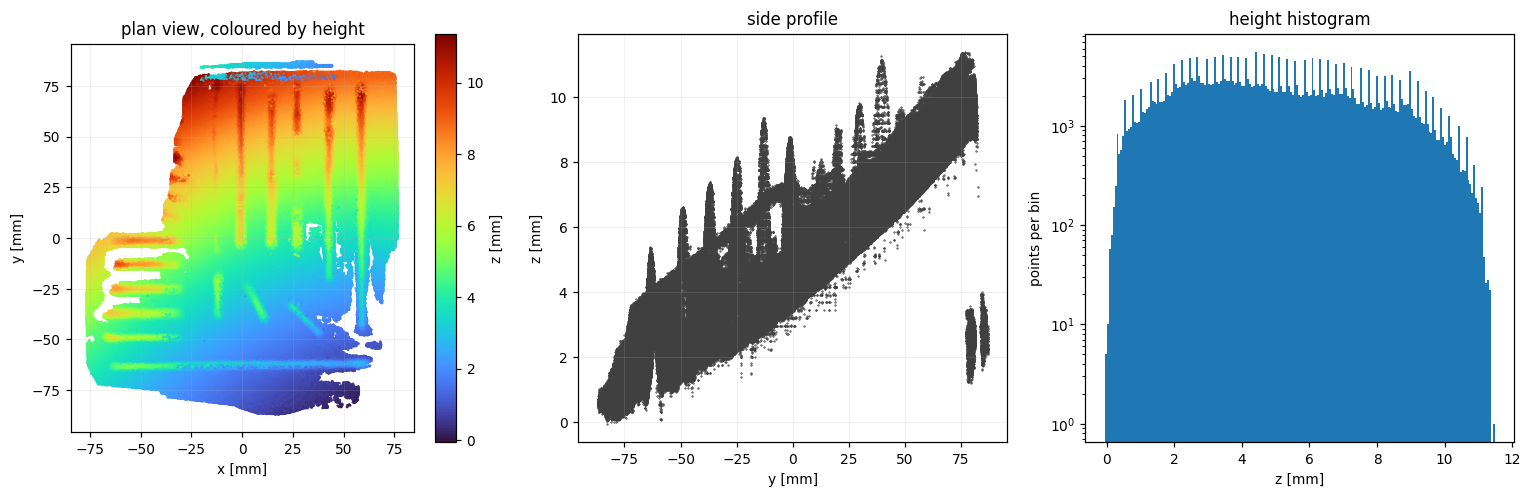

In [4]:
def plot_layout(points, seed=0, n_show=300_000):
    sample = points[np.random.default_rng(seed).choice(
        len(points), min(len(points), n_show), replace=False)]
    fig, ax = plt.subplots(1, 3, figsize=(14, 4.6))

    dots = ax[0].scatter(sample[:, 0], sample[:, 1], c=sample[:, 2], s=0.2, cmap='turbo')
    plt.colorbar(dots, ax=ax[0], label='z [mm]')
    ax[0].set_aspect('equal')
    ax[0].set_xlabel('x [mm]')
    ax[0].set_ylabel('y [mm]')
    ax[0].set_title('plan view, coloured by height')
    ax[0].grid(alpha=0.3, lw=0.4)

    ax[1].scatter(sample[:, 1], sample[:, 2], s=0.2, c='0.25')
    ax[1].set_xlabel('y [mm]')
    ax[1].set_ylabel('z [mm]')
    ax[1].set_title('side profile')
    ax[1].grid(alpha=0.3, lw=0.4)

    ax[2].hist(points[:, 2], bins=200)
    ax[2].set_yscale('log')
    ax[2].set_xlabel('z [mm]')
    ax[2].set_ylabel('points per bin')
    ax[2].set_title('height histogram')
    fig.tight_layout()
    plt.show()


plot_layout(points)

**How to read the layout plot.**

* *Plan view* — footprint of everything the scanner saw, in mm. Colour is raw
  height, so a smooth colour ramp across the plate is the tilt of the part in the
  scanner, not warp. This is the plot to read `PLATE_BOX`, `BAR_BOX` and
  `EXCLUDE_BOXES` off, but only after section 2 has levelled the cloud (the
  levelled version of this plot is drawn there, and the boxes refer to that one).
* *Side profile* — the plate appears as an inclined band a few mm thick. A second
  band 10 mm or more below it is the worktable.
* *Height histogram* — logarithmic counts. One dominant lobe is the workpiece;
  separate lobes are the table or fixturing.

**Good result:** one dominant surface, a clean footprint, sparse outliers.
**Problem:** two lobes of comparable size (the table is as sampled as the plate,
so the plane fit may lock onto the wrong one), or a smeared plan view, which
means the scan frames were merged badly and should be re-scanned rather than
cleaned up here.

## 2. Substrate plane and Z alignment

**Theory.** Least squares fitted to the whole cloud is dragged upward by the
beads, which are outliers with respect to the substrate. RANSAC ignores them by
construction: sample the minimum number of points that define a plane, count how
many points fall inside a band $\tau$ of it, keep the best hypothesis.

The number of trials for success probability $p$ with an inlier fraction $w$ is

$$N = \frac{\log(1-p)}{\log(1-w^{3})}$$

which for $w \approx 0.85$ and $p = 0.999$ gives $N \approx 8$. We run 200.

The winning hypothesis is then refined on its own inliers, using the eigenvector
of the smallest eigenvalue of their covariance:

$$C = \frac{1}{n}\sum (p_i - \bar p)(p_i - \bar p)^{\mathsf T},
\qquad n_{\text{plane}} = \arg\min_{\lVert v \rVert = 1} v^{\mathsf T} C\, v$$

This minimises *perpendicular* distance. Fitting $z = ax + by + c$ instead
minimises *vertical* distance, which is biased on a tilted plate — the error it
makes grows with the tilt it is supposed to measure.

**Physical meaning.** $n_{\text{plane}}$ is the substrate normal. Rotating it
onto $+z$ makes every later height a height *above the plate*, which is what a
caliper reads and what the process controls. Tilt is removed here; curvature is
not, because a plane cannot represent it — that is section 5's job.

**Inlier band.** $\tau = 0.20$ mm is an order of magnitude above scanner noise
($\approx 0.02$ mm) and an order of magnitude below bead height ($\approx 3.5$ mm),
so it accepts the substrate and rejects the deposit.

In [5]:
def fit_plane(points, tol_mm, iterations=200, seed=0, trial_size=50_000):
    '''RANSAC plane -> (unit normal, point on the plane, inlier count).'''
    rng = np.random.default_rng(seed)
    trial = points[rng.choice(len(points), min(len(points), trial_size), replace=False)]
    normal = anchor = None
    best = -1
    for _ in range(iterations):
        trio = trial[rng.choice(len(trial), 3, replace=False)]
        candidate = np.cross(trio[1] - trio[0], trio[2] - trio[0])
        length = np.linalg.norm(candidate)
        if length < 1e-9:
            continue
        candidate /= length
        votes = int((np.abs((trial - trio[0]) @ candidate) < tol_mm).sum())
        if votes > best:
            normal, anchor, best = candidate, trio[0], votes
    for _ in range(5):                      # total-least-squares refinement
        inliers = points[np.abs((points - anchor) @ normal) < tol_mm]
        anchor = inliers.mean(axis=0)
        normal = np.linalg.eigh(np.cov((inliers - anchor).T))[1][:, 0]
    return normal / np.linalg.norm(normal), anchor, len(inliers)


def rotation_to_z(normal):
    '''Smallest rotation taking `normal` onto +z (Rodrigues).'''
    target = np.array([0.0, 0.0, 1.0])
    axis = np.cross(normal, target)
    sin, cos = np.linalg.norm(axis), float(normal @ target)
    if sin < 1e-12:
        return np.eye(3) if cos > 0 else np.diag([1.0, -1.0, -1.0])
    skew = np.array([[0, -axis[2], axis[1]],
                     [axis[2], 0, -axis[0]],
                     [-axis[1], axis[0], 0]])
    return np.eye(3) + skew + skew @ skew * ((1 - cos) / sin ** 2)


plane_normal, plane_point, n_inliers = fit_plane(points, PLANE_TOL_MM)
tilt_deg = np.degrees(np.arccos(abs(plane_normal[2])))

plane_residual = (points - plane_point) @ plane_normal
levelled = (points - plane_point) @ rotation_to_z(plane_normal).T
levelled[:, 2] -= np.median(levelled[:, 2])
levelled = levelled[np.abs(levelled[:, 2]) < Z_MAX_MM]

print(f'plane normal    {np.round(plane_normal, 4)}')
print(f'tilt in scan    {tilt_deg:.2f} deg')
print(f'inliers         {n_inliers:,} of {len(points):,} ({100 * n_inliers / len(points):.0f}%)')
print(f'kept            {len(levelled):,} points within {Z_MAX_MM:.0f} mm of the substrate')

plane normal    [ 0.0271 -0.0457  0.9986]
tilt in scan    3.05 deg
inliers         124,564 of 418,105 (30%)
kept            418,105 points within 8 mm of the substrate


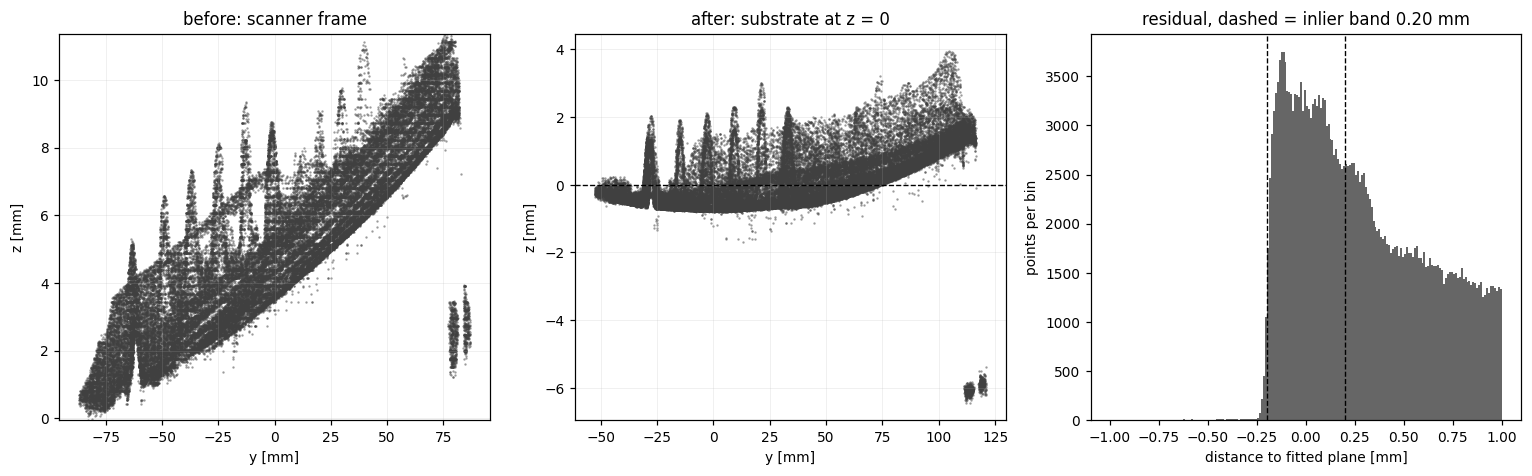

inside the band  30% of all points
substrate spread 1.95 mm (p5 to p95 within 2 mm of the plane)
That spread is the warp a plane cannot represent, not the error of the fit.


In [6]:
def plot_levelling(raw, levelled, residual, tol_mm, seed=1, n_show=60_000):
    rng = np.random.default_rng(seed)
    i_raw = rng.choice(len(raw), min(len(raw), n_show), replace=False)
    i_lev = rng.choice(len(levelled), min(len(levelled), n_show), replace=False)
    span = max(np.ptp(raw[i_raw, 2]), np.ptp(levelled[i_lev, 2]))

    fig, ax = plt.subplots(1, 3, figsize=(14, 4.4))
    for axis, (y, z, title) in zip(ax, [
            (raw[i_raw, 1], raw[i_raw, 2], 'before: scanner frame'),
            (levelled[i_lev, 1], levelled[i_lev, 2], 'after: substrate at z = 0')]):
        axis.scatter(y, z, s=0.3, c='0.25', alpha=0.5)
        middle = 0.5 * (z.min() + z.max())
        axis.set_ylim(middle - span / 2, middle + span / 2)   # same mm per pixel
        axis.set_xlabel('y [mm]')
        axis.set_ylabel('z [mm]')
        axis.set_title(title)
        axis.grid(alpha=0.3, lw=0.4)
    ax[1].axhline(0, color='k', lw=0.9, ls='--')

    inside = np.abs(residual) < 5 * tol_mm
    ax[2].hist(residual[inside], bins=200, color='0.4')
    for sign in (-1, 1):
        ax[2].axvline(sign * tol_mm, color='k', ls='--', lw=0.9)
    ax[2].set_xlabel('distance to fitted plane [mm]')
    ax[2].set_ylabel('points per bin')
    ax[2].set_title(f'residual, dashed = inlier band {tol_mm:.2f} mm')
    fig.tight_layout()
    plt.show()


plot_levelling(points, levelled, plane_residual, PLANE_TOL_MM)

near_plane = np.abs(plane_residual) < 2.0
low, high = np.percentile(plane_residual[near_plane], [5, 95])
print(f'inside the band  {100 * (np.abs(plane_residual) < PLANE_TOL_MM).mean():.0f}% of all points')
print(f'substrate spread {high - low:.2f} mm (p5 to p95 within 2 mm of the plane)')
print('That spread is the warp a plane cannot represent, not the error of the fit.')

**How to read the levelling plots.** All three are in mm.

* *Before / after* — the same points seen from the side, both panels drawn at the
  **same mm per pixel**, so the comparison is honest; autoscaling the right panel
  would magnify the leftover curvature and make a good fit look broken. The
  measured data are the grey points; the reference is the dashed line at $z = 0$.
  The correction is the rigid rotation between the panels.
* *Residual histogram* — perpendicular distance of every point to the fitted
  plane, with the $\pm\tau$ band dashed. This is the error of this step.

**Good result:** the plate is horizontal after the rotation; one dominant lobe
about zero with a tail to the right from the beads; a tilt of a few degrees.

**Problem:** a second lobe of comparable size (the table or a fixture is inside
the fit — crop it in `EXCLUDE_BOXES`); a flat, structureless residual
distribution (no plane dominates the scan); tilt above ~10 deg, which means the
fit locked onto something other than the plate. The residual spread itself is
*not* the error of this step: it contains the plate's warp, which a plane cannot
remove by construction, and section 5 deals with it.

## 3. In-plane frame from the plate, bar as fallback

**Theory.** Levelling fixes $z$ but leaves the rotation about $z$ arbitrary, and
every later quantity that mentions a direction — travel distance along a bead,
transverse offset, the zone grid — needs one.

The plate is clamped straight in the fixture, so the plate's own outline carries
that direction. The frame comes from the minimum-area rectangle of the substrate
footprint: over every edge of the convex hull, rotate the points onto that edge
and keep the rotation whose bounding box has the smallest area.

$$\theta^{*} = \arg\min_{\theta \in \text{hull edges}}
\; w(\theta)\, l(\theta)$$

The long side of that rectangle is the travel direction. A rectangle is recovered
exactly by this construction, so a clamped plate needs no separate artefact.

**Fallback.** A straight 150 mm reference bar beside the plate gives the same
direction independently, from the $2\times2$ covariance of its $(x,y)$ points:

$$C = \operatorname{cov}(x, y), \qquad
d = \text{eigenvector of the larger eigenvalue of } C$$

Not from an SVD of the point matrix: `np.linalg.svd` on an $N\times2$ array builds
the $N \times N$ factor, which is 7 GB at 31,000 points. The $2\times2$ covariance
gives the same direction for nothing.

Length is measured along that direction between percentiles rather than extremes:

$$L = t_{99.5} - t_{0.5}, \qquad t_i = (p_i - \bar p)\cdot d$$

**Physical meaning.** Direction and position behave very differently. The direction
is an average over the whole feature and barely moves if the ends are damaged —
10 mm of frayed tip shifts it by 0.009 deg. The extremes are exactly where scanning
artefacts live: loose cells a few mm past the true tip inflate the raw extent
(154.30 mm raw against 150.14 mm trimmed on `cloud9.ply`, nominal 150.00). So the
direction is taken from all the points and the length from the trimmed ones.

**Why the plate leads now.** The bar is an extra object to place, scan and crop on
every build, and its own straightness enters the frame. The clamped plate is
already in the scene and already constrained by the fixture. The bar stays for
**verification**: when both are present the notebook reports the disagreement
between the two directions, which is a direct check on the fixture. It also stays
as the **fallback** for when the plate outline is unreliable — occlusion, poor
contrast, or a plate too close to square for its long axis to be meaningful.

**Output.** A rotation about $z$ that puts travel along $+y$, the plate rectangle
it came from, and — when the bar is present — a direction cross-check and a scale
check against its certified length.

In [7]:
from scipy.spatial import ConvexHull


def ridge_direction(points, cell_mm=1.0, min_rise_mm=0.5):
    '''Travel direction of a set of parallel beads, from the beads alone.

    Across a bead the surface climbs to the crest and falls to the toe; along it
    the surface is nearly flat. So the gradient points across the beads, and
    averaging its orientation over the deposit -- the structure tensor, which
    counts a slope and its opposite as the same direction -- gives the across
    axis. Travel is perpendicular to it. Coherence is 1 when every slope agrees
    and 0 when they point every which way.'''
    origin = points[:, :2].min(axis=0)
    index = np.floor((points[:, :2] - origin) / cell_mm).astype(int)
    grid = np.full(tuple(index.max(axis=0) + 1), np.nan)
    np.fmax.at(grid, (index[:, 0], index[:, 1]), points[:, 2])
    filled = np.isfinite(grid)
    if filled.sum() < 100:
        return None, 0.0
    height = ndimage.gaussian_filter(np.where(filled, grid, 0.0), 1.5)
    gx, gy = np.gradient(height, cell_mm)
    use = filled & (height > min_rise_mm)
    if use.sum() < 50:
        return None, 0.0
    J = np.array([[np.sum(gx[use] ** 2), np.sum(gx[use] * gy[use])],
                  [np.sum(gx[use] * gy[use]), np.sum(gy[use] ** 2)]])
    values, vectors = np.linalg.eigh(J)
    across = vectors[:, 1]
    coherence = float((values[1] - values[0]) / (values[1] + values[0] + 1e-12))
    travel = np.array([-across[1], across[0]])
    if travel[1] < 0:
        travel = -travel
    return travel, coherence


def min_area_rect(xy):
    '''Minimum-area bounding rectangle by rotating calipers over hull edges.
    Returns (long-side unit direction, long side, short side, corners).'''
    hull = xy[ConvexHull(xy).vertices]
    edges = np.diff(np.vstack([hull, hull[:1]]), axis=0)
    best = None
    for edge in edges:
        norm = np.hypot(*edge)
        if norm < 1e-9:
            continue
        along = edge / norm
        across = np.array([-along[1], along[0]])
        u, v = hull @ along, hull @ across
        side_u, side_v = np.ptp(u), np.ptp(v)
        area = side_u * side_v
        if best is None or area < best[0]:
            best = (area, along, across, u.min(), u.max(), v.min(), v.max())
    _, along, across, u0, u1, v0, v1 = best
    corners = np.array([u0 * along + v0 * across, u1 * along + v0 * across,
                        u1 * along + v1 * across, u0 * along + v1 * across])
    side_u, side_v = u1 - u0, v1 - v0
    if side_u >= side_v:
        return along, float(side_u), float(side_v), corners
    return across, float(side_v), float(side_u), corners


def find_screw_heads(points, box, z_band, cell_mm, min_area_mm2, expected=3):
    '''Screw heads as raised clusters above the substrate. Returns their centres
    ordered along the line they form.'''
    region = points[inside_box(points, box)] if box else points
    lo, hi = z_band
    raised = region[(region[:, 2] > lo) & (region[:, 2] < hi)]
    if len(raised) < 50:
        return np.empty((0, 3))
    origin = raised[:, :2].min(axis=0)
    index = np.floor((raised[:, :2] - origin) / cell_mm).astype(int)
    occupied = np.zeros(index.max(axis=0) + 1, bool)
    occupied[index[:, 0], index[:, 1]] = True
    occupied = ndimage.binary_closing(occupied, np.ones((3, 3)))
    labels, n_labels = ndimage.label(occupied)
    big = [i for i in range(1, n_labels + 1)
           if (labels == i).sum() * cell_mm ** 2 >= min_area_mm2]
    keep = sorted(big, key=lambda i: -(labels == i).sum())[:expected]
    member = labels[index[:, 0], index[:, 1]]
    centres = np.array([raised[member == i].mean(axis=0) for i in keep])
    if len(centres) != 3:
        return centres
    # order by pairwise distance so index 0 is always the corner (shortest two
    # edges meet there), not by position -- position has no meaning for an L
    dist = np.linalg.norm(centres[:, None, :2] - centres[None, :, :2], axis=-1)
    edge_sum = dist.sum(axis=1)
    corner = int(np.argmin(edge_sum))
    others = [i for i in range(3) if i != corner]
    # the closer of the two remaining points is ambiguous by geometry alone;
    # FIDUCIAL_VERTICAL_IDX / FIDUCIAL_SIDE_IDX below resolve it against the
    # known physical layout, not against this ordering
    return np.array([centres[corner], centres[others[0]], centres[others[1]]])


def screw_quality(centres):
    '''Collinearity residual and the gaps between consecutive heads.'''
    centre, direction, offsets = fit_line_2d(centres[:, :2])
    along = np.sort((centres[:, :2] - centre) @ direction)
    return float(np.abs(offsets).max()), np.diff(along)


def frame_from_screws(centres, plane_normal, robot_front):
    '''Three collinear screws do not fix a frame on their own: rotation about
    their line is free. The substrate plane supplies that missing axis, so plane
    plus line is a complete frame. Returns the 4x4 transform.'''
    z_axis = plane_normal / np.linalg.norm(plane_normal)
    _, direction, _ = fit_line_2d(centres[:, :2])  # unit vector in the xy plane
    line = np.array([direction[0], direction[1], 0.0])
    y_axis = line - (line @ z_axis) * z_axis
    y_axis /= np.linalg.norm(y_axis)
    x_axis = np.cross(y_axis, z_axis)
    x_axis /= np.linalg.norm(x_axis)
    if x_axis @ robot_front < 0:      # keep x pointing along the robot front
        x_axis, y_axis = -x_axis, -y_axis
    rotation = np.column_stack([x_axis, y_axis, z_axis])
    transform = np.eye(4)
    transform[:3, :3] = rotation
    transform[:3, 3] = centres.mean(axis=0)
    return transform


def fit_circle_2d(xy):
    '''Algebraic circle fit. Returns centre, radius and the radial residuals.'''
    A = np.hstack([2 * xy, np.ones((len(xy), 1))])
    solution, *_ = np.linalg.lstsq(A, np.sum(xy ** 2, axis=1), rcond=None)
    centre = solution[:2]
    radius = float(np.sqrt(solution[2] + centre @ centre))
    return centre, radius, np.abs(np.linalg.norm(xy - centre, axis=1) - radius)


def find_fiducial_rings(points, exclude_box, cell_mm, rise_mm, radius_range,
                        max_fit_sd=0.4, min_samples=60):
    '''Locate every raised ring in the scene, without being told where to look.
    A fiducial screw head stands proud of the table it is bolted to, so it shows
    up as a compact cluster of cells above the local background whose points fit
    a circle tightly. Returns candidates sorted by fit quality.'''
    scene = points[~inside_box(points, exclude_box)] if exclude_box else points
    origin = scene[:, :2].min(axis=0)
    index = np.floor((scene[:, :2] - origin) / cell_mm).astype(int)
    shape = tuple(index.max(axis=0) + 1)
    top = np.full(shape, -np.inf)
    np.maximum.at(top, (index[:, 0], index[:, 1]), scene[:, 2])
    filled = np.isfinite(top) & (top > -np.inf)
    background = ndimage.median_filter(np.where(filled, top, 0.0),
                                       size=int(round(24.0 / cell_mm)) | 1)
    raised = filled & (top > background + rise_mm)
    raised = ndimage.binary_opening(raised, np.ones((3, 3)))
    labels, n_labels = ndimage.label(raised)
    lo, hi = radius_range
    found = []
    for index_label in range(1, n_labels + 1):
        blob = labels == index_label
        if blob.sum() * cell_mm ** 2 < np.pi * lo ** 2 * 0.3:
            continue
        rows, cols = np.where(blob)
        member = blob[index[:, 0], index[:, 1]]
        ring = scene[member]
        if len(ring) < min_samples:
            continue
        centre, radius, residual = fit_circle_2d(ring[:, :2])
        keep = residual < 0.6
        if keep.sum() < min_samples or not lo <= radius <= hi:
            continue
        centre, radius, residual = fit_circle_2d(ring[keep][:, :2])
        if residual.std() > max_fit_sd:
            continue
        found.append(dict(centre=np.array([centre[0], centre[1],
                                           ring[keep][:, 2].mean()]),
                          radius=float(radius), fit_sd=float(residual.std()),
                          samples=int(keep.sum())))
    return sorted(found, key=lambda f: f['fit_sd'])


def pick_L_triple(candidates, angle_tol_deg, min_arm_mm):
    '''From the candidate rings, the triple whose corner angle is closest to 90
    degrees. Returns (corner, side, vertical) or None.'''
    best = None
    n = len(candidates)
    for i in range(n):
        for j in range(n):
            for k in range(j + 1, n):
                if i in (j, k):
                    continue
                corner = candidates[i]['centre']
                arm_a = candidates[j]['centre'] - corner
                arm_b = candidates[k]['centre'] - corner
                len_a, len_b = np.linalg.norm(arm_a[:2]), np.linalg.norm(arm_b[:2])
                if min(len_a, len_b) < min_arm_mm:
                    continue
                angle = np.degrees(np.arccos(np.clip(
                    arm_a[:2] @ arm_b[:2] / (len_a * len_b), -1, 1)))
                error = abs(angle - 90.0)
                if error > angle_tol_deg:
                    continue
                score = min(len_a, len_b)      # prefer the widest L available
                if best is None or score > best[0]:
                    best = (score, i, j, k, angle, len_a, len_b)
    return best


def fit_fiducial_ring(points, near_xy, search_mm, rise_mm, trim_mm=0.6):
    '''One fiducial: the raised annulus of a screw head seated in the table.
    The ring centre is the screw axis -- fitting the whole ring beats picking a
    highest point, because the ring is many hundreds of samples wide.'''
    box = (np.abs(points[:, 0] - near_xy[0]) < search_mm) & \
          (np.abs(points[:, 1] - near_xy[1]) < search_mm)
    local = points[box]
    if len(local) < 200:
        return None
    floor = np.median(local[:, 2])
    ring = local[local[:, 2] > floor + rise_mm]
    if len(ring) < 60:
        return None
    centre, radius, residual = fit_circle_2d(ring[:, :2])
    keep = residual < trim_mm
    if keep.sum() < 40:
        return None
    centre, radius, residual = fit_circle_2d(ring[keep][:, :2])
    return dict(centre=np.array([centre[0], centre[1], ring[keep][:, 2].mean()]),
                radius=radius, fit_sd=float(residual.std()), samples=int(keep.sum()))


def frame_from_L(origin, vertical_point, side_point, robot_front):
    '''Three non-collinear points -- origin, a point along the robot's vertical
    direction, a point 90 deg from it -- fix a rigid frame on their own, no plane
    normal needed. FANUC's own 3-point frame method (SETUP > Frames) is this same
    construction; use it there if teaching the UF natively instead.'''
    y_axis = vertical_point - origin
    y_axis /= np.linalg.norm(y_axis)
    z_axis = np.cross(y_axis, side_point - origin)
    z_axis /= np.linalg.norm(z_axis)
    x_axis = np.cross(y_axis, z_axis)
    if x_axis @ robot_front < 0:      # keep x pointing along the robot front
        x_axis, z_axis = -x_axis, -z_axis
    rotation = np.column_stack([x_axis, y_axis, z_axis])
    transform = np.eye(4)
    transform[:3, :3] = rotation
    transform[:3, 3] = origin
    return transform


def plate_frame(points, z_band_mm, min_aspect, seed=0, n_show=200_000):
    '''Travel direction from the plate outline. Returns None when the footprint
    is too close to square for its long axis to mean anything.'''
    near = points[np.abs(points[:, 2] - np.median(points[:, 2])) < z_band_mm]
    if len(near) < 1000:
        return None
    sample = near[np.random.default_rng(seed).choice(
        len(near), min(len(near), n_show), replace=False)]
    direction, long_side, short_side, corners = min_area_rect(sample[:, :2])
    if short_side <= 0 or long_side / short_side < min_aspect:
        return None
    if direction[1] < 0:
        direction = -direction
    return direction, long_side, short_side, corners


def fit_line_2d(xy):
    '''Straight-feature fit -> (centroid, unit direction, perpendicular offsets).'''
    centre = xy.mean(axis=0)
    _, vectors = np.linalg.eigh(np.cov((xy - centre).T))
    direction = vectors[:, 1]
    if direction[1] < 0:
        direction = -direction                   # point it along +y
    across = np.array([-direction[1], direction[0]])
    return centre, direction, (xy - centre) @ across


def trimmed_length(along, trim_pct=0.5):
    low, high = np.percentile(along, [trim_pct, 100 - trim_pct])
    return float(high - low), (float(low), float(high))


def centreline_wander(along, perp, bin_mm=5.0):
    '''Spread of the bar's own centre from bin to bin: its straightness.'''
    n_bins = max(4, int(np.ptp(along) / bin_mm))
    edges = np.linspace(along.min(), along.max(), n_bins + 1)
    index = np.clip(np.digitize(along, edges) - 1, 0, n_bins - 1)
    mids, centres = [], []
    for k in range(n_bins):
        take = index == k
        if take.sum() > 20:
            mids.append(0.5 * (edges[k] + edges[k + 1]))
            centres.append(perp[take].mean())
    return np.array(mids), np.array(centres)


def rotation_about_z(direction):
    '''Rotation taking `direction` onto +y, leaving z untouched.'''
    dx, dy = direction
    return np.array([[dy, -dx, 0.0], [dx, dy, 0.0], [0.0, 0.0, 1.0]])


if BAR_BOX:
    bar = levelled[inside_box(levelled, BAR_BOX)]
    bar = bar[np.abs(bar[:, 2] - np.median(bar[:, 2])) < BAR_Z_BAND_MM]
    bar_centre, bar_dir, bar_perp = fit_line_2d(bar[:, :2])
    bar_along = (bar[:, :2] - bar_centre) @ bar_dir
    bar_length, bar_cut = trimmed_length(bar_along)
    bar_mids, bar_centres = centreline_wander(bar_along, bar_perp)
    print(f'bar points      {len(bar):,}')
    print(f'bar direction   {np.degrees(np.arctan2(bar_dir[0], bar_dir[1])):+.3f} deg from +y')
    print(f'length trimmed  {bar_length:.2f} mm   nominal {BAR_NOMINAL_MM:.2f} mm  '
          f'error {bar_length - BAR_NOMINAL_MM:+.2f} mm   (raw {np.ptp(bar_along):.2f})')
    print(f'straightness    {bar_centres.std():.4f} mm  (sd of its own centreline)')
else:
    bar = bar_dir = None

if FIDUCIAL_AUTO:
    candidates = find_fiducial_rings(levelled, PLATE_BOX, FIDUCIAL_CELL_MM,
                                     FIDUCIAL_RISE_MM, FIDUCIAL_RADIUS_MM)
    print(f'ring candidates {len(candidates)}')
    for ring in candidates[:20]:
        print(f'   ({ring["centre"][0]:8.2f}, {ring["centre"][1]:8.2f})  '
              f'r={ring["radius"]:.2f}  fit sd={ring["fit_sd"]:.3f}  n={ring["samples"]}')
    triple = pick_L_triple(candidates, SCREW_ANGLE_TOL_DEG, FIDUCIAL_MIN_ARM_MM)
    if triple is None and len(candidates) >= 2:
        # Two rings plus the substrate plane still fix the frame: the line between
        # them gives the in-plane direction, the plane supplies the axis normal to
        # it. Take the widest separated pair, which is least sensitive to the
        # centre error of either ring.
        centres = np.array([c['centre'] for c in candidates])
        spread = np.linalg.norm(centres[:, None, :2] - centres[None, :, :2], axis=-1)
        # The fixture's arm length is known, so use it: among all pairs take the
        # one whose separation matches it best. Picking the widest pair instead
        # lets two unrelated specks at opposite corners of the scan win.
        error = np.abs(spread - FIDUCIAL_ARM_MM)
        np.fill_diagonal(error, np.inf)
        i, j = np.unravel_index(np.argmin(error), error.shape)
        if error[i, j] > FIDUCIAL_ARM_TOL_MM:
            print(f'\nClosest ring pair is {spread[i, j]:.1f} mm apart, against a '
                  f'{FIDUCIAL_ARM_MM} mm arm: no pair matches the fixture.')
            screws = np.empty((0, 3))
        else:
            screws = np.array([centres[i], centres[j]])
            print(f'\nNo right-angled triple found. Using the ring pair whose '
                  f'separation matches the fixture arm: {spread[i, j]:.2f} mm '
                  f'against {FIDUCIAL_ARM_MM} nominal, plus the substrate plane.')
            print('That pair fixes the frame, but nothing cross-checks it: with '
                  'three rings the right angle is the check, with two there is none.')
    elif triple is None:
        print('Fewer than two rings found. Set FIDUCIAL_AUTO = False and give '
              'FIDUCIAL_SEEDS by hand, read off the layout plot.')
        screws = np.empty((0, 3))
    else:
        _, i, j, k, angle, len_a, len_b = triple
        screws = np.array([candidates[i]['centre'], candidates[j]['centre'],
                           candidates[k]['centre']])
        print(f'\nL triple picked: corner angle {angle:.2f} deg, '
              f'arms {len_a:.2f} and {len_b:.2f} mm')
elif FIDUCIAL_SEEDS:
    rings = [fit_fiducial_ring(levelled, seed, FIDUCIAL_SEARCH_MM, FIDUCIAL_RISE_MM)
             for seed in FIDUCIAL_SEEDS]
    if all(r is not None for r in rings):
        screws = np.array([r['centre'] for r in rings])
    else:
        print('Fiducial rings not found at the given seeds.')
        screws = np.empty((0, 3))
else:
    screws = find_screw_heads(levelled, FIDUCIAL_BOX, SCREW_Z_BAND, CELL_MM,
                              SCREW_MIN_AREA_MM2)
screw_frame = None
if len(screws) == 3 and FIDUCIAL_LAYOUT == 'L':
    origin = screws[FIDUCIAL_ORIGIN_IDX]
    side = screws[FIDUCIAL_SIDE_IDX]
    vertical = screws[FIDUCIAL_VERTICAL_IDX]
    dist_vertical = np.linalg.norm(vertical - origin)
    dist_side = np.linalg.norm(side - origin)
    right_angle = np.degrees(np.arccos(np.clip(
        (vertical - origin) @ (side - origin)
        / (dist_vertical * dist_side), -1, 1)))
    print(f'screw heads     3 found (L layout)')
    print(f'origin->vertical {dist_vertical:.2f} mm   origin->side {dist_side:.2f} mm')
    print(f'angle at origin  {right_angle:.2f} deg  (should be close to 90)')
    if abs(right_angle - 90) > SCREW_ANGLE_TOL_DEG:
        print(f'REJECTED: {abs(right_angle - 90):.1f} deg off square, above '
              f'{SCREW_ANGLE_TOL_DEG} deg tolerance. Check FIDUCIAL_ORIGIN_IDX / '
              'FIDUCIAL_VERTICAL_IDX / FIDUCIAL_SIDE_IDX match the physical screws.')
    else:
        screw_frame = frame_from_L(origin, vertical, side, ROBOT_FRONT)
elif len(screws) >= 2:
    flatness, gaps = screw_quality(screws)
    print(f'screw heads     {len(screws)} found')
    print(f'collinearity    {flatness:.3f} mm off their own line (max)')
    print(f'spacing         {np.round(gaps, 2)} mm'
          + (f'   nominal {SCREW_SPACING_MM}' if SCREW_SPACING_MM else ''))
    if SCREW_SPACING_MM:
        error = np.abs(gaps - SCREW_SPACING_MM).max()
        print(f'scale error     {error:+.2f} mm against nominal')
    if flatness > SCREW_FLATNESS_MM:
        print(f'REJECTED: {flatness:.2f} mm is above the {SCREW_FLATNESS_MM} mm '
              'collinearity tolerance. Something in the height band was taken for a '
              'screw. Set FIDUCIAL_BOX around the real screws; falling back.')
    else:
        screw_frame = frame_from_screws(screws, np.array([0.0, 0.0, 1.0]),
                                        ROBOT_FRONT)

found = plate_frame(levelled, PLATE_Z_BAND_MM, PLATE_MIN_ASPECT)

if ALIGN_SOURCE == 'screws' and screw_frame is not None:
    travel_dir = screw_frame[:2, 1]
    source = 'table screws'
elif ALIGN_SOURCE == 'plate' and found is not None:
    travel_dir, plate_long, plate_short, _ = found
    source = 'plate outline'
    print(f'plate rectangle {plate_long:.1f} x {plate_short:.1f} mm  '
          f'(aspect {plate_long / plate_short:.2f})')
elif found is not None:
    travel_dir, plate_long, plate_short, _ = found
    source = 'plate outline (fallback)'
    print(f'plate rectangle {plate_long:.1f} x {plate_short:.1f} mm')
elif bar_dir is not None:
    travel_dir, source = bar_dir, 'reference bar (fallback)'
    if found is None:
        print('Plate outline unusable (too square, or too few substrate points): '
              'falling back to the bar.')
else:
    ridge_dir, coherence = ridge_direction(levelled, cell_mm=1.0)
    if ridge_dir is None:
        raise RuntimeError(
            'No frame available: no screws found, the plate outline is too square, '
            'BAR_BOX is None, and the deposit shows no dominant direction. Set '
            'FIDUCIAL_BOX around the screws, or set BAR_BOX.')
    travel_dir, source = ridge_dir, f'bead ridges (coherence {coherence:.2f})'
    print('No screws, no usable plate outline and no bar: taking the travel '
          'direction from the beads themselves, perpendicular to the direction '
          'the surface slopes most.')
    if coherence < 0.3:
        print('   Coherence under 0.3: the slopes point every which way, so this '
              'direction is weak. Beads not all parallel, or mostly substrate.')

print(f'frame from      {source}, '
      f'{np.degrees(np.arctan2(travel_dir[0], travel_dir[1])):+.3f} deg from +y')

if screw_frame is not None:
    print('\nT_levelled<-fiducial (rotation and origin of the screw frame):')
    for row in np.round(screw_frame, 4):
        print('   ' + '  '.join(f'{v:9.4f}' for v in row))
    print('Compose with the robot-side pose of the same screws to reach the robot '
          'frame. The scanner side of that pair is this matrix.')

if found is not None and bar_dir is not None:
    disagreement = np.degrees(np.arccos(np.clip(abs(found[0] @ bar_dir), -1, 1)))
    print(f'plate vs bar    {disagreement:.3f} deg apart')
    if disagreement > FRAME_DISAGREE_DEG:
        print(f'WARNING: above {FRAME_DISAGREE_DEG} deg. The plate is not clamped '
              'parallel to the bar, or one of the two features is mis-cropped.')

def plate_by_height(points, band_mm, cell_mm=1.0):
    '''The substrate sits at the datum after levelling; the table it rests on is
    millimetres below it. Take the band about zero, then keep its largest
    connected footprint, so the plate is found without hand-typed coordinates.'''
    band = points[np.abs(points[:, 2]) < band_mm]
    if len(band) < 1000:
        return None
    origin = band[:, :2].min(axis=0)
    index = np.floor((band[:, :2] - origin) / cell_mm).astype(int)
    occupied = np.zeros(tuple(index.max(axis=0) + 1), bool)
    occupied[index[:, 0], index[:, 1]] = True
    occupied = ndimage.binary_closing(occupied, np.ones((3, 3)))
    occupied = ndimage.binary_opening(occupied, np.ones((3, 3)))
    labels, n_labels = ndimage.label(occupied)
    if n_labels == 0:
        return None
    biggest = 1 + np.argmax([(labels == i).sum() for i in range(1, n_labels + 1)])
    member = labels[index[:, 0], index[:, 1]] == biggest
    inside = band[member]
    lo = np.percentile(inside[:, :2], 0.5, axis=0)
    hi = np.percentile(inside[:, :2], 99.5, axis=0)
    inset = PLATE_INSET_MM
    return (float(lo[0] + inset), float(hi[0] - inset),
            float(lo[1] + inset), float(hi[1] - inset))


if PLATE_BOX is None and PLATE_AUTO:
    PLATE_BOX = plate_by_height(levelled, PLATE_BAND_MM)
    if PLATE_BOX:
        print(f'plate box auto  x {PLATE_BOX[0]:.1f}..{PLATE_BOX[1]:.1f}   '
              f'y {PLATE_BOX[2]:.1f}..{PLATE_BOX[3]:.1f} mm')

plate = levelled[inside_box(levelled, PLATE_BOX)] if PLATE_BOX else levelled
# Anything well below the datum inside the crop is the table showing through a
# gap, not plate. Left in, it drags the deformation fit and flips the skewness
# test that decides which way is up.
dropped_below = int((plate[:, 2] < -PLATE_FLOOR_MM).sum())
plate = plate[plate[:, 2] > -PLATE_FLOOR_MM]
if dropped_below:
    print(f'dropped         {dropped_below:,} points more than {PLATE_FLOOR_MM} mm '
          'below the datum (table seen inside the plate box)')
for box in EXCLUDE_BOXES:
    plate = plate[~inside_box(plate, box)]
plate = plate @ rotation_about_z(travel_dir).T

print(f'plate points    {len(plate):,}')
print(f'plate extent    x {np.ptp(plate[:, 0]):.1f} mm   y {np.ptp(plate[:, 1]):.1f} mm')

ring candidates 6
   (   21.01,    34.28)  r=2.18  fit sd=0.170  n=221
   (    5.24,    35.31)  r=2.76  fit sd=0.170  n=270
   (  -30.27,    32.92)  r=2.39  fit sd=0.174  n=187
   (   65.04,   103.97)  r=3.00  fit sd=0.175  n=308
   (   49.40,   102.19)  r=2.55  fit sd=0.175  n=247
   (  -46.63,    20.76)  r=6.27  fit sd=0.183  n=160

Closest ring pair is 139.3 mm apart, against a 152.0 mm arm: no pair matches the fixture.
No screws, no usable plate outline and no bar: taking the travel direction from the beads themselves, perpendicular to the direction the surface slopes most.
   Coherence under 0.3: the slopes point every which way, so this direction is weak. Beads not all parallel, or mostly substrate.
frame from      bead ridges (coherence 0.14), +0.071 deg from +y
plate box auto  x -67.4..80.6   y -48.4..114.1 mm
dropped         2,966 points more than 2.0 mm below the datum (table seen inside the plate box)
plate points    340,379
plate extent    x 147.9 mm   y 162.6 mm


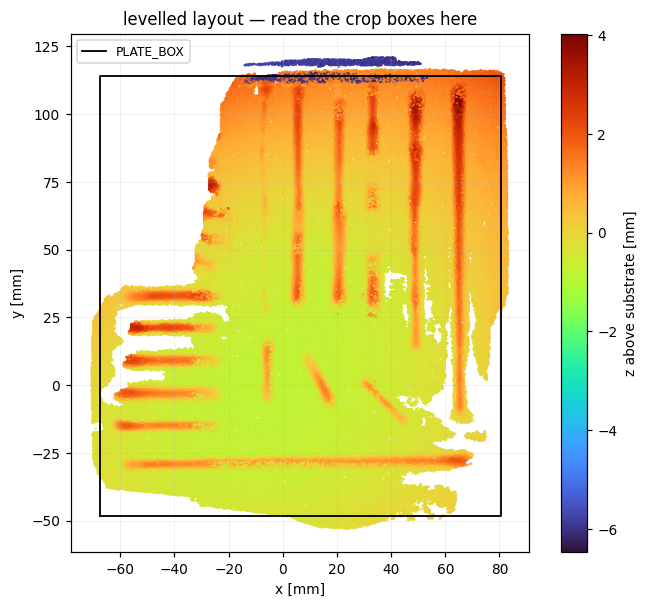

In [8]:
def plot_levelled_layout(levelled, plate_box, bar_box, seed=0, n_show=200_000):
    sample = levelled[np.random.default_rng(seed).choice(
        len(levelled), min(len(levelled), n_show), replace=False)]
    fig, axis = plt.subplots(figsize=(6.4, 5.6))
    dots = axis.scatter(sample[:, 0], sample[:, 1], c=sample[:, 2], s=0.2, cmap='turbo')
    plt.colorbar(dots, ax=axis, label='z above substrate [mm]')
    for box, colour, name in [(plate_box, 'k', 'PLATE_BOX'), (bar_box, 'r', 'BAR_BOX')]:
        if box:
            x0, x1, y0, y1 = box
            axis.plot([x0, x1, x1, x0, x0], [y0, y0, y1, y1, y0],
                      color=colour, lw=1.2, label=name)
    axis.set_aspect('equal')
    axis.set_xlabel('x [mm]')
    axis.set_ylabel('y [mm]')
    axis.set_title('levelled layout — read the crop boxes here')
    axis.grid(alpha=0.3, lw=0.4)
    if plate_box or bar_box:
        axis.legend(fontsize=8)
    fig.tight_layout()
    plt.show()


def plot_bar_fit(along, perp, mids, centres, cut, nominal):
    fig, ax = plt.subplots(1, 3, figsize=(14, 4.0))
    ax[0].scatter(along, perp, s=0.2, c='0.5')
    ax[0].axhline(0, color='k', lw=1.0, label='fitted line')
    for value in cut:
        ax[0].axvline(value, color='r', ls='--', lw=0.9)
    ax[0].set_xlabel('distance along the bar [mm]')
    ax[0].set_ylabel('offset across the bar [mm]')
    ax[0].set_title('bar points in its own frame')
    ax[0].legend(fontsize=8)

    ax[1].plot(mids, centres, 'k.-', lw=0.8, ms=4)
    ax[1].axhline(0, color='0.5', lw=0.8)
    ax[1].set_xlabel('distance along the bar [mm]')
    ax[1].set_ylabel('bin centre offset [mm]')
    ax[1].set_title(f'straightness, sd {centres.std():.4f} mm')

    ax[2].hist(along, bins=200, color='0.4')
    for value in cut:
        ax[2].axvline(value, color='r', ls='--', lw=0.9, label='trim')
    ax[2].set_yscale('log')
    ax[2].set_xlabel('distance along the bar [mm]')
    ax[2].set_ylabel('points per bin')
    ax[2].set_title(f'trimmed length {cut[1] - cut[0]:.2f} mm vs nominal {nominal:.2f} mm')
    for axis in ax:
        axis.grid(alpha=0.3, lw=0.4)
    fig.tight_layout()
    plt.show()


plot_levelled_layout(levelled, PLATE_BOX, BAR_BOX)
if bar is not None:
    plot_bar_fit(bar_along, bar_perp, bar_mids, bar_centres, bar_cut, BAR_NOMINAL_MM)

**How to read the bar plots.** Horizontal axis is distance along the bar, in mm.

* *Bar points in its own frame* — the measured data are the grey points; the
  fitted line is the horizontal axis by construction, so the vertical spread is
  the bar's width (8 mm of bar looks like $\pm4$ mm), not an error. The dashed red
  lines are the trim percentiles, i.e. where the length is measured.
* *Straightness* — each point is the mean offset of one 5 mm bin, so this is the
  bar's own centreline after the fit is removed. This is the residual of this
  step and the honest measure of straightness.
* *Length histogram* — point density along the bar. The bar body is a flat
  plateau; the low tails outside the dashed lines are loose cells at the tips.

**Good result:** straightness sd below ~0.05 mm; flat density with sharp
shoulders; trimmed length within a few tenths of nominal — that agreement is the
only scale check in the whole pipeline.

**Problem:** straightness with a smooth curve rather than scatter (the box caught
part of the plate or the fixture, or the bar itself is bent); trimmed length short
by millimetres (the box clips the bar — widen it); a length error above ~0.5 mm
with a clean fit, which points at scanner calibration and invalidates every
absolute number downstream until it is resolved.

## 4. Height map

**Theory.** Bead geometry is a function of position on the plate, so the cloud is
projected onto a regular grid keeping the **maximum** $z$ per cell — the top
surface, which is what a caliper touches. The pitch is set by point density: too
fine and most cells are empty, too coarse and the crest is averaged away. At
$\approx 100$ points/mm$^2$, 0.12 mm gives about 1.4 points per cell.

**Physical meaning.** The result is a 2.5D surface $h(x,y)$: one height per
position. Undercuts and the sides of an overhang cannot be represented, which is
correct for bead-on-plate and would not be for a multi-layer wall.

Empty cells are filled from the nearest neighbour, but only within `FILL_PX`
cells. Past that the gap is real missing data and is set to zero rather than
invented. The `valid` mask records which cells hold a genuine measurement, and
every fit downstream uses it — filled values must never enter a fit.

In [9]:
def rasterize(points, cell_mm, fill_px):
    '''Scattered points -> (height map, (x0, y0) of cell [0,0], valid mask).'''
    x, y, z = points[:, 0], points[:, 1], points[:, 2]
    x0, y0 = x.min(), y.min()
    nx = int(np.ceil((x.max() - x0) / cell_mm)) + 1
    ny = int(np.ceil((y.max() - y0) / cell_mm)) + 1
    ix = np.clip(((x - x0) / cell_mm).astype(int), 0, nx - 1)
    iy = np.clip(((y - y0) / cell_mm).astype(int), 0, ny - 1)

    flat = iy * nx + ix
    order = np.argsort(flat, kind='stable')
    keys, heights = flat[order], z[order]
    starts = np.flatnonzero(np.r_[True, keys[1:] != keys[:-1]])
    grid = np.full(nx * ny, np.nan)
    grid[keys[starts]] = np.maximum.reduceat(heights, starts)
    grid = grid.reshape(ny, nx)

    valid = np.isfinite(grid)
    if (~valid).any():
        distance, source = ndimage.distance_transform_edt(
            ~valid, return_distances=True, return_indices=True)
        filled = np.where(valid, grid, 0.0)
        grid = np.where(valid, filled,
                        np.where(distance > fill_px, 0.0, filled[tuple(source)]))
    return grid, (float(x0), float(y0)), valid


height_raw, grid_origin, valid = rasterize(plate, CELL_MM, FILL_PX)
n_rows, n_cols = height_raw.shape
extent = [grid_origin[0], grid_origin[0] + n_cols * CELL_MM,
          grid_origin[1], grid_origin[1] + n_rows * CELL_MM]
x_mm = grid_origin[0] + np.arange(n_cols) * CELL_MM
y_mm = grid_origin[1] + np.arange(n_rows) * CELL_MM
X_MM, Y_MM = np.meshgrid(x_mm, y_mm)

print(f'raster          {n_cols} x {n_rows} cells at {CELL_MM} mm')
print(f'real cells      {100 * valid.mean():.1f}%    filled {100 * (~valid).mean():.1f}%')
print(f'points per cell {len(plate) / valid.sum():.2f}')

raster          338 x 371 cells at 0.44 mm
real cells      66.3%    filled 33.7%
points per cell 4.09


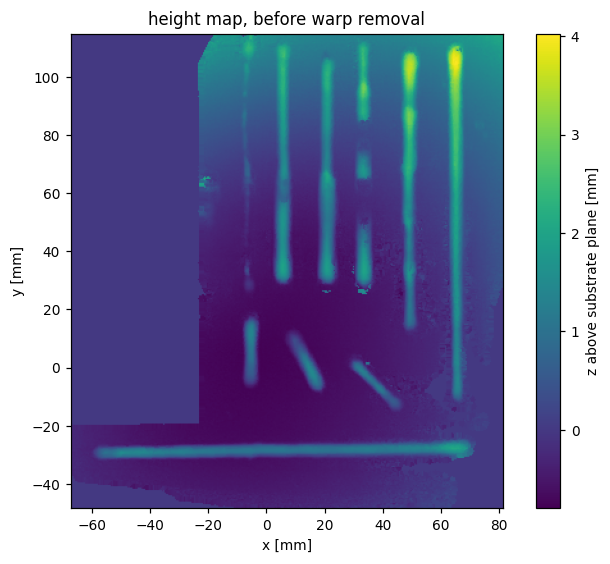

In [10]:
def plot_height_map(height, valid, extent, cell_mm):
    fig, ax = plt.subplots(figsize=(6.5, 5.2))
    image = ax.imshow(height, origin='lower', extent=extent, cmap='viridis',
                      aspect='equal')
    plt.colorbar(image, ax=ax, label='z above substrate plane [mm]')
    ax.set_xlabel('x [mm]')
    ax.set_ylabel('y [mm]')
    ax.set_title('height map, before warp removal')
    fig.tight_layout()
    plt.show()


plot_height_map(height_raw, valid, extent, CELL_MM)

**How to read the height map.** $x$ and $y$ in mm, colour in mm above the fitted
plane. At this point the beads are visible but the plate is not flat: the smooth
large-scale gradient across the map is warp that survived levelling, and it is
removed next.

The coverage bars give the share of cells with no measurement in each band across
the plate.

**Good result:** beads clearly separated from the substrate; coverage uniform and
below ~10% empty.

**Problem:** a strong coverage gradient means one end of the plate was scanned at
a poor angle, and beads there will be truncated whatever the grid settings —
rescan rather than compensate. Coverage above ~30% in any band makes that band's
numbers unusable.

## 5. Biaxial deformation model

**Theory.** Welding distorts the plate in both directions at once: it bends along
the beads, bends across them, and twists. A plane absorbs only the linear part.
Write the substrate as end displacements plus curvature plus twist, on normalised
coordinates $u$ across the plate and $v$ along it, both in $[0,1]$:

$$z(u,v) = \underbrace{(1-u)\,z_{u0} + u\,z_{u1}}_{\text{tilt across}}
+ \underbrace{(1-v)\,z_{v0} + v\,z_{v1}}_{\text{tilt along}}
+ \underbrace{4u(1-u)\,b_u + 4v(1-v)\,b_v}_{\text{bow}}
+ \underbrace{(2u-1)(2v-1)\,\theta}_{\text{twist}}$$

Seven terms spanning exactly the same space as a degree-2 polynomial
$\{1, u, v, u^2, uv, v^2\}$, which is six-dimensional. The extra dimension is not
free information: the design matrix has rank 6, and the direction
$(1,1,-1,-1,0,0,0)$ changes nothing. So the **absolute end displacements are not
uniquely recoverable, and only the tilt differences, the two bows and the twist
are**. `lstsq` returns the minimum-norm solution and the code reports only the
identifiable combinations:

$$\Delta_u = z_{u1} - z_{u0}, \qquad \Delta_v = z_{v1} - z_{v0}, \qquad b_u,\ b_v,\ \theta$$

**Physical meaning.** These are millimetres a machinist can check with a
straightedge, unlike polynomial coefficients. The split between sections 2 and 5
is exact: the tilt is linear so RANSAC removed it as a rigid rotation; the bow is
quadratic so a plane cannot see it and it survives to here.

**Fitting on substrate only.** The surface is fitted iteratively to the lowest
`SUBSTRATE_FRAC` of the residual among cells with real data, so the beads —
roughly a quarter of the area — do not lift the datum.

**What the seven terms leave.** A plate that has been welded on is not a
quadratic surface. Each bead pulls its own shallow trough, and what is left after
the seven-term fit is a slow residual of a few hundredths to a tenth of a
millimetre that changes from one bead to the next. Under a 6 mm wide bead, 0.05 mm
of datum is 0.3 mm², which is 8% of a small bead. So after the model, the level of
the *plain plate* is smoothed and carried under the beads as a weighted mean:

$$\ell(x,y) = \frac{\sum_i w_i\, r_i}{\sum_i w_i},\qquad
w_i = \exp\!\left(-\frac{d_i^2}{2\sigma^2}\right)$$

where the sum runs over plain-plate cells, $r_i$ is the residual of cell $i$ after
the seven-term fit [mm], $d_i$ its distance to $(x,y)$ [mm] and $\sigma$ is
`LOCAL_DATUM_MM`. Plain plate is every cell with a slope under `PLAIN_SLOPE` and
nothing steeper within `PLAIN_MARGIN_MM`. The seven terms stay as the description
of the distortion; $\ell$ is subtracted so that height is measured from the plate
beside each bead.

**Sign of $z$.** After levelling, "up" is ambiguous. The test removes the trend
without any masking and measures residual skewness

$$\gamma = \frac{1}{n}\sum \left(\frac{r_i - \bar r}{\sigma_r}\right)^3$$

Material added to a surface skews the residual positive whichever way the plate is
curved, which a test on the $z$ tails does not survive when the warp is larger
than the beads.

**Datum this defines.** Bead height is measured from the fitted substrate
extrapolated *underneath* the bead: reinforcement above the deformed plate as it
is now. Penetration and dilution are not visible to a surface scan.

In [11]:
DEFORMATION_TERMS = ['z_u0', 'z_u1', 'z_v0', 'z_v1', 'bow_u', 'bow_v', 'twist']


def deformation_basis(shape):
    '''Seven-column design matrix on normalised plate coordinates.'''
    n_rows, n_cols = shape
    v, u = np.mgrid[0:n_rows, 0:n_cols].astype(float)
    u /= max(n_cols - 1, 1)
    v /= max(n_rows - 1, 1)
    return np.stack([(1 - u).ravel(), u.ravel(), (1 - v).ravel(), v.ravel(),
                     (4 * u * (1 - u)).ravel(), (4 * v * (1 - v)).ravel(),
                     ((2 * u - 1) * (2 * v - 1)).ravel()], axis=1)


def material_points_up(height, valid):
    '''True if added material points to +z. Returns (up, skewness).'''
    basis = deformation_basis(height.shape)
    flat, ok = height.ravel(), valid.ravel()
    residual = (flat - basis @ np.linalg.lstsq(basis[ok], flat[ok], rcond=None)[0])[ok]
    skew = float(np.mean(((residual - residual.mean()) / residual.std()) ** 3))
    return skew >= 0, skew


def fit_deformation(height, valid, substrate_frac, n_iter=6):
    '''Iteratively reweighted substrate fit -> (surface, coefficients, mask).'''
    basis = deformation_basis(height.shape)
    flat, ok = height.ravel(), valid.ravel()
    mask, coefficients = ok.copy(), None
    for _ in range(n_iter):
        coefficients = np.linalg.lstsq(basis[mask], flat[mask], rcond=None)[0]
        residual = flat - basis @ coefficients
        lower = ok & (residual < np.percentile(residual[ok], 100 * substrate_frac))
        if lower.sum() < 10 * basis.shape[1] or (lower == mask).all():
            break
        mask = lower
    return (basis @ coefficients).reshape(height.shape), coefficients, mask.reshape(height.shape)


def data_support(valid, cell_mm, fill_px, guard_mm):
    '''Cells at least guard_mm inside the scanned area.'''
    square = np.ones((3, 3), bool)
    support = ndimage.binary_closing(valid, square, fill_px)
    return ndimage.binary_erosion(support, square, int(round(guard_mm / cell_mm)))


def local_datum(height, valid, cell_mm, smooth_mm, slope_max, margin_mm):
    '''What the seven terms leave behind, read off the plain plate and carried
    under the beads. Plain plate is every cell with no slope to speak of and
    nothing sloped within margin_mm; the level is its Gaussian-weighted mean.'''
    square = np.ones((3, 3), bool)
    inside = data_support(valid, cell_mm, FILL_PX, 1.5)
    d_dy, d_dx = np.gradient(ndimage.gaussian_filter(height, 1), cell_mm)
    sloped = (np.hypot(d_dx, d_dy) > slope_max) & inside
    sloped = ndimage.binary_fill_holes(ndimage.binary_closing(sloped, square, 2))
    plain = inside & ~ndimage.binary_dilation(sloped, square,
                                              int(round(margin_mm / cell_mm)))
    weight = ndimage.gaussian_filter(plain.astype(float), smooth_mm / cell_mm)
    level = ndimage.gaussian_filter(np.where(plain, height, 0.0), smooth_mm / cell_mm)
    return np.where(weight > 0.02, level / np.maximum(weight, 1e-9), 0.0), plain


def identifiable_deformation(coefficients):
    z_u0, z_u1, z_v0, z_v1, bow_u, bow_v, twist = coefficients
    return {'tilt across (u)': z_u1 - z_u0, 'tilt along (v)': z_v1 - z_v0,
            'bow across (u)': bow_u, 'bow along (v)': bow_v, 'twist': twist}


up, skewness = material_points_up(height_raw, valid)
height_signed = height_raw if up else -height_raw
substrate_surface, deformation_coef, substrate_mask = fit_deformation(
    height_signed, valid, SUBSTRATE_FRAC)
height_model = height_signed - substrate_surface
local_level, plain_plate = local_datum(height_model, valid, CELL_MM, LOCAL_DATUM_MM,
                                       PLAIN_SLOPE, PLAIN_MARGIN_MM)
height = height_model - local_level
datum_surface = substrate_surface + local_level

print(f'skewness        {skewness:+.2f}  ->  material points '
      f'{"+z" if up else "-z, cloud flipped"}')
print(f'\nresidual deformation after levelling (mm, identifiable terms only)')
for name, value in identifiable_deformation(deformation_coef).items():
    print(f'  {name:<16} {value:+.3f}')
print(f'\nleft by the seven terms   {np.ptp(local_level[plain_plate]):.2f} mm peak to peak '
      f'over the plain plate ({100 * plain_plate.sum() / valid.sum():.0f}% of real cells)')
print(f'plain plate sd            {height_model[plain_plate].std():.4f} mm before the '
      f'local datum, {height[plain_plate].std():.4f} mm after')
FLAT_BAND_MM = 0.2      # symmetric window for reporting substrate residuals
flat = valid & (np.abs(height) < FLAT_BAND_MM)
print(f'\nfitted surface range      {np.ptp(substrate_surface):.2f} mm')
print(f'substrate residual median {np.median(height[flat]):+.4f} mm')
print(f'substrate residual sd     {height[flat].std():.4f} mm')
flat_share = flat.sum() / valid.sum()
print(f'cells used as substrate   {100 * substrate_mask.mean():.0f}% in the fit, '
      f'{100 * flat_share:.0f}% of real cells within +/-{FLAT_BAND_MM} mm of the datum')
if flat_share < 0.5:
    print('\nWARNING: less than half the plate sits at the datum. Either the deposit '
          'covers it, or a tall object is distorting the fit — check EXCLUDE_BOXES.')

skewness        +2.11  ->  material points +z

residual deformation after levelling (mm, identifiable terms only)
  tilt across (u)  +0.457
  tilt along (v)   +1.455
  bow across (u)   -0.683
  bow along (v)    -1.000
  twist            -0.100

left by the seven terms   0.64 mm peak to peak over the plain plate (51% of real cells)
plain plate sd            0.1117 mm before the local datum, 0.0251 mm after

fitted surface range      2.70 mm
substrate residual median +0.0012 mm
substrate residual sd     0.0433 mm
cells used as substrate   36% in the fit, 78% of real cells within +/-0.2 mm of the datum


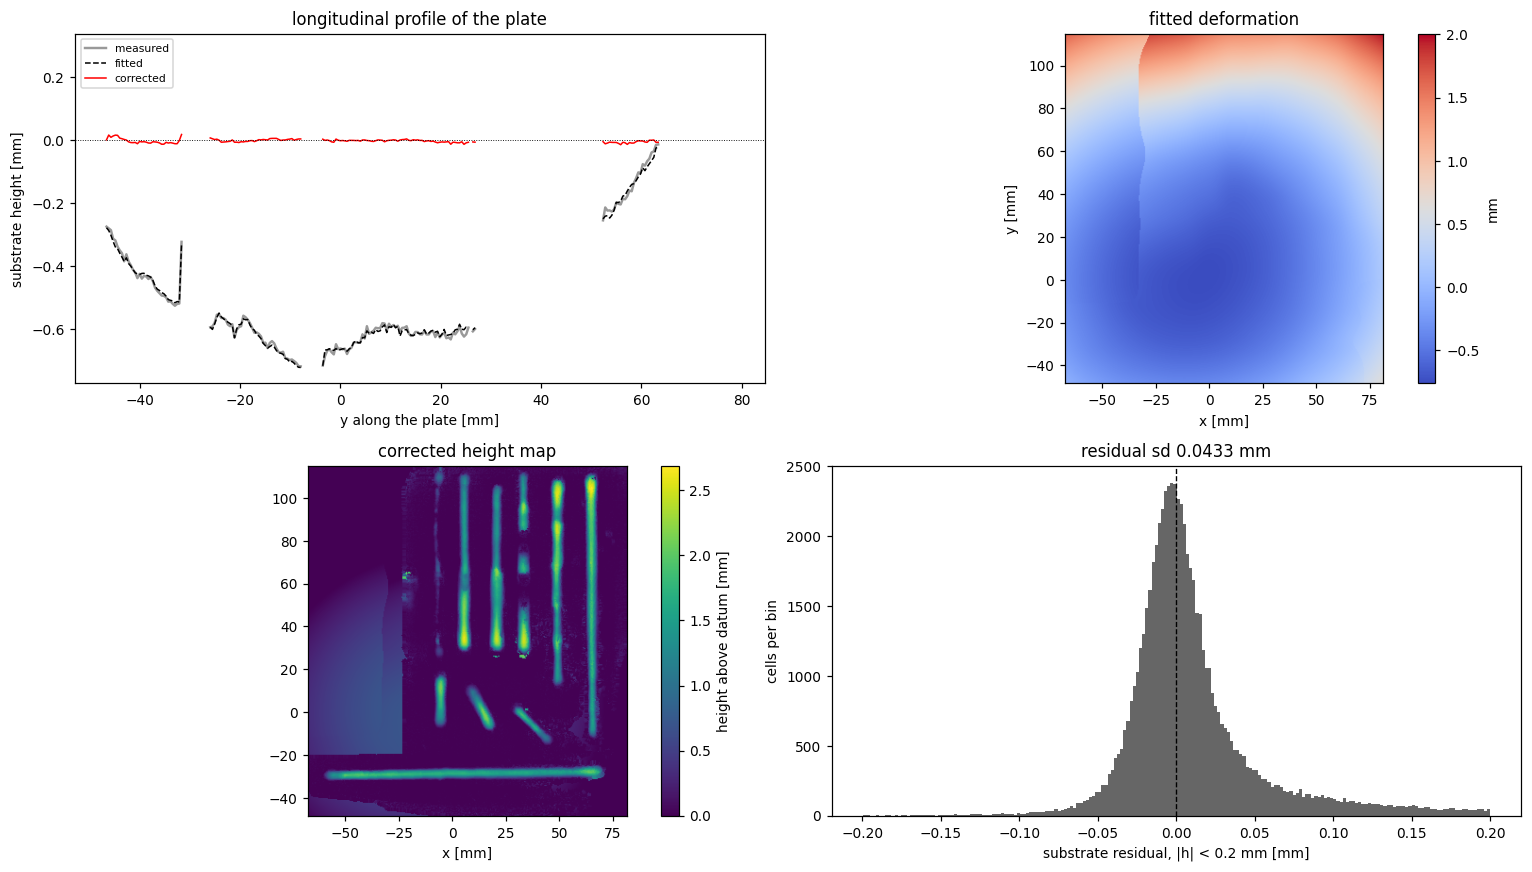

In [12]:
def substrate_profile(array, substrate_mask, along_rows=True, min_share=0.35):
    '''Median over substrate cells: one value per row, or per column. Lines with
    too few substrate cells are left empty rather than reporting a bead flank.'''
    values = array if along_rows else array.T
    mask = substrate_mask if along_rows else substrate_mask.T
    enough = mask.sum(axis=1) >= min_share * mask.shape[1]
    profile = np.full(mask.shape[0], np.nan)
    profile[enough] = np.nanmedian(np.where(mask[enough], values[enough], np.nan), axis=1)
    return profile


def plot_deformation(height_in, surface, height_out, substrate_mask, valid,
                     extent, cell_mm, band_mm):
    n_rows, n_cols = height_in.shape
    x_axis = extent[0] + np.arange(n_cols) * cell_mm
    y_axis = extent[2] + np.arange(n_rows) * cell_mm

    fig = plt.figure(figsize=(14, 8))
    ax_long = fig.add_subplot(2, 2, 1)
    for array, style, label in [(height_in, dict(color='0.6', lw=1.6), 'measured'),
                                (surface, dict(color='k', lw=1.0, ls='--'), 'fitted'),
                                (height_out, dict(color='r', lw=1.0), 'corrected')]:
        ax_long.plot(y_axis, substrate_profile(array, substrate_mask), **style,
                     label=label)
    ax_long.axhline(0, color='k', lw=0.6, ls=':')
    ax_long.set_xlabel('y along the plate [mm]')
    ax_long.set_ylabel('substrate height [mm]')
    ax_long.set_title('longitudinal profile of the plate')
    ax_long.legend(fontsize=7)

    ax_surface = fig.add_subplot(2, 2, 2)
    image = ax_surface.imshow(surface, origin='lower', extent=extent, cmap='coolwarm',
                              aspect='equal')
    plt.colorbar(image, ax=ax_surface, label='mm')
    ax_surface.set_title('fitted deformation')
    ax_surface.set_xlabel('x [mm]')
    ax_surface.set_ylabel('y [mm]')

    ax_corrected = fig.add_subplot(2, 2, 3)
    image = ax_corrected.imshow(np.clip(height_out, 0, None), origin='lower',
                                extent=extent, cmap='viridis', aspect='equal')
    plt.colorbar(image, ax=ax_corrected, label='height above datum [mm]')
    ax_corrected.set_title('corrected height map')
    ax_corrected.set_xlabel('x [mm]')

    ax_hist = fig.add_subplot(2, 2, 4)
    residual = height_out[valid & (np.abs(height_out) < band_mm)]
    ax_hist.hist(residual, bins=200, color='0.4')
    ax_hist.axvline(0, color='k', lw=0.9, ls='--')
    ax_hist.set_xlabel(f'substrate residual, |h| < {band_mm} mm [mm]')
    ax_hist.set_ylabel('cells per bin')
    ax_hist.set_title(f'residual sd {residual.std():.4f} mm')

    fig.tight_layout()
    plt.show()


plot_deformation(height_signed, datum_surface, height, substrate_mask, valid,
                 extent, CELL_MM, FLAT_BAND_MM)

**How to read the deformation figure.** All axes mm.

* *Profile* — the median height of the **substrate cells** in each row, so the
  beads are excluded and all three curves describe the plate itself: grey
  measured, dashed black the seven-term model, red the correction (measured minus
  model). Gaps appear where a row is entirely covered by a bead.
* *Fitted deformation* — the modelled plate shape, diverging colour about zero.
  Compare its sign and magnitude against the straightedge reading on the physical
  plate.
* *Corrected height map* — what every later step uses; the substrate should be
  uniformly dark.
* *Residual histogram* — the error of this step, over a symmetric window
  $|h| < 0.2$ mm around the datum, which excludes the deposit without truncating
  the distribution the way the fitting mask does. A wide or skewed histogram is
  deformation the model missed.

**Good result:** grey and dashed black lying on top of each other, red flat on
zero; residual median within a few hundredths of zero, sd of the order of scanner
noise, residual map speckled with no large-scale pattern outside the beads.

**Problem:** a saddle or a ridge left in the residual map (deformation beyond what
seven terms can describe, or a tall object such as a clamp inside the region —
put it in `EXCLUDE_BOXES`, since an object near a corner has maximum leverage on
the quadratic terms and on one real scan lifted the datum by 1.10 mm); residual sd
above ~0.1 mm; more than ~45% of the plate above the beads' toe, which means the
datum is wrong rather than the plate being covered.

## 6. Separating bead from plate by surface gradient

**Theory.** A height threshold asks "is this cell higher than $h_0$?", which is a
question about the *datum*, not about the bead. Any error in the datum — the
substrate fit off by $\delta$ — moves the apparent toe and changes every area and
width derived from it. The gradient asks "is this cell on a slope?", and slope is
a derivative, so an additive datum error cancels exactly:

$$s(x,y) = \lVert \nabla h \rVert = \sqrt{\left(\frac{\partial h}{\partial x}\right)^2
+ \left(\frac{\partial h}{\partial y}\right)^2},
\qquad \nabla (h + \delta) = \nabla h$$

Measured on one scan: a $+0.7$ mm datum error changes the cross-sectional area by
$+58\%$ if the bead is defined by height, and by $0\%$ if it is defined by
gradient.

**Physical meaning.** A weld bead meets the plate at a visible toe — a change of
slope, which is what the eye and the caliper jaws find. The crest itself is flat,
so the high-slope cells form a closed ring around each bead; morphological closing
bridges the crest and hole filling turns the ring into the footprint.

**Low beads.** A bead that never reaches `CREST_MM` has no crest core to seed the
watershed, and a piece of deposit with no seed is never flooded: it would vanish.
Every such piece seeds itself, so a low bead is kept and measured like the others.

**The three lengths that matter.** Smoothing (`SMOOTH_MM`) must be large enough
that differentiating does not amplify noise and small enough not to blur the toe:
it inflates the measured toe width by roughly one $\sigma$ per side, a systematic
offset the caliper comparison in section 10 will show. `CLOSE_MM` must exceed half
the flat crest width and stay well below bead spacing, or two beads merge.
`EDGE_GUARD_MM` drops cells near a data boundary, where smoothing mixes real
heights with filled values and manufactures a slope that is not on the part.

In [13]:
def slope_map(height, cell_mm, smooth_mm):
    '''Magnitude of the surface gradient, mm per mm.'''
    smoothed = ndimage.gaussian_filter(height, smooth_mm / cell_mm)
    d_dy, d_dx = np.gradient(smoothed, cell_mm)
    return np.hypot(d_dx, d_dy)


def data_interior(valid, cell_mm, fill_px, guard_mm):
    '''Cells far enough from a data boundary for the gradient to be real.'''
    square = np.ones((3, 3), bool)
    support = ndimage.binary_closing(valid, square, fill_px)
    return ndimage.binary_erosion(support, square, int(round(guard_mm / cell_mm)))


def bead_mask(slope, interior, cell_mm, slope_toe, close_mm, open_mm):
    '''High-slope ring -> filled bead footprint.'''
    square = np.ones((3, 3), bool)
    mask = (slope > slope_toe) & interior
    mask = ndimage.binary_closing(mask, square, int(round(close_mm / (2 * cell_mm))))
    mask = ndimage.binary_fill_holes(mask)
    return ndimage.binary_opening(mask, square, max(1, int(round(open_mm / (2 * cell_mm)))))


def split_touching_beads(deposit, height, interior, cell_mm, crest_mm, min_core_mm2):
    '''Beads laid close together share a toe, and closing the gradient ring then
    bridges neighbours into one blob. Watershed separates them: each bead has one
    connected crest above `crest_mm`, those crests seed the basins, and the
    boundary falls in the valley between beads where the surface is lowest.'''
    smoothed = ndimage.gaussian_filter(np.where(np.isfinite(height), height, 0.0),
                                       SMOOTH_MM / cell_mm)
    region = deposit | ((smoothed > crest_mm * 0.35) & interior)
    region = ndimage.binary_fill_holes(region)
    cores, n_cores = ndimage.label((smoothed > crest_mm) & interior)
    for index in range(1, n_cores + 1):
        if (cores == index).sum() * cell_mm ** 2 < min_core_mm2:
            cores[cores == index] = 0
    cores, n_kept = ndimage.label(cores > 0)
    # A bead too low to reach crest_mm has no core, and a piece of the region with
    # no core is never flooded: it would vanish. Such a piece seeds itself.
    pieces, n_pieces = ndimage.label(region)
    seeded = set(np.unique(pieces[cores > 0]))
    for index in range(1, n_pieces + 1):
        if index not in seeded:
            n_kept += 1
            cores[pieces == index] = n_kept
    if n_kept < 2:
        return deposit, n_kept
    return watershed(-smoothed, cores, mask=region), n_kept


slope = slope_map(height, CELL_MM, SMOOTH_MM)
interior = data_interior(valid, CELL_MM, FILL_PX, EDGE_GUARD_MM)

if SLOPE_TOE == 'auto':
    # The threshold has to clear the substrate's own slope noise, so measure that
    # first on a rough mask and put the real threshold above it.
    rough = bead_mask(slope, interior, CELL_MM, 0.30, CLOSE_MM, OPEN_MM)
    noise_p99 = float(np.percentile(slope[interior & ~rough], 99))
    SLOPE_TOE = round(SLOPE_TOE_OVER_P99 * noise_p99, 3)
    print(f'slope threshold   {SLOPE_TOE} = {SLOPE_TOE_OVER_P99} x substrate p99 '
          f'({noise_p99:.4f})')

deposit = bead_mask(slope, interior, CELL_MM, SLOPE_TOE, CLOSE_MM, OPEN_MM)

if SPLIT_TOUCHING:
    basins, n_cores = split_touching_beads(deposit, height, interior, CELL_MM,
                                           CREST_MM, CORE_MIN_MM2)
    if n_cores >= 2:
        deposit = basins > 0
        print(f'watershed         {n_cores} crest cores seeded, beads kept separate')
else:
    basins = None

substrate_slope = slope[interior & ~deposit]
print(f'substrate slope   median {np.median(substrate_slope):.4f}   '
      f'p99 {np.percentile(substrate_slope, 99):.4f}   threshold {SLOPE_TOE:.3f}')
print(f'deposit           {100 * deposit[interior].mean():.1f}% of the plate interior')
print(f'headroom          threshold is {SLOPE_TOE / max(np.percentile(substrate_slope, 99), 1e-6):.1f}x '
      f'the substrate p99')

slope threshold   0.499 = 1.8 x substrate p99 (0.2770)
watershed         14 crest cores seeded, beads kept separate
substrate slope   median 0.0089   p99 0.4592   threshold 0.499
deposit           19.2% of the plate interior
headroom          threshold is 1.1x the substrate p99


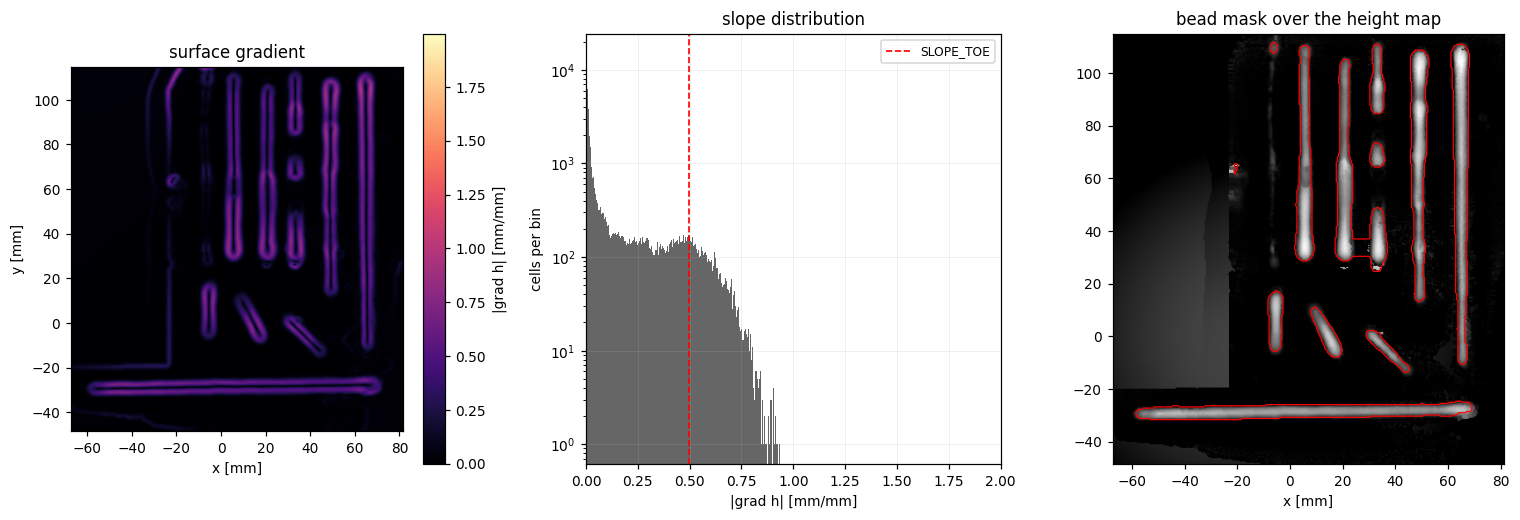

In [14]:
def plot_separation(height, slope, deposit, interior, extent, slope_toe):
    fig, ax = plt.subplots(1, 3, figsize=(14, 4.8))
    image = ax[0].imshow(slope, origin='lower', extent=extent, cmap='magma',
                         aspect='equal', vmin=0, vmax=4 * slope_toe)
    plt.colorbar(image, ax=ax[0], label='|grad h| [mm/mm]')
    ax[0].set_title('surface gradient')
    ax[0].set_xlabel('x [mm]')
    ax[0].set_ylabel('y [mm]')

    ax[1].hist(slope[interior].ravel(), bins=300, color='0.4')
    ax[1].axvline(slope_toe, color='r', ls='--', lw=1.1, label='SLOPE_TOE')
    ax[1].set_yscale('log')
    ax[1].set_xlim(0, 2.0)
    ax[1].set_xlabel('|grad h| [mm/mm]')
    ax[1].set_ylabel('cells per bin')
    ax[1].set_title('slope distribution')
    ax[1].legend(fontsize=8)
    ax[1].grid(alpha=0.3, lw=0.4)

    ax[2].imshow(np.clip(height, 0, None), origin='lower', extent=extent,
                 cmap='gray', aspect='equal')
    ax[2].contour(np.where(interior, deposit, 0), levels=[0.5], colors='r',
                  linewidths=0.8, extent=extent, origin='lower')
    ax[2].set_title('bead mask over the height map')
    ax[2].set_xlabel('x [mm]')
    fig.tight_layout()
    plt.show()


plot_separation(height, slope, deposit, interior, extent, SLOPE_TOE)

**How to read the separation figure.**

* *Surface gradient* — mm of height per mm of travel, clipped at four times the
  threshold so the toe region is visible. Bead flanks are bright, the crest is
  dark because it is flat, the substrate is dark because it is level.
* *Slope distribution* — log counts over the plate interior with the threshold
  marked. Two populations should be visible: a narrow substrate lobe near zero and
  a long flank tail.
* *Mask over the height map* — red contour is the toe line the rest of the
  pipeline will measure to.

**Good result:** the threshold sits in the empty valley between the two lobes,
at least ~2x above the substrate p99; the contour follows the visible toe and
closes around every bead.

**Problem:** the threshold inside the substrate lobe — noise gets segmented, so
raise `SMOOTH_MM` or `SLOPE_TOE`; two beads inside one contour — `CLOSE_MM` is
larger than their spacing; a contour tracing the plate edge — increase
`EDGE_GUARD_MM`; a contour that breaks along a bead is not necessarily an error,
it is a real interruption, and section 7 rejoins the fragments.

## 7. Beads, centrelines and per-division measurement

**Theory, in four parts.**

*Identification.* Connected components of the mask are candidate fragments. A
bead interrupted by a defect splits into several, so fragments are rejoined when
their principal axes agree ($|\cos| > 0.985$), their axes are laterally within
3 mm, and the end-to-end gap is small. Merging happens **before** the shape gates,
with a deliberately low area floor: gating first deletes the small piece of a
broken bead and the bead can never be recovered. The gates then require a region
to look like a weld bead — elongated, in the right height and width range — so
clamps, spatter clusters and scanning aids are never numbered or measured.

*Numbering.* Beads are numbered by **physical position on the plate**, not by
component label. Label order depends on where the scan happened to start and is
meaningless; matching scan bead 3 to the caliper's bead 3 by label produced a
silent mismatch in an earlier session.

*Centreline.* PCA gives a straight axis, but a real bead wanders. The centreline
is built from height-weighted centroids binned along the principal axis, smoothed,
interpolated with a Catmull-Rom spline and resampled at constant arc length $s$.
Each mask cell is then projected onto the nearest centreline point, giving
travel $s$ and transverse offset $t$. Dividing in equal arc length means division
$k$ of the scan is the same piece of metal as division $k$ marked on the plate.

*Measurement.* Per division, on the transverse profile $h(t)$:

$$\hat h(t) = at^2+bt+c \ \text{ fitted where } h > 0.7\,h_{\max},
\qquad t_{\text{apex}} = -\frac{b}{2a},
\qquad h_{\text{peak}} = \hat h(t_{\text{apex}})$$

The fitted apex is used instead of the largest sample because the largest sample
is the largest *noise excursion* near the crest, so it is biased upward.

$$w_{\text{toe}} = \max t - \min t \text{ over the mask},\qquad
w_{\text{FWHM}} = \text{width at } 0.5\,h_{\text{peak}}$$

$$A = \frac{1}{L_{\text{div}}}\sum_{\text{cells}} h_i \,\Delta^2$$

The area is the deposited volume of the division divided by its arc length: the
mean cross-section, which is exactly the quantity mass balance predicts in
section 9. The sum runs over the mask and over its *skirt*, the cells within
`SKIRT_MM` beside the mask that are nearer to this bead than to any other. The
mask stops where the slope or the height says the bead does, and on a low bead
that is well inside the toe; the skirt carries the rest of the profile, so the
area does not change with where the mask draws the line. On the plate past the
toe the height averages zero and adds nothing. `h_peak`, `w_FWHM` and `w_toe` are
read on the mask alone.

In [15]:
def region_geometry(px, py, ph, cell_mm):
    '''Second-moment description of a masked region, all in mm.'''
    centre = np.array([px.mean(), py.mean()])
    offsets = np.stack([px - centre[0], py - centre[1]], axis=1)
    values, vectors = np.linalg.eigh(np.cov(offsets.T))
    axis = vectors[:, 1]
    along = offsets @ axis
    minor, major = max(values[0], 1e-9), max(values[1], 1e-9)
    return dict(centre=centre, axis=axis,
                span=(float(along.min()), float(along.max())),
                area=len(px) * cell_mm ** 2, h_med=float(np.median(ph)),
                length=float(4 * np.sqrt(major)), width=float(4 * np.sqrt(minor)),
                elong=float(np.sqrt(major / minor)))


def same_bead(first, second):
    '''True if two fragments are pieces of one interrupted bead.'''
    a, b = first['geom'], second['geom']
    if abs(float(a['axis'] @ b['axis'])) < MERGE_AXIS_DOT:
        return False
    delta = b['centre'] - a['centre']
    across = np.array([-a['axis'][1], a['axis'][0]])
    if abs(float(delta @ across)) > MERGE_PERP_MM:
        return False
    shift = float(delta @ a['axis'])
    gap = max(a['span'][0] - (shift + b['span'][1]),
              (shift + b['span'][0]) - a['span'][1], 0.0)
    return gap <= MERGE_GAP_MM


def merge_fragments(regions, px_of, cell_mm):
    merged, used = [], set()
    for i in range(len(regions)):
        if i in used:
            continue
        group = [i]
        used.add(i)
        growing = True
        while growing:                       # transitive: handles 3+ fragments
            growing = False
            for j in range(len(regions)):
                if j not in used and any(same_bead(regions[g], regions[j]) for g in group):
                    group.append(j)
                    used.add(j)
                    growing = True
        mask = np.zeros_like(regions[group[0]]['mask'])
        for g in group:
            mask |= regions[g]['mask']
        merged.append(dict(mask=mask, fragments=len(group),
                           geom=region_geometry(*px_of(mask), cell_mm)))
    return merged


def rejection_reasons(geom, limits, fragments=1):
    checks = [(geom['area'] < limits['area_min'], f"area {geom['area']:.0f} mm2"),
              (geom['elong'] < limits['elong_min'], f"elongation {geom['elong']:.1f}"),
              (geom['elong'] > limits['elong_max'],
               f"elongation {geom['elong']:.1f}, too thin to be a bead"),
              (not limits['h_min'] <= geom['h_med'] <= limits['h_max'],
               f"height {geom['h_med']:.2f} mm"),
              (not limits['w_min'] <= geom['width'] <= limits['w_max'],
               f"width {geom['width']:.1f} mm"),
              (not limits['length_min'] <= geom['length'] <= limits['length_max'],
               f"length {geom['length']:.0f} mm"),
              (fragments > limits['frag_max'],
               f"{fragments} fragments merged, more than {limits['frag_max']}")]
    return [reason for failed, reason in checks if failed]


def cells_of(mask):
    return X_MM[mask], Y_MM[mask], height[mask]


if SPLIT_TOUCHING and basins is not None and n_cores >= 2:
    labels, n_labels = basins, int(basins.max())   # watershed already separated them
else:
    labels, n_labels = ndimage.label(deposit)
fragments = [dict(mask=labels == i, fragments=1,
                  geom=region_geometry(*cells_of(labels == i), CELL_MM))
             for i in range(1, n_labels + 1)
             if (labels == i).sum() * CELL_MM ** 2 >= FRAGMENT_AREA_MIN]

if not fragments:
    sizes = sorted((labels == i).sum() * CELL_MM ** 2 for i in range(1, n_labels + 1))
    print(f'No component reaches FRAGMENT_AREA_MIN = {FRAGMENT_AREA_MIN} mm2.')
    print(f'{n_labels} components found; the largest are '
          f'{[round(a, 1) for a in sizes[-5:]]} mm2.')
    print('The mask in section 6 is the problem, not the gates here: check that the '
          'red contour there follows the beads, and that the height map in section 4 '
          'shows the plate and not the table or a fixture.')

candidates = merge_fragments(fragments, cells_of, CELL_MM)
accepted, dropped = [], []
for region in candidates:
    reasons = rejection_reasons(region['geom'], BEAD_LIMITS,
                                region['fragments'])
    (accepted if not reasons else dropped).append((region, reasons))
accepted.sort(key=lambda item: -item[0]['geom']['area'])
if len(accepted) > N_BEADS:
    dropped += [(region, [f'beyond N_BEADS = {N_BEADS}'])
                for region, _ in accepted[N_BEADS:]]
    accepted = accepted[:N_BEADS]

def skirts(regions, reach_mm, cell_mm):
    '''For each bead, the cells beside its mask out to reach_mm that are nearer to
    it than to any other bead and belong to no other piece of deposit.'''
    owner = np.zeros(height.shape, int)
    for k, region in enumerate(regions, start=1):
        owner[region['mask']] = k
    distance, nearest = ndimage.distance_transform_edt(owner == 0, return_indices=True)
    beside = (owner == 0) & (distance * cell_mm <= reach_mm) & interior & ~deposit
    return [beside & (owner[tuple(nearest)] == k) for k in range(1, len(regions) + 1)]


for (region, _), skirt in zip(accepted, skirts([r for r, _ in accepted], SKIRT_MM, CELL_MM)):
    region['skirt'] = skirt

print(f'{n_labels} components -> {len(fragments)} fragments above the area floor '
      f'-> {len(candidates)} after merging\n')
header = f"{'area':>8} {'h_med':>7} {'length':>8} {'width':>7} {'elong':>7} {'frags':>6}  verdict"
print(header)
print('-' * len(header))
for region, reasons in accepted + dropped:
    g = region['geom']
    verdict = 'bead' if not reasons else 'dropped: ' + '; '.join(reasons)
    print(f"{g['area']:>8.0f} {g['h_med']:>7.2f} {g['length']:>8.1f} {g['width']:>7.1f} "
          f"{g['elong']:>7.1f} {region['fragments']:>6d}  {verdict}")
if len(accepted) != N_BEADS:
    print(f'\nWARNING: expected {N_BEADS} beads, accepted {len(accepted)}. '
          f'Check the mask in section 6 before trusting any number.')

if accepted and PLATE_AUTO:
    # X_MM and Y_MM are in the rotated frame, while PLATE_BOX is applied before
    # that rotation, so the corners have to be turned back before being quoted.
    xs = np.concatenate([X_MM[r['mask']] for r, _ in accepted])
    ys = np.concatenate([Y_MM[r['mask']] for r, _ in accepted])
    margin = 12.0
    box_rotated = np.array([[xs.min() - margin, ys.min() - margin, 0.0],
                            [xs.max() + margin, ys.min() - margin, 0.0],
                            [xs.max() + margin, ys.max() + margin, 0.0],
                            [xs.min() - margin, ys.max() + margin, 0.0]])
    box_levelled = box_rotated @ rotation_about_z(travel_dir)
    suggestion = (float(box_levelled[:, 0].min()), float(box_levelled[:, 0].max()),
                  float(box_levelled[:, 1].min()), float(box_levelled[:, 1].max()))
    print(f'\nThe automatic crop keeps the whole plate, fixture included, so the '
          'deformation model spends its seven terms partly on shapes that are not '
          'substrate. A crop around the deposit is usually steadier:')
    print(f'    PLATE_AUTO = False')
    print(f'    PLATE_BOX = ({suggestion[0]:.0f}, {suggestion[1]:.0f}, '
          f'{suggestion[2]:.0f}, {suggestion[3]:.0f})')
    print('Measured area moves with this crop -- on the five-bead coupon it shifts '
          'by up to 20%, because the datum each bead is measured against comes '
          'from the substrate inside the box. Treat the crop as part of the '
          'measurement: fix one, record it, and keep it for every plate in a '
          'series, or the areas are not comparable between them.')

14 components -> 12 fragments above the area floor -> 11 after merging

    area   h_med   length   width   elong  frags  verdict
---------------------------------------------------------
     600    1.30    143.5     5.5    25.9      1  bead
     575    1.30    135.0     5.9    22.7      1  bead
     465    1.29    107.3     6.2    17.4      2  bead
     378    1.19     87.9     7.2    12.2      1  bead
     372    1.15     94.8     5.8    16.4      1  bead
     150    1.14     23.7     9.1     2.6      1  bead
     111    1.14     28.7     5.3     5.4      1  bead
     108    1.21     24.7     5.8     4.3      1  bead
      99    1.14     21.8     5.9     3.7      1  bead
      75    1.02     23.5     4.3     5.5      1  bead
      41    1.13      9.5     5.6     1.7      1  dropped: area 41 mm2; elongation 1.7; length 9 mm

The automatic crop keeps the whole plate, fixture included, so the deformation model spends its seven terms partly on shapes that are not substrate. A crop aroun

In [16]:
def catmull_rom(control, n_points):
    control = np.asarray(control, float)
    n = len(control)
    if n < 3:
        u = np.linspace(0, 1, n_points)[:, None]
        return control[0] * (1 - u) + control[-1] * u
    padded = np.vstack([control[0], control, control[-1]])
    per_segment = max(2, n_points // (n - 1))
    pieces = []
    for i in range(n - 1):
        p0, p1, p2, p3 = padded[i], padded[i + 1], padded[i + 2], padded[i + 3]
        u = np.linspace(0, 1, per_segment, endpoint=(i == n - 2))[:, None]
        pieces.append(0.5 * (2 * p1 + (-p0 + p2) * u
                             + (2 * p0 - 5 * p1 + 4 * p2 - p3) * u ** 2
                             + (-p0 + 3 * p1 - 3 * p2 + p3) * u ** 3))
    return np.vstack(pieces)


def build_centreline(px, py, ph, geom, bin_mm=3.0, n_points=400):
    centre, axis = geom['centre'], geom['axis']
    across = np.array([-axis[1], axis[0]])
    offsets = np.stack([px - centre[0], py - centre[1]], axis=1)
    along, side = offsets @ axis, offsets @ across
    n_bins = max(12, int(np.ptp(along) / bin_mm))
    edges = np.linspace(along.min(), along.max(), n_bins + 1)
    index = np.clip(np.digitize(along, edges) - 1, 0, n_bins - 1)
    keep_along, keep_side = [], []
    for k in range(n_bins):
        take = index == k
        if take.sum() > 8 and ph[take].sum() > 0:
            keep_along.append(along[take].mean())
            keep_side.append(float(np.average(side[take], weights=ph[take])))
    if len(keep_along) < 5:
        keep_along = list(np.linspace(along.min(), along.max(), 5))
        keep_side = [0.0] * 5
    control = centre + np.outer(keep_along, axis) + np.outer(keep_side, across)
    smoothed = np.column_stack([ndimage.uniform_filter1d(control[:, 0], 3),
                                ndimage.uniform_filter1d(control[:, 1], 3)])
    smoothed[0], smoothed[-1] = control[0], control[-1]
    return catmull_rom(smoothed, n_points)


def resample_path(path, step_mm):
    distance = np.r_[0.0, np.cumsum(np.linalg.norm(np.diff(path, axis=0), axis=1))]
    s = np.linspace(0, distance[-1], max(2, int(distance[-1] / step_mm) + 1))
    return np.stack([np.interp(s, distance, path[:, 0]),
                     np.interp(s, distance, path[:, 1])], axis=1), s


def curvilinear(px, py, path, s_grid):
    '''Project cells onto the path -> (travel s, transverse offset t), both mm.'''
    tangent = np.gradient(path, axis=0)
    tangent /= np.maximum(np.linalg.norm(tangent, axis=1, keepdims=True), 1e-9)
    normal = np.stack([-tangent[:, 1], tangent[:, 0]], axis=1)
    xy = np.stack([px, py], axis=1)
    _, nearest = cKDTree(path).query(xy)
    return s_grid[nearest], np.einsum('ij,ij->i', xy - path[nearest], normal[nearest])


def parabola_peak(t, h, top_frac=0.70):
    '''Crest height from a parabola through the top of the profile.'''
    crest = h >= top_frac * h.max()
    if crest.sum() < 6:
        return float(h.max())
    a, b, c = np.polyfit(t[crest], h[crest], 2)
    if a >= 0:
        return float(h.max())
    apex = -b / (2 * a)
    if not t[crest].min() <= apex <= t[crest].max():
        return float(h.max())
    return float(a * apex ** 2 + b * apex + c)


def profile_area(offset, heights, cell_mm):
    '''Integral of the transverse profile: cells binned by lateral offset, the
    rows inside the stretch averaged in each bin, bins summed.'''
    order = np.argsort(offset)
    t, h = offset[order], heights[order]
    bins = np.floor(t / cell_mm).astype(int)
    edges = np.flatnonzero(np.diff(bins)) + 1
    return sum(float(np.mean(chunk)) for chunk in np.split(h, edges)) * cell_mm


def division_metrics(offset, heights, length_mm, cell_mm, skirt=None):
    order = np.argsort(offset)
    t, h = offset[order], heights[order]
    smoothed = ndimage.uniform_filter1d(h, max(3, len(h) // 200))
    if smoothed.max() <= 0:
        return None
    half = smoothed >= 0.5 * smoothed.max()
    # Cross-section as the integral of the transverse profile: cells binned by
    # lateral offset, the rows inside the division averaged in each bin, bins
    # summed. Summing every cell and dividing by the division length instead
    # depends on how many raster rows fall inside, which jumps by one row at a
    # time and aliases the area when a division is only a few cells long.
    # The mask stops where the slope or the height says the bead does, and on a
    # low bead that is well inside the toe. The skirt cells carry the rest of the
    # profile, so the area is the same wherever the mask happens to stop.
    if skirt is not None and len(skirt[0]):
        area = profile_area(np.r_[offset, skirt[0]], np.r_[heights, skirt[1]], cell_mm)
    else:
        area = profile_area(offset, heights, cell_mm)
    return dict(h_peak=parabola_peak(t, smoothed),
                w_fwhm=float(t[half].max() - t[half].min()) if half.sum() > 1 else 0.0,
                w_toe=float(t[-1] - t[0]),
                area=area)


def measure_bead(region, n_div, step_mm, cell_mm):
    px, py, ph = cells_of(region['mask'])
    geom = region['geom']
    path = build_centreline(px, py, ph, geom)
    across = np.array([-geom['axis'][1], geom['axis'][0]])
    if np.abs((path - geom['centre']) @ across).max() > MERGE_PERP_MM:
        # A long thin bead is nearly straight; a centreline that wanders further
        # than the merge tolerance is a fitting artefact, not geometry.
        ends = np.linspace(geom['span'][0], geom['span'][1], len(path))[:, None]
        path = geom['centre'] + ends * geom['axis']
    path, s_grid = resample_path(path, step_mm)
    s, t = curvilinear(px, py, path, s_grid)
    s_start, s_end = s.min(), s.max()
    kx, ky, kh = cells_of(region['skirt'])
    ks, kt = curvilinear(kx, ky, path, s_grid) if len(kx) else (kx, kx)
    within = (ks > s_start) & (ks < s_end)      # beside the bead, not past its ends
    ks, kt, kh = ks[within], kt[within], kh[within]
    edges = np.linspace(s_start, s_end, n_div + 1)
    divisions = []
    for k in range(n_div):
        take = (s >= edges[k]) & (s < edges[k + 1])
        if take.sum() < 20:
            continue
        beside = (ks >= edges[k]) & (ks < edges[k + 1])
        metrics = division_metrics(t[take], ph[take], edges[k + 1] - edges[k], cell_mm,
                                   skirt=(kt[beside], kh[beside]))
        if metrics:
            metrics.update(division=k + 1,
                           s_mid=float(0.5 * (edges[k] + edges[k + 1]) - s_start))
            divisions.append(metrics)
    if len(divisions) < 3:
        return None
    return dict(length=float(s_end - s_start), centroid=geom['centre'],
                path=path[(s_grid >= s_start) & (s_grid <= s_end)],
                divisions=divisions, mask=region['mask'],
                travel=s, offset=t, edges=edges,
                profile=(np.r_[s, ks], np.r_[t, kt], np.r_[ph, kh]))


NO_BEADS = ('No bead was accepted in section 7, so there is nothing to measure, '
            'plot or export. Work backwards: the mask in section 6, then the '
            'height map in section 4, then the levelling in section 2.')

beads = [b for b in (measure_bead(region, N_DIV, PATH_DS_MM, CELL_MM)
                     for region, _ in accepted) if b]
print(f'{len(beads)} beads measured, {N_DIV} divisions each' if beads else NO_BEADS)

10 beads measured, 10 divisions each


In [17]:
POSITIONS = {1: 'upper right', 2: 'upper left', 3: 'lower right',
             4: 'lower left', 5: 'centre'}


def number_by_position(beads, layout=None):
    '''Number beads by where they sit on the plate, never by component label.

    'stacked': parallel beads side by side, numbered across the stacking
    direction. The welding log is written in that same order, so this is the
    pairing that makes the regression mean anything -- getting it backwards
    shows up as a negative correlation between lambda and area.

    'quincunx': four corners plus a centre, the older coupon layout.'''
    layout = layout or BEAD_LAYOUT
    if not beads:
        return beads

    if layout == 'stacked':
        cross = []
        for bead in beads:
            d = bead['path'][-1] - bead['path'][0]
            bead['cross'] = (np.degrees(np.arccos(min(1.0, abs(d[1]) / np.hypot(*d))))
                             > CROSS_ANGLE_DEG)
        cross = sorted([b for b in beads if b['cross']], key=lambda b: -b['centroid'][1])
        beads = [b for b in beads if not b['cross']]
        centres = np.array([b['centroid'][:2] for b in beads])
        spread = centres.max(axis=0) - centres.min(axis=0)
        axis = {'x': 0, 'y': 1}.get(STACK_AXIS, int(np.argmax(spread)))
        sign = 1 if STACK_REVERSE else -1
        order = sorted(beads, key=lambda b: sign * b['centroid'][axis])
        for number, bead in enumerate(order, start=1):
            bead['id'] = number
            POSITIONS[number] = BEAD_NAMES.get(number, f'stack {number}')
        ends = {(1, False): 'y, top to bottom', (1, True): 'y, bottom to top',
                (0, False): 'x, right to left', (0, True): 'x, left to right'}
        name = ends[(axis, bool(STACK_REVERSE))]
        print(f'numbered as a stack along {name}, '
              f'{spread[axis]:.0f} mm across {len(beads)} beads')
        for k, bead in enumerate(cross):
            bead['id'] = len(order) + k + 1
            POSITIONS[bead['id']] = (CROSS_BEAD_NAMES[k] if k < len(CROSS_BEAD_NAMES)
                                     else f'cross {k + 1}')
        if cross:
            print(f'{len(cross)} long bead(s) across the stack, numbered after it: '
                  + ', '.join(f"{b['id']} = {POSITIONS[b['id']]}" for b in cross))
        return order + cross

    if len(beads) != 5:
        print(f'WARNING: the quincunx scheme expects 5 beads, got {len(beads)}. '
              f'Numbering by length instead; check against the plate.')
        for i, bead in enumerate(sorted(beads, key=lambda b: -b['length']), start=1):
            bead['id'] = i
            POSITIONS.setdefault(i, f'bead {i}')
        return sorted(beads, key=lambda b: b['id'])
    longest = max(beads, key=lambda b: b['length'])
    longest['id'] = 5
    others = sorted([b for b in beads if b is not longest],
                    key=lambda b: -b['centroid'][1])
    for group, ids in ((others[:2], (1, 2)), (others[2:4], (3, 4))):
        group.sort(key=lambda b: -b['centroid'][0])
        for bead, number in zip(group, ids):
            bead['id'] = number
    return sorted(beads, key=lambda b: b['id'])


beads = number_by_position(beads)
for bead in beads:
    peak = np.array([d['h_peak'] for d in bead['divisions']])
    toe = np.array([d['w_toe'] for d in bead['divisions']])
    area = np.array([d['area'] for d in bead['divisions']])
    bead.update(h_mean=peak.mean(), h_sd=peak.std(), h_cv=peak.std() / peak.mean(),
                w_mean=toe.mean(), area_mean=area.mean())

header = (f"{'id':>3}  {'position':<13} {'length':>8} {'h_peak':>8} {'sd':>7} "
          f"{'CV%':>6} {'w_toe':>7} {'area':>8}")
print(header)
print('-' * len(header))
for bead in beads:
    print(f"{bead['id']:>3}  {POSITIONS.get(bead['id'], '?'):<13} {bead['length']:>8.1f} "
          f"{bead['h_mean']:>8.3f} {bead['h_sd']:>7.3f} {100 * bead['h_cv']:>6.1f} "
          f"{bead['w_mean']:>7.2f} {bead['area_mean']:>8.2f}")
print('\nlength mm, h_peak mm, w_toe mm, area mm2; sd and CV are over the '
      f'{N_DIV} divisions of each bead.' if beads else NO_BEADS)

numbered as a stack along y, top to bottom, 96 mm across 8 beads
2 long bead(s) across the stack, numbered after it: 9 = S13, 10 = V
 id  position        length   h_peak      sd    CV%   w_toe     area
--------------------------------------------------------------------
  1  C3                23.9    1.629   0.308   18.9    4.15     5.26
  2  D                 92.0    1.853   0.312   16.9    5.24     6.42
  3  B2                78.4    1.707   0.373   21.9    4.54     5.79
  4  B3                72.9    1.631   0.328   20.1    5.03     6.06
  5  W                118.0    1.833   0.257   14.0    4.67     6.21
  6  C1                21.8    1.941   0.402   20.7    6.77     7.74
  7  A                 20.3    1.727   0.296   17.2    4.74     6.29
  8  S12               18.8    1.665   0.407   24.4    4.96     6.40
  9  S13               19.6    1.463   0.296   20.3    3.43     4.30
 10  V                124.2    1.689   0.095    5.6    4.76     5.88

length mm, h_peak mm, w_toe mm, area m

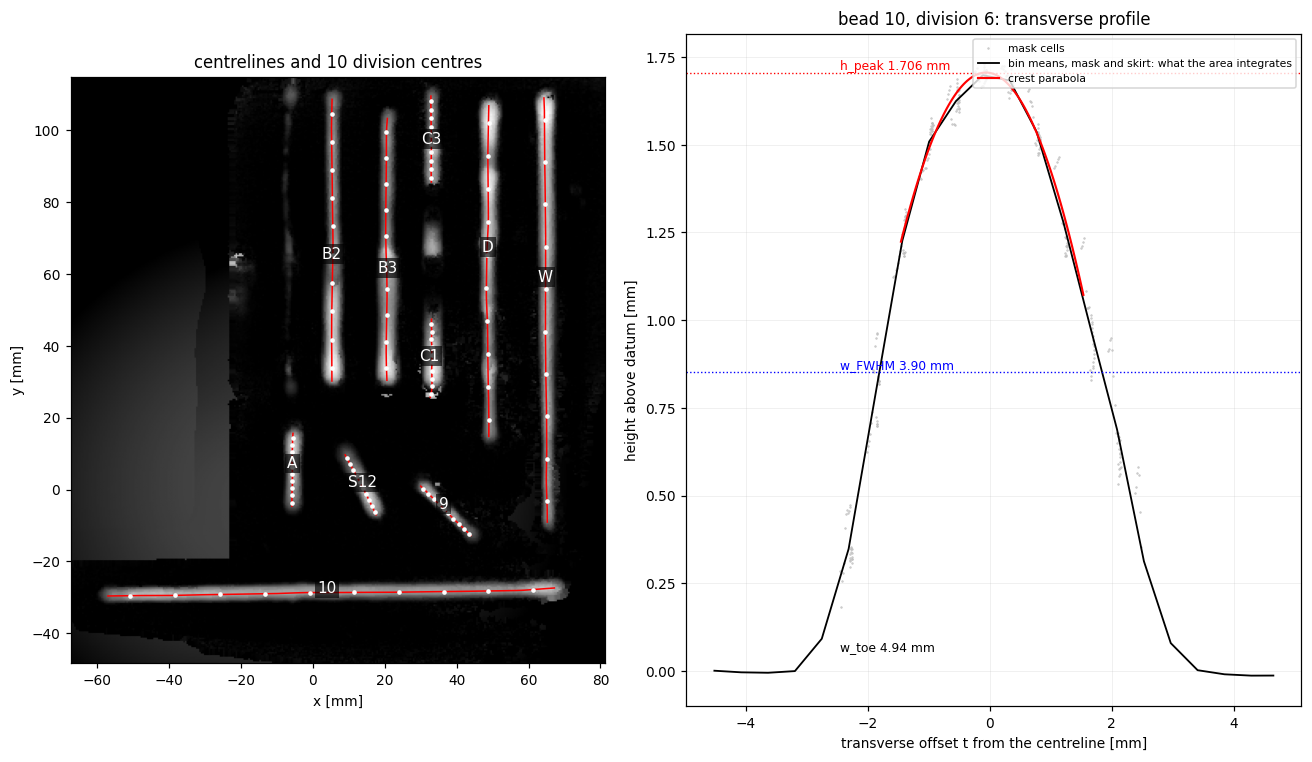

In [18]:
def plot_beads(height, beads, extent, n_div):
    fig, ax = plt.subplots(1, 2, figsize=(12, 7),
                           gridspec_kw={'width_ratios': [1, 1.15]})
    ax[0].imshow(np.clip(height, 0, None), origin='lower', extent=extent,
                 cmap='gray', aspect='equal')
    for bead in beads:
        path = bead['path']
        ax[0].plot(path[:, 0], path[:, 1], 'r-', lw=1.0)
        for d in bead['divisions']:
            i = int(np.clip(d['s_mid'] / max(bead['length'], 1e-9), 0, 1) * (len(path) - 1))
            ax[0].plot(path[i, 0], path[i, 1], 'w.', ms=4)
        ax[0].annotate(str(BEAD_NAMES.get(bead['id'], bead['id'])), bead['centroid'],
                       color='w', ha='center',
                       fontsize=10, bbox=dict(fc='k', alpha=0.65, pad=1.5, lw=0))
    ax[0].set_xlabel('x [mm]')
    ax[0].set_ylabel('y [mm]')
    ax[0].set_title(f'centrelines and {n_div} division centres')

    bead = max(beads, key=lambda b: b['length'])
    _, _, ph = cells_of(bead['mask'])
    s, t, edges = bead['travel'], bead['offset'], bead['edges']
    middle = len(bead['divisions']) // 2
    take = (s >= edges[middle]) & (s < edges[middle + 1])
    order = np.argsort(t[take])
    t_div, h_div = t[take][order], ph[take][order]
    smoothed = ndimage.uniform_filter1d(h_div, max(3, len(h_div) // 200))
    metrics = bead['divisions'][middle]

    ax[1].plot(t_div, h_div, '.', ms=1, color='0.75', label='mask cells')
    ps, pt, ph_all = bead['profile']
    inside = (ps >= edges[middle]) & (ps < edges[middle + 1])
    across = np.argsort(pt[inside])
    bins = np.floor(pt[inside][across] / CELL_MM).astype(int)
    cuts = np.flatnonzero(np.diff(bins)) + 1
    ax[1].plot([c.mean() for c in np.split(pt[inside][across], cuts)],
               [c.mean() for c in np.split(ph_all[inside][across], cuts)], 'k-', lw=1.2,
               label='bin means, mask and skirt: what the area integrates')
    crest = smoothed >= 0.70 * smoothed.max()
    coefficients = np.polyfit(t_div[crest], smoothed[crest], 2)
    fine = np.linspace(t_div[crest].min(), t_div[crest].max(), 100)
    ax[1].plot(fine, np.polyval(coefficients, fine), 'r-', lw=1.4, label='crest parabola')
    ax[1].axhline(metrics['h_peak'], color='r', ls=':', lw=0.9)
    ax[1].axhline(0.5 * metrics['h_peak'], color='b', ls=':', lw=0.9)
    ax[1].annotate(f"h_peak {metrics['h_peak']:.3f} mm", (t_div.min(), metrics['h_peak']),
                   fontsize=8, color='r', va='bottom')
    ax[1].annotate(f"w_FWHM {metrics['w_fwhm']:.2f} mm",
                   (t_div.min(), 0.5 * metrics['h_peak']), fontsize=8, color='b', va='bottom')
    ax[1].annotate(f"w_toe {metrics['w_toe']:.2f} mm", (t_div.min(), 0.05),
                   fontsize=8, color='k', va='bottom')
    ax[1].set_xlabel('transverse offset t from the centreline [mm]')
    ax[1].set_ylabel('height above datum [mm]')
    ax[1].set_title(f"bead {BEAD_NAMES.get(bead['id'], bead['id'])}, division "
                    f"{metrics['division']}: transverse profile")
    ax[1].legend(fontsize=7, loc='upper right')
    ax[1].grid(alpha=0.3, lw=0.4)
    fig.tight_layout()
    plt.show()


if beads:
    plot_beads(height, beads, extent, N_DIV)
else:
    print(NO_BEADS)

**How to read the bead figure.**

* *Centrelines* — red is the arc-length path, white dots are the division centres,
  the number is the physical bead id. Those dots are the stations to measure with
  the caliper in section 10.
* *Transverse profile* — one division seen end-on, all in mm. Grey dots are every
  mask cell of that division stacked at its offset $t$; black is the smoothed
  profile; red is the parabola fitted to the top 30% and the height it reports;
  blue is the half-height where FWHM is measured; `w_toe` is the full width of the
  mask.

**Good result:** centrelines running down the middle of each bead with no
excursions; the parabola sitting on the crest with the grey cloud symmetric about
it; `h_peak` slightly *below* the highest grey dot, which is the point of fitting
it.

**Problem:** a centreline that snakes (the region is not a bead, or two beads
merged in section 6); a parabola above the data (crest too flat for a quadratic —
the value falls back to the smoothed maximum, which is conservative); a
one-sided grey cloud (spatter attached to one flank, which also inflates
`w_toe`).

## 8. Results and zone map

**Theory.** Two questions, two views. *How does each bead vary along its length?*
— the per-division curves. *Where on the plate is the deposit out of tolerance?*
— the zone map.

The zone map covers the plate with square cells of side `ZONE_MM`. A zone is
judged only where a bead's centreline crosses it, because a zone that clips only
a flank reports the flank height and would fail for a geometric reason rather
than a process one. The crest height of a zone is the 90th percentile of the bead
cells inside it, and the verdict compares it with **that bead's own mean**:

$$\text{zone} = \begin{cases}
\texttt{o} & |h_{90} - \bar h_{\text{bead}}| \le \text{tol}\\
\texttt{x} & \text{otherwise}\\
\texttt{.} & \text{no bead centreline in this zone}
\end{cases}$$

**Physical meaning.** This is a uniformity map, which is the immediate objective:
beads that come out the same along their whole length. Each bead is judged
against itself, so beads deliberately welded at different parameters are not
compared with each other. Set an absolute target instead when checking against a
specification.

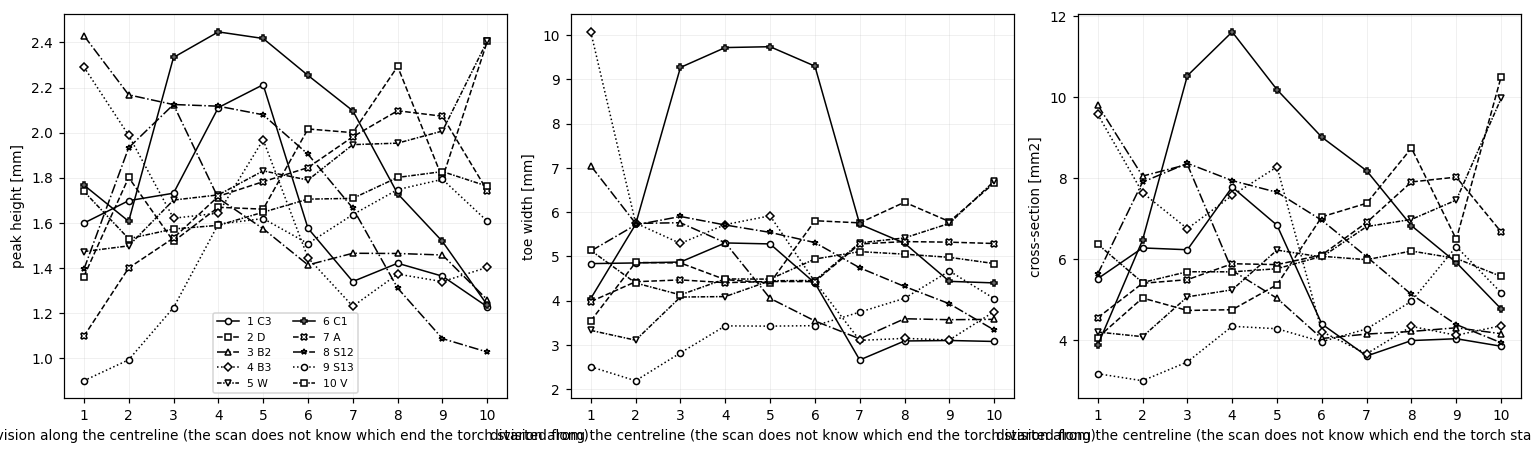

In [19]:
def plot_along_bead(beads, n_div):
    marks = ['o', 's', '^', 'D', 'v', 'P', 'X', '*']
    lines = ['-', '--', '-.', ':', (0, (3, 1, 1, 1))]
    fig, ax = plt.subplots(1, 3, figsize=(14, 4.2))
    for key, axis, label in [('h_peak', ax[0], 'peak height [mm]'),
                             ('w_toe', ax[1], 'toe width [mm]'),
                             ('area', ax[2], 'cross-section [mm2]')]:
        for k, bead in enumerate(beads):
            axis.plot([d['division'] for d in bead['divisions']],
                      [d[key] for d in bead['divisions']],
                      color='k', ls=lines[k % len(lines)], marker=marks[k % len(marks)],
                      ms=4, mfc='w', lw=1.0,
                      label=f"{bead['id']} {POSITIONS.get(bead['id'], '')}")
        axis.set_xlabel('division along the centreline (the scan does not know which end the torch started from)')
        axis.set_ylabel(label)
        axis.set_xticks(range(1, n_div + 1))
        axis.grid(alpha=0.3, lw=0.4)
    ax[0].legend(fontsize=7, ncol=2)
    fig.tight_layout()
    plt.show()


if beads:
    plot_along_bead(beads, N_DIV)
else:
    print(NO_BEADS)

### Repeatable error versus random error

Layer-to-layer control can only remove the part of the error that **repeats**. If
every bead runs high at the same point along its travel, that offset is a signature
of the process — arc start ramp, heat accumulation, a corner in the path — and a
controller can learn it. If instead each bead deviates somewhere different, the
error is noise, and no amount of layer-to-layer correction will touch it.

Splitting the two is a variance decomposition. Take the deviation of every division
from the mean of its own bead,

$$e_{ij} = h_{ij} - \bar h_i,
\qquad i = \text{bead},\; j = \text{division},$$

then compare the spread of the division medians against the spread within a
division:

$$\sigma_{\text{repeatable}} = \operatorname{sd}_j\big(\operatorname{med}_i e_{ij}\big),
\qquad
\sigma_{\text{random}} = \operatorname{mean}_j\big(\operatorname{sd}_i e_{ij}\big)$$

A box per division shows both at once: the position of the boxes is the repeatable
signature, their height is the random part. The ratio is the answer to whether
closed-loop layer-to-layer control is worth building for this process.

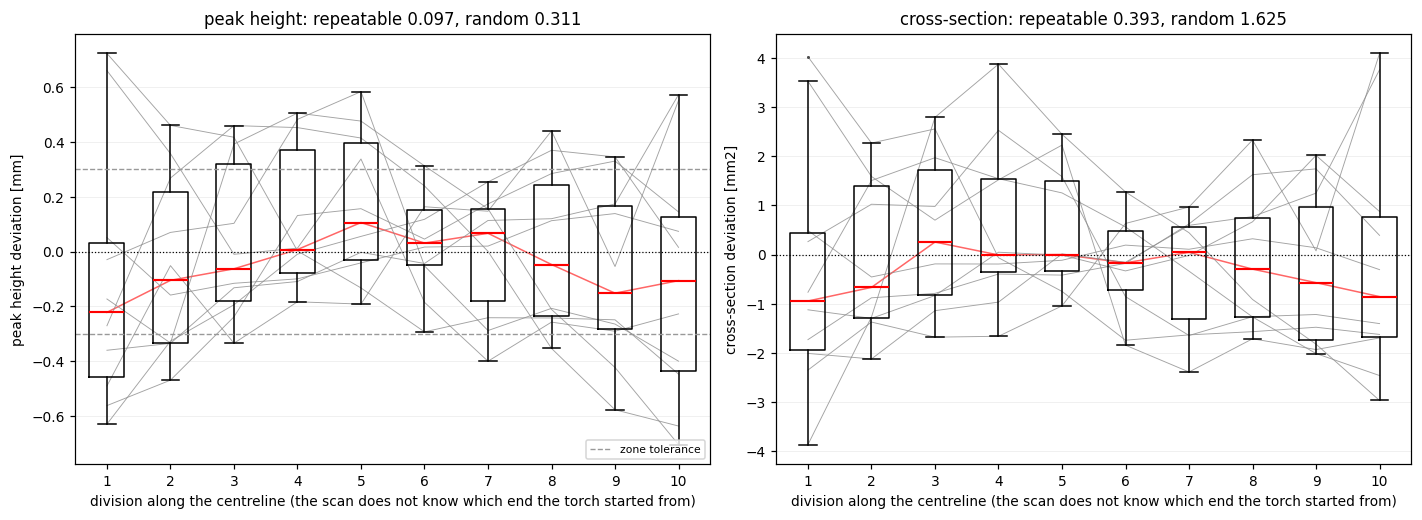

--- h_peak ---
  repeatable  0.0970 mm   (spread of the division medians)
  random      0.3113 mm   (spread within a division)
  ratio       0.31
  the error does not repeat: it is process noise, and layer-to-layer correction cannot remove it.
  largest median deviation at division 1 of 10

--- area ---
  repeatable  0.3934 mm2   (spread of the division medians)
  random      1.6247 mm2   (spread within a division)
  ratio       0.24
  the error does not repeat: it is process noise, and layer-to-layer correction cannot remove it.
  largest median deviation at division 1 of 10



In [20]:
def deviation_by_division(beads, key, n_div):
    '''Deviation of each division from the mean of its own bead, grouped by
    division index. Returns one array per division.'''
    groups = [[] for _ in range(n_div)]
    for bead in beads:
        values = np.array([d[key] for d in bead['divisions']])
        # Grouped by the division's own number, not its place in the list: a
        # division with too few cells is dropped, and counting by position would
        # then slide every later one into the wrong group.
        for d, deviation in zip(bead['divisions'], values - values.mean()):
            groups[d['division'] - 1].append(float(deviation))
    return [np.array(g) for g in groups]


def variance_split(groups):
    '''Repeatable spread (across division medians) and random spread (within a
    division), in the units of the quantity.'''
    medians = np.array([np.median(g) for g in groups if len(g)])
    within = np.array([g.std(ddof=1) for g in groups if len(g) > 1])
    repeatable = float(medians.std()) if len(medians) else float('nan')
    random = float(within.mean()) if len(within) else float('nan')
    return repeatable, random


def plot_deviation_boxes(beads, n_div, tol_mm):
    panels = [('h_peak', 'peak height deviation [mm]', 'peak height', tol_mm),
              ('area', 'cross-section deviation [mm2]', 'cross-section', None)]
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
    for axis, (key, ylabel, name, tol) in zip(ax, panels):
        groups = deviation_by_division(beads, key, n_div)
        repeatable, random = variance_split(groups)
        axis.boxplot([g if len(g) else [np.nan] for g in groups], widths=0.55, medianprops=dict(color='r', lw=1.4),
                     flierprops=dict(marker='.', ms=4, mfc='0.3', mec='none'))
        axis.plot(range(1, n_div + 1),
                  [np.median(g) if len(g) else np.nan for g in groups],
                  color='r', lw=1.0, alpha=0.6, zorder=0)
        for bead in beads:
            values = np.array([d[key] for d in bead['divisions']])
            axis.plot([d['division'] for d in bead['divisions']],
                      values - values.mean(), color='0.55', lw=0.6, alpha=0.8,
                      zorder=0)
        if tol is not None:
            for sign in (-1, 1):
                axis.axhline(sign * tol, color='0.6', ls='--', lw=0.9,
                             label='zone tolerance' if sign > 0 else None)
            axis.legend(fontsize=7, loc='lower right')
        axis.axhline(0, color='k', lw=0.8, ls=':')
        axis.set_xlabel('division along the centreline (the scan does not know which end the torch started from)')
        axis.set_ylabel(ylabel)
        axis.set_title(f'{name}: repeatable {repeatable:.3f}, random {random:.3f}')
        axis.grid(alpha=0.3, lw=0.4, axis='y')
    fig.tight_layout()
    plt.show()


if beads:
    plot_deviation_boxes(beads, N_DIV, HEIGHT_TOL_MM)
    for key, unit in [('h_peak', 'mm'), ('area', 'mm2')]:
        groups = deviation_by_division(beads, key, N_DIV)
        repeatable, random = variance_split(groups)
        print(f'--- {key} ---')
        print(f'  repeatable  {repeatable:.4f} {unit}   (spread of the division medians)')
        print(f'  random      {random:.4f} {unit}   (spread within a division)')
        if random > 0:
            ratio = repeatable / random
            verdict = ('the error repeats: layer-to-layer control has a signature '
                       'to learn.' if ratio >= 1.5 else
                       'the error does not repeat: it is process noise, and '
                       'layer-to-layer correction cannot remove it.' if ratio <= 0.7
                       else 'repeatable and random parts are comparable: a controller '
                            'would chase noise as often as signal.')
            print(f'  ratio       {ratio:.2f}')
            print(f'  {verdict}')
        worst = int(np.argmax([abs(np.median(g)) for g in groups])) + 1
        print(f'  largest median deviation at division {worst} of {N_DIV}\n')
else:
    print(NO_BEADS)

**How to read the boxes.**

* *x* is the division index along travel, 1 at the arc start. *y* is the deviation
  of that division from the mean of its own bead, so every bead contributes on the
  same scale regardless of the parameters it was welded with.
* Each box holds one value per bead: red line the median, box the interquartile
  range, whiskers the rest. The grey lines behind are the individual beads.
* The dashed lines on the height panel are the zone tolerance, for scale.

**Good result:** boxes centred on zero in the middle divisions, widening only at 1
and $N$ where the arc ramps. A repeatable-to-random ratio below one means the
process is dominated by noise and is already as uniform as open loop can make it.

**Problem:** a red line that trends monotonically across the divisions is heat
accumulating along the bead, and it repeats — that is the case layer-to-layer
control is built for. Boxes uniformly wide with a flat median mean the scatter is
random; look at scan quality and clamping before blaming the process.

*With five beads each box holds five points, so read the medians and ignore the
quartiles as anything but an indication.*

zones judged    70   within tolerance 47 (67%)
worst deviation +0.735 mm
each zone is judged against the mean crest of its own bead, so this reads uniformity along a bead, not height against a target

plate seen from above, one character per 10 mm zone (o within tolerance, x outside, . no bead):
   . . . . . . . x . . x x . x
   . . . . . . . o x . o x . x
   . . . . . . . o x . o x . o
   . . . . . . . x x . . o . o
   . . . . . . . o o . . o . o
   . . . . . . . o o . . o . o
   . . . . . . . x o . x o . o
   . . . . . . . x x . o o . o
   . . . . . . . x x o o o . o
   . . . . . . o . . . . x . o
   . . . . . . o o o . . . . x
   . . . . . . x . x o o . . x
   . . . . . . . . . . o . . x
   . . . . . . . . . . o o o o
   . o o o o o o o o o o . . .
   . . . . . . . . . . . . . .


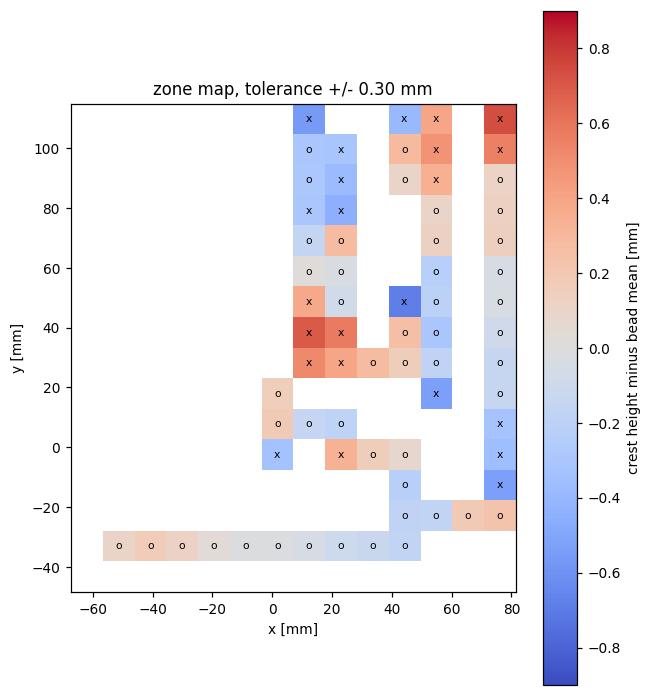

In [21]:
def zone_map(beads, height, grid_origin, cell_mm, zone_mm, tol_mm, target=None):
    '''Square zones judged where a bead centreline passes. Returns crest heights,
    verdict characters and the bead id owning each zone.'''
    step = int(round(zone_mm / cell_mm))
    shape = (height.shape[0] // step, height.shape[1] // step)
    crest = np.full(shape, np.nan)
    owner = np.zeros(shape, int)
    for bead in beads:
        columns = np.clip(((bead['path'][:, 0] - grid_origin[0]) / zone_mm).astype(int),
                          0, shape[1] - 1)
        rows = np.clip(((bead['path'][:, 1] - grid_origin[1]) / zone_mm).astype(int),
                       0, shape[0] - 1)
        for row, column in set(zip(rows.tolist(), columns.tolist())):
            window = (slice(row * step, (row + 1) * step),
                      slice(column * step, (column + 1) * step))
            cells = bead['mask'][window]
            if cells.sum() < 0.05 * step * step:
                continue
            crest[row, column] = np.percentile(height[window][cells], 90)
            owner[row, column] = bead['id']
    verdict = np.full(shape, '.')
    judged = np.isfinite(crest)
    deviation = np.full(shape, np.nan)
    for bead in beads:
        mine = judged & (owner == bead['id'])
        if not mine.any():
            continue
        # Reference and zone value must be the same statistic. Using the mean of
        # the fitted per-division peaks against a 90th-percentile zone crest
        # offsets every zone of the bead by the gap between the two.
        reference = target if target is not None else float(crest[mine].mean())
        deviation[mine] = crest[mine] - reference
    measured = judged & np.isfinite(deviation)
    verdict[measured & (np.abs(deviation) <= tol_mm)] = 'o'
    verdict[measured & (np.abs(deviation) > tol_mm)] = 'x'
    return crest, verdict, owner, deviation


def plot_zone_map(deviation, verdict, extent, tol_mm):
    shown = np.where(verdict != '.', deviation, np.nan)
    fig, axis = plt.subplots(figsize=(6.0, 6.4))
    image = axis.imshow(shown, origin='lower', extent=extent, cmap='coolwarm',
                        aspect='equal', vmin=-3 * tol_mm, vmax=3 * tol_mm,
                        interpolation='nearest')
    plt.colorbar(image, ax=axis, label='crest height minus bead mean [mm]')
    rows, columns = verdict.shape
    dx = (extent[1] - extent[0]) / columns
    dy = (extent[3] - extent[2]) / rows
    for r in range(rows):
        for c in range(columns):
            if verdict[r, c] != '.':
                axis.text(extent[0] + (c + 0.5) * dx, extent[2] + (r + 0.5) * dy,
                          verdict[r, c], ha='center', va='center', fontsize=7,
                          color='k')
    axis.set_xlabel('x [mm]')
    axis.set_ylabel('y [mm]')
    axis.set_title(f'zone map, tolerance +/- {tol_mm:.2f} mm')
    fig.tight_layout()
    plt.show()


crest, verdict, owner, deviation = zone_map(beads, height, grid_origin, CELL_MM,
                                            ZONE_MM, HEIGHT_TOL_MM)
judged = verdict != '.'
if judged.any():
    print(f'zones judged    {judged.sum()}   within tolerance '
          f'{(verdict == "o").sum()} ({100 * (verdict == "o").sum() / judged.sum():.0f}%)')
    print(f'worst deviation {np.nanmax(np.abs(deviation[judged])):+.3f} mm')
    print('each zone is judged against the mean crest of its own bead, so this '
          'reads uniformity along a bead, not height against a target\n')
    print('plate seen from above, one character per '
          f'{ZONE_MM:.0f} mm zone (o within tolerance, x outside, . no bead):')
    for row in verdict[::-1]:
        print('   ' + ' '.join(row))
    plot_zone_map(deviation, verdict, extent, HEIGHT_TOL_MM)
else:
    print(NO_BEADS)

In [22]:
def write_divisions_csv(path, beads, positions):
    with open(path, 'w', newline='') as handle:
        writer = csv.writer(handle)
        writer.writerow(['plate', 'bead_id', 'position', 'division', 's_mid_mm',
                         'h_peak_mm', 'w_fwhm_mm', 'w_toe_mm', 'area_mm2'])
        for bead in beads:
            for d in bead['divisions']:
                writer.writerow([PLATE_ID, bead['id'], positions.get(bead['id'], ''),
                                 d['division'], f"{d['s_mid']:.2f}",
                                 f"{d['h_peak']:.4f}", f"{d['w_fwhm']:.4f}",
                                 f"{d['w_toe']:.4f}", f"{d['area']:.3f}"])


if beads:
    write_divisions_csv(OUT_DIR / 'divisions.csv', beads, POSITIONS)
    print(f'wrote {OUT_DIR / "divisions.csv"}: '
          f'{sum(len(b["divisions"]) for b in beads)} rows')
else:
    print(NO_BEADS)

wrote output/divisions.csv: 100 rows


**How to read the results.**

* *Along-bead curves* — division number on $x$, counted along the centreline -- which end the torch
  started from is not in the scan and has to come from the program --, the
  measured quantity on $y$ in mm or mm². Divisions 1 and $N$ sit on the arc start
  and stop ramps, so a dip at both ends is the process, not a measurement
  artefact; that is why the caliper stations in section 10 are the division
  centres.
* *Zone map* — deviation of each zone's crest from its bead's mean, red high, blue
  low, characters repeating the verdict. Only zones crossed by a centreline are
  judged.

**Good result:** flat curves between the end ramps, CV of a few percent, a zone
map that is almost all `o` with any `x` at the ends.

**Problem:** a monotonic drift along a bead points at heat accumulation — compare
it against the run order in section 9, since the randomised order is what makes
drift separable from parameter effects. `x` clusters in the middle of a bead
indicate a feeding or standoff problem at that point. Beads of very different
means with all-`o` maps are individually uniform but not equal to each other,
which is a parameter question, not a stability one.

### The bead as a solid

Sections 7 and 8 reduce each bead to numbers: a crest height and a width per
division, an area, a centreline. Those numbers describe a shape, and putting the
shape back together is the quickest way to see whether they describe the bead
that is actually on the plate.

Each division contributes one cross-section, placed at its own point along the
centreline and turned to face along the path. Sweeping them gives the surface.
The profile used is a parabola through the crest, falling to zero at the toe --
the same shape `parabola_peak` fits when it reads the crest height, so the solid
shown is the model the measurements assume, not an independent reading of the
scan. Where it departs from the height map, the measurements are the thing to
distrust.

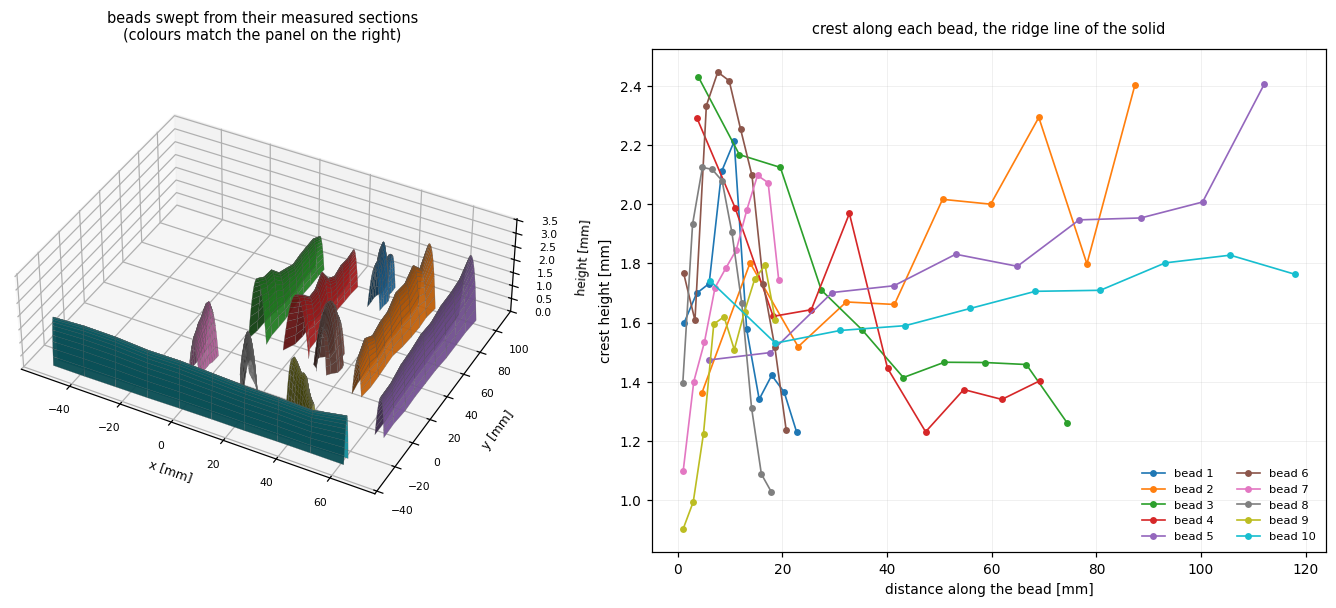

 bead   length   h_peak    w_toe  swept vol     A x L     gap
--------------------------------------------------------------
    1     23.9     1.63     4.15        112       126    -11%
    2     92.0     1.85     5.24        611       590     +4%
    3     78.4     1.71     4.54        428       454     -6%
    4     72.9     1.63     5.03        428       441     -3%
    5    118.0     1.83     4.67        695       733     -5%
    6     21.8     1.94     6.77        203       169    +20%
    7     20.3     1.73     4.74        112       128    -12%
    8     18.8     1.66     4.96        107       120    -11%
    9     19.6     1.46     3.43         68        84    -19%
   10    124.2     1.69     4.76        668       731     -9%

swept volume is the parabola model; A x L is the raster sum the measurements use. A large gap means the parabola is the wrong profile for these beads, so h_peak and the area disagree about the same metal.


In [23]:
def division_profile(half_width, peak, n_across=41):
    '''One cross-section: a parabola from toe to toe, peaking at the crest.'''
    t = np.linspace(-half_width, half_width, n_across)
    if half_width <= 0 or peak <= 0:
        return t, np.zeros_like(t)
    return t, peak * np.clip(1.0 - (t / half_width) ** 2, 0.0, None)


def bead_surface(bead, width_key='w_toe', n_across=41):
    '''Sweep the measured cross-sections along the centreline.

    Returns X, Y, Z grids, one row per division. The centreline is resampled to
    the division midpoints, and the local tangent gives the direction each
    section faces, so a curved bead stays curved.'''
    divisions = bead['divisions']
    path = np.asarray(bead['path'], float)
    if len(path) < 2 or len(divisions) < 2:
        return None

    steps = np.linalg.norm(np.diff(path, axis=0), axis=1)
    s_path = np.concatenate([[0.0], np.cumsum(steps)])
    s_mid = np.array([d['s_mid'] for d in divisions])
    centres = np.column_stack([np.interp(s_mid, s_path, path[:, 0]),
                               np.interp(s_mid, s_path, path[:, 1])])

    tangents = np.gradient(centres, axis=0)
    norms = np.linalg.norm(tangents, axis=1, keepdims=True)
    tangents = tangents / np.where(norms == 0, 1.0, norms)
    normals = np.column_stack([-tangents[:, 1], tangents[:, 0]])

    X, Y, Z = [], [], []
    for centre, normal, division in zip(centres, normals, divisions):
        t, h = division_profile(0.5 * division[width_key], division['h_peak'],
                                n_across)
        offsets = centre[None, :] + t[:, None] * normal[None, :]
        X.append(offsets[:, 0])
        Y.append(offsets[:, 1])
        Z.append(h)
    return np.array(X), np.array(Y), np.array(Z)


def plot_beads_3d(beads, width_key='w_toe', elev=38, azim=-62):
    surfaces = [(b, bead_surface(b, width_key)) for b in beads]
    surfaces = [(b, s) for b, s in surfaces if s is not None]
    if not surfaces:
        print('No bead has enough divisions to sweep.')
        return

    fig = plt.figure(figsize=(13, 5.6))
    ax = fig.add_subplot(1, 2, 1, projection='3d')
    palette = plt.cm.tab10(np.linspace(0, 1, 10))
    for index, (bead, (X, Y, Z)) in enumerate(surfaces):
        ax.plot_surface(X, Y, Z, rstride=1, cstride=2, linewidth=0.15,
                        edgecolor='0.35', color=palette[index % 10], alpha=0.95,
                        shade=True, antialiased=True)
    ax.set_xlabel('x [mm]', fontsize=8)
    ax.set_ylabel('y [mm]', fontsize=8)
    ax.set_zlabel('height [mm]', fontsize=8)
    ax.set_title('beads swept from their measured sections\n'
                 '(colours match the panel on the right)', fontsize=9.5)
    ax.tick_params(labelsize=7)
    ax.view_init(elev=elev, azim=azim)
    every = np.concatenate([Z.ravel() for _, (_, _, Z) in surfaces])
    ax.set_zlim(0, max(every.max() * 1.45, 0.5))
    ax.set_box_aspect((1.5, 1.2, 0.45))

    ax2 = fig.add_subplot(1, 2, 2)
    for index, (bead, _) in enumerate(surfaces):
        s_mid = [d['s_mid'] for d in bead['divisions']]
        ax2.plot(s_mid, [d['h_peak'] for d in bead['divisions']], '-o', ms=3.5,
                 lw=1.1, color=palette[index % 10], label=f'bead {bead["id"]}')
    ax2.set_xlabel('distance along the bead [mm]')
    ax2.set_ylabel('crest height [mm]')
    ax2.set_title('crest along each bead, the ridge line of the solid',
                  fontsize=9.5, pad=10)
    ax2.grid(alpha=0.3, lw=0.4)
    ax2.legend(fontsize=7.5, frameon=False, ncol=2)

    fig.tight_layout()
    plt.show()

    print(f'{"bead":>5} {"length":>8} {"h_peak":>8} {"w_toe":>8} '
          f'{"swept vol":>10} {"A x L":>9} {"gap":>7}')
    print('-' * 62)
    for bead, (X, Y, Z) in surfaces:
        divisions = bead['divisions']
        length = bead['length']
        # Volume of the swept solid, division by division: the parabola encloses
        # two thirds of the box that contains it.
        swept = sum((2.0 / 3.0) * d[width_key] * d['h_peak'] for d in divisions)
        swept *= length / len(divisions)
        measured = float(np.mean([d['area'] for d in divisions])) * length
        print(f'{bead["id"]:>5} {length:>8.1f} '
              f'{np.mean([d["h_peak"] for d in divisions]):>8.2f} '
              f'{np.mean([d[width_key] for d in divisions]):>8.2f} '
              f'{swept:>10.0f} {measured:>9.0f} '
              f'{100 * (swept - measured) / measured:>+6.0f}%')
    print('\nswept volume is the parabola model; A x L is the raster sum the '
          'measurements use. A large gap means the parabola is the wrong profile '
          'for these beads, so h_peak and the area disagree about the same metal.')


if beads:
    plot_beads_3d(beads)
else:
    print(NO_BEADS)

## 9. Process signals: the voltage sweep and the Power Wave log

**Theory.** The geometry in sections 7 and 8 tells you *what* the bead became. It
does not tell you what the arc was doing while it formed. Two passes with the same
commanded parameters can deposit differently if the machine delivered a different
current, and from the scan alone that difference is invisible.

On the Lincoln Power Wave R450 current is not a commandable input in this setup —
it is an outcome of the waveform, the wire feed speed and the arc length. What is
exposed is **voltage**. So the machine is characterised by sweeping voltage across
its usable range at a fixed wire feed speed and travel speed, and recording what
current comes back:

$$I = f(V) \quad \text{at fixed WFS, TS}$$

**Physical meaning.** That curve is the transfer function of the power source as
configured. It converts a commanded voltage — the only handle available — into the
current that actually melts wire, which is what the mass balance in section 10
depends on. Sweeping also exposes the usable window: the ends of the range are
where the arc goes unstable, and the sweep is how you find them before a build
rather than during one.

**Real-time data.** Lincoln's Power Wave Manager exports the weld log directly:
voltage, current and wire feed speed sampled through each pass. That log is richer
than the sweep — it carries within-pass variation, arc starts and any instability —
and it is synchronised to the pass that produced the bead the scanner later
measures. Where the log is available it supersedes the sweep as the description of
what the arc did.

**Output.** Per-voltage current statistics from the sweep and per-pass electrical
statistics from the log. Both inputs are optional: the section writes templates and
stays inert until the files exist.

In [24]:
SWEEP_CSV = OUT_DIR / 'voltage_sweep.csv'
POWERWAVE_CSV = OUT_DIR / 'powerwave_log.csv'

SWEEP_COLUMNS = ['v_set', 'wfs_ipm', 'ts_mm_s', 'current_a', 'note']
LOG_COLUMNS = ['pass_id', 'time_s', 'voltage_v', 'current_a', 'wfs_ipm']


def write_template(path, columns, example_rows):
    if path.exists():
        return False
    with open(path, 'w', newline='') as handle:
        writer = csv.writer(handle)
        writer.writerow(columns)
        writer.writerows(example_rows)
    return True


def read_table(path, numeric):
    with open(path, newline='') as handle:
        rows = list(csv.DictReader(handle))
    out = []
    for row in rows:
        parsed = {}
        for key, value in row.items():
            if key in numeric:
                try:
                    parsed[key] = float(value)
                except (TypeError, ValueError):
                    parsed[key] = None
            else:
                parsed[key] = value
        out.append(parsed)
    return out


if write_template(SWEEP_CSV, SWEEP_COLUMNS,
                  [[v, 25.0, 6.0, '', ''] for v in (16, 17, 18, 19, 20)]):
    print(f'wrote {SWEEP_CSV} - fill in current_a for each commanded voltage')

if write_template(POWERWAVE_CSV, LOG_COLUMNS, []):
    print(f'wrote {POWERWAVE_CSV} - export from Power Wave Manager into this shape')

sweep = [r for r in read_table(SWEEP_CSV, {'v_set', 'wfs_ipm', 'ts_mm_s', 'current_a'})
         if r['current_a'] is not None]
log = [r for r in read_table(POWERWAVE_CSV, {'time_s', 'voltage_v', 'current_a',
                                             'wfs_ipm'})
       if r['current_a'] is not None]

print(f'sweep rows      {len(sweep)} with current recorded')
print(f'power wave log  {len(log)} samples')

sweep rows      0 with current recorded
power wave log  0 samples


In [25]:
def sweep_response(sweep):
    volts = np.array([r['v_set'] for r in sweep])
    amps = np.array([r['current_a'] for r in sweep])
    slope, intercept = np.polyfit(volts, amps, 1)
    return slope, intercept, volts, amps


def log_by_pass(log):
    passes = {}
    for row in log:
        passes.setdefault(str(row['pass_id']), []).append(row)
    summary = []
    for pass_id, rows in sorted(passes.items()):
        amps = np.array([r['current_a'] for r in rows])
        volts = np.array([r['voltage_v'] for r in rows if r['voltage_v'] is not None])
        summary.append(dict(pass_id=pass_id, samples=len(rows),
                            v_mean=float(volts.mean()) if len(volts) else float('nan'),
                            v_sd=float(volts.std()) if len(volts) else float('nan'),
                            i_mean=float(amps.mean()), i_sd=float(amps.std())))
    return summary


if len(sweep) >= 2:
    slope, intercept, volts, amps = sweep_response(sweep)
    print(f'I(V) slope      {slope:+.1f} A per volt   intercept {intercept:+.1f} A')
    print(f'range covered   {volts.min():.1f} to {volts.max():.1f} V, '
          f'{amps.min():.0f} to {amps.max():.0f} A')
    fig, axis = plt.subplots(figsize=(5.6, 4.0))
    axis.plot(volts, amps, 'ko', ms=5, label='measured')
    grid = np.linspace(volts.min(), volts.max(), 50)
    axis.plot(grid, slope * grid + intercept, 'r-', lw=1.2, label=f'{slope:+.1f} A/V')
    axis.set_xlabel('commanded voltage [V]')
    axis.set_ylabel('current [A]')
    axis.set_title('power source response at fixed WFS and TS')
    axis.grid(alpha=0.3, lw=0.4)
    axis.legend(fontsize=8)
    fig.tight_layout()
    plt.show()
else:
    print(f'{SWEEP_CSV.name} has no current readings yet - sweep the voltage range '
          'and record the current at each step.')

if log:
    print(f'\n{"pass":>8} {"samples":>8} {"V mean":>8} {"V sd":>6} '
          f'{"I mean":>8} {"I sd":>6}')
    for row in log_by_pass(log):
        print(f'{row["pass_id"]:>8} {row["samples"]:>8} {row["v_mean"]:>8.2f} '
              f'{row["v_sd"]:>6.2f} {row["i_mean"]:>8.1f} {row["i_sd"]:>6.1f}')
    print('\nWithin-pass sd is the arc stability of that pass. A pass whose sd is far '
          'above the others produced a bead whose geometry should not be trusted as a '
          'clean sample of its commanded parameters.')

voltage_sweep.csv has no current readings yet - sweep the voltage range and record the current at each step.


**How to read this section.**

* The sweep plot is *commanded voltage* against *delivered current*, one point per
  step, with a straight line through them. The slope is how many amps you buy per
  volt on this machine, at that wire feed speed.
* **Good:** points close to the line across the whole range, and a slope that
  reproduces on a later day. Voltage is then a usable handle and the machine is
  repeatable.
* **Problem:** curvature or scatter at one end of the range marks where the arc
  stops behaving; stay inside the linear part when picking parameters in the next
  section. A slope that changes between sessions means something upstream moved
  (contact tip, stick-out, gas), and the geometry model drifts with it.
* The per-pass table comes from the log, not the sweep. Compare `I sd` across
  passes: it is arc stability, and it is the first thing to check when one layer's
  geometry is an outlier and nothing in the commanded parameters explains it.

## 10. Wall build: layer-to-layer correction

**Theory.** The build is a single-bead wall: one bead per layer, each deposited on
the one below. Deposition is a mass balance. Wire is fed at speed $v_w$ through an
area $\pi d^2/4$ and laid down at travel speed $v_t$, so the cross-section it must
form is

$$A = \eta \, \frac{\pi d^2}{4} \, \lambda,
\qquad \lambda = \frac{v_w}{v_t}$$

with $\eta$ the deposition efficiency: the fraction of fed wire that ends up in the
bead rather than lost to spatter, oxidation or fume. Ideal mass balance is
$\eta = 1$; a real cell is lower, and the value is specific to the machine, the
wire and the shielding.

**Physical meaning.** $\eta$ is not knowable in advance, so the first layer is
always a guess. But it *is* measurable after one layer: scan the bead, measure its
area, and invert the model.

$$\hat\eta = \frac{A_{\text{meas}}}{\frac{\pi d^2}{4}\lambda}$$

From then on the model predicts forward. Given a target area, the wire feed speed
for the next layer follows by inverting the same equation with the corrected
$\hat\eta$:

$$v_w^{\text{next}} = \frac{4\,A_{\text{target}}}{\eta\,\pi d^2}\; v_t$$

**Why this replaces the randomised matrix.** The earlier plan welded a randomised
grid of parameters, measured everything, and fitted a model at the end. That design
answers *how does geometry respond to* $\lambda$ — a question about the process in
general. A wall build asks a narrower question: *what should the next layer use*.
Each layer supplies the correction for the one after it, so five guided passes
carry more information about this build than twenty-five unguided ones, and the
correction arrives while the wall is still being made rather than after it.

Randomisation existed to stop thermal drift from imitating the effect of $\lambda$.
In a wall that protection is not needed the same way, because $\lambda$ is no
longer varied to measure its effect — it is varied to hit a target. Thermal drift
is not a confounder here; it is a disturbance, and it appears as drift in
$\hat\eta$ from layer to layer, which the update tracks directly.

**Output.** The guided starting point, a rehearsal showing how fast the correction
converges, and — once a layer has been measured — the parameters for the next one.

In [26]:
IPM_TO_MM_S = 25.4 / 60

START_WFS_IPM = 25.0        # guided starting point for this build
START_VOLTAGE = 18.0
TRAVEL_MM_S = 6.0           # held fixed; voltage is the electrical handle
TARGET_AREA_MM2 = 18.0      # cross-section every layer should reach
MAX_PASSES = 5
MAX_WFS_IPM = 700.0         # machine ceiling; a recommendation above this is unreachable
ETA_START = 1.0             # ideal mass balance, corrected after the first layer


def predicted_area(wfs_mm_s, ts_mm_s, eta):
    return eta * np.pi * WIRE_DIA_MM ** 2 * (wfs_mm_s / ts_mm_s) / 4


def efficiency_from(area_mm2, wfs_mm_s, ts_mm_s):
    ideal = np.pi * WIRE_DIA_MM ** 2 * (wfs_mm_s / ts_mm_s) / 4
    return float(area_mm2 / ideal) if ideal > 0 else float('nan')


def wfs_for_target(target_mm2, ts_mm_s, eta):
    return 4 * target_mm2 * ts_mm_s / (eta * np.pi * WIRE_DIA_MM ** 2)


start_wfs = START_WFS_IPM * IPM_TO_MM_S
print(f'wire {WIRE_DIA_MM} mm, travel {TRAVEL_MM_S} mm/s fixed, '
      f'target {TARGET_AREA_MM2} mm2')
print(f'layer 1 at {START_WFS_IPM} IPM ({start_wfs:.2f} mm/s), {START_VOLTAGE} V, '
      f'eta assumed {ETA_START}')
print(f'layer 1 predicts {predicted_area(start_wfs, TRAVEL_MM_S, ETA_START):.2f} mm2 '
      f'against the {TARGET_AREA_MM2} mm2 target')
needed_wfs = wfs_for_target(TARGET_AREA_MM2, TRAVEL_MM_S, 0.9) / IPM_TO_MM_S
if needed_wfs > MAX_WFS_IPM:
    print(f'\nReaching {TARGET_AREA_MM2} mm2 at {TRAVEL_MM_S} mm/s needs about '
          f'{needed_wfs:.0f} IPM, above the {MAX_WFS_IPM:.0f} IPM ceiling. Set a '
          'smaller TARGET_AREA_MM2 or a slower travel speed before welding.')
if predicted_area(start_wfs, TRAVEL_MM_S, ETA_START) < 0.5 * TARGET_AREA_MM2:
    print('\nThe starting point is far below the target: layer 1 is a probe for eta, '
          'not an attempt at the target. Expect a large correction into layer 2.')

wire 1.0 mm, travel 6.0 mm/s fixed, target 18.0 mm2
layer 1 at 25.0 IPM (10.58 mm/s), 18.0 V, eta assumed 1.0
layer 1 predicts 1.39 mm2 against the 18.0 mm2 target

The starting point is far below the target: layer 1 is a probe for eta, not an attempt at the target. Expect a large correction into layer 2.


### Rehearsal: how fast does the correction converge?

This is a **simulation**, not a measurement. It runs the same update rule against a
process whose true efficiency is known, so convergence can be checked before any
metal is deposited. Nothing here touches the scan.

The simulated process has a true $\eta$ the model does not know, plus multiplicative
noise: the same commanded parameters do not deposit the same area twice. That noise
is the floor. No correction rule drives the error below it, and a rehearsal that
appears to do better than its own noise is a rehearsal with a bug.

In [27]:
SIM_TRUE_ETA = 0.93         # what the process really does, hidden from the model
SIM_NOISE_SD = 0.035        # pass-to-pass variation at fixed parameters
SIM_SEED = 7


def rehearse(passes, target_mm2, ts_mm_s, start_wfs_mm_s, eta_start,
             true_eta, noise_sd, seed):
    rng = np.random.default_rng(seed)
    wfs, eta_hat, history = start_wfs_mm_s, eta_start, []
    for layer in range(1, passes + 1):
        predicted = predicted_area(wfs, ts_mm_s, eta_hat)
        measured = (predicted_area(wfs, ts_mm_s, true_eta)
                    * (1 + rng.normal(0, noise_sd)))
        history.append(dict(layer=layer, wfs=wfs, eta_used=eta_hat,
                            predicted=predicted, measured=measured,
                            error=measured - target_mm2))
        eta_hat = efficiency_from(measured, wfs, ts_mm_s)
        wfs = wfs_for_target(target_mm2, ts_mm_s, eta_hat)
    return history, eta_hat


history, eta_final = rehearse(MAX_PASSES, TARGET_AREA_MM2, TRAVEL_MM_S, start_wfs,
                              ETA_START, SIM_TRUE_ETA, SIM_NOISE_SD, SIM_SEED)

print(f'{"layer":>6} {"WFS mm/s":>9} {"WFS IPM":>8} {"eta used":>9} '
      f'{"predicted":>10} {"measured":>9} {"error":>8}')
print('-' * 68)
for row in history:
    print(f'{row["layer"]:>6} {row["wfs"]:>9.2f} {row["wfs"] / IPM_TO_MM_S:>8.1f} '
          f'{row["eta_used"]:>9.3f} {row["predicted"]:>10.2f} '
          f'{row["measured"]:>9.2f} {row["error"]:>+8.2f}')

noise_floor = SIM_NOISE_SD * TARGET_AREA_MM2
settled = [abs(r['error']) for r in history[1:]]
print(f'\neta estimate    {eta_final:.3f}   true {SIM_TRUE_ETA}')
print(f'noise floor     {noise_floor:.2f} mm2 at the target area')
print(f'|error| layer 1 {abs(history[0]["error"]):.2f} mm2')
print(f'|error| layers 2-{MAX_PASSES} mean {np.mean(settled):.2f} mm2')
print('  ' + ('settled at the noise floor: the correction has nothing left to remove.'
              if np.mean(settled) < 2 * noise_floor else
              'still above the noise floor: eta is drifting, not just noisy.'))

 layer  WFS mm/s  WFS IPM  eta used  predicted  measured    error
--------------------------------------------------------------------
     1     10.58     25.0     1.000       1.39      1.29   -16.71
     2    147.85    349.3     0.930      18.00     18.19    +0.19
     3    146.33    345.7     0.940      18.00     17.64    -0.36
     4    149.29    352.7     0.921      18.00     17.61    -0.39
     5    152.62    360.5     0.901      18.00     18.28    +0.28

eta estimate    0.915   true 0.93
noise floor     0.63 mm2 at the target area
|error| layer 1 16.71 mm2
|error| layers 2-5 mean 0.31 mm2
  settled at the noise floor: the correction has nothing left to remove.


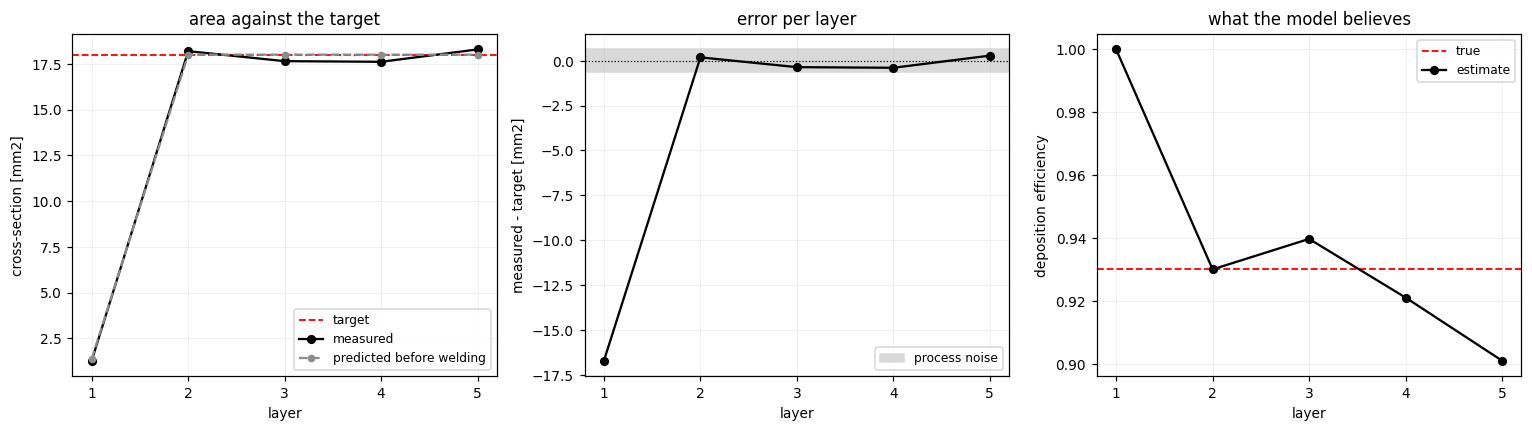

In [28]:
def plot_rehearsal(history, target_mm2, noise_floor, true_eta):
    layers = [r['layer'] for r in history]
    fig, ax = plt.subplots(1, 3, figsize=(14, 4.0))

    ax[0].axhline(target_mm2, color='r', lw=1.2, ls='--', label='target')
    ax[0].plot(layers, [r['measured'] for r in history], 'ko-', ms=5, label='measured')
    ax[0].plot(layers, [r['predicted'] for r in history], 'o--', ms=4, color='0.55',
               label='predicted before welding')
    ax[0].set_ylabel('cross-section [mm2]')
    ax[0].set_title('area against the target')
    ax[0].legend(fontsize=8)

    ax[1].axhspan(-noise_floor, noise_floor, color='0.85', label='process noise')
    ax[1].axhline(0, color='k', lw=0.8, ls=':')
    ax[1].plot(layers, [r['error'] for r in history], 'ko-', ms=5)
    ax[1].set_ylabel('measured - target [mm2]')
    ax[1].set_title('error per layer')
    ax[1].legend(fontsize=8)

    ax[2].axhline(true_eta, color='r', lw=1.2, ls='--', label='true')
    ax[2].plot(layers, [r['eta_used'] for r in history], 'ko-', ms=5, label='estimate')
    ax[2].set_ylabel('deposition efficiency')
    ax[2].set_title('what the model believes')
    ax[2].legend(fontsize=8)

    for axis in ax:
        axis.set_xlabel('layer')
        axis.set_xticks(layers)
        axis.grid(alpha=0.3, lw=0.4)
    fig.tight_layout()
    plt.show()


plot_rehearsal(history, TARGET_AREA_MM2, noise_floor, SIM_TRUE_ETA)

**How to read the rehearsal.**

* Left: measured area per layer against the target, with the prediction the model
  made *before* that layer was welded. Layer 1's prediction is deliberately wrong —
  $\eta$ starts at the ideal 1.0, and the first layer is what corrects it.
* Middle: error per layer with the process-noise band behind it. **Good:** the error
  drops into the band by layer 2 and stays there. **Problem:** a trend that keeps
  drifting after layer 2 means $\eta$ itself is moving — heat accumulating,
  stick-out changing as the wall grows — and one scalar correction is no longer
  enough.
* Right: the estimate of $\eta$ converging on the truth.

The step from layer 1 to layer 2 corrects a *systematic* error and is large.
Everything after it chases *random* error and is small. That is the same split the
boxplots in section 8 make within a single bead: a controller removes the first and
cannot remove the second.

In [29]:
if beads:
    layer = max(beads, key=lambda b: b['length'])
    measured_area = float(np.mean([d['area'] for d in layer['divisions']]))
    eta_hat = efficiency_from(measured_area, start_wfs, TRAVEL_MM_S)
    wfs_next = wfs_for_target(TARGET_AREA_MM2, TRAVEL_MM_S, eta_hat)
    print(f'measured area   {measured_area:.2f} mm2 '
          f'(mean over {len(layer["divisions"])} divisions)')
    print(f'implied eta     {eta_hat:.3f}')
    print(f'next layer      {wfs_next / IPM_TO_MM_S:.1f} IPM ({wfs_next:.2f} mm/s) '
          f'at {TRAVEL_MM_S} mm/s travel')
    if wfs_next / IPM_TO_MM_S > MAX_WFS_IPM:
        print(f'\nAbove the {MAX_WFS_IPM:.0f} IPM ceiling: this target area is not '
              'reachable at this travel speed. Lower TARGET_AREA_MM2, or slow the '
              'travel speed to raise lambda without more wire.')
    if not 0.3 <= eta_hat <= 1.0:
        print('\nOutside the physical range 0.3 to 1.0: this scan was not welded at '
              'the parameters above, or WIRE_DIA_MM does not match the machine.')
    bow_along = identifiable_deformation(deformation_coef)['bow along (v)']
    if abs(bow_along) > 0.5:
        print(f'\nBow along travel is {bow_along:+.2f} mm. Heat is bending the plate, so '
              'part of the height change between layers is the substrate moving, not '
              'the bead growing. Re-level against the current scan before trusting '
              'the next height reading.')
else:
    print(NO_BEADS)
    print('The recommendation needs one measured layer. Weld layer 1 at the starting '
          'parameters above, scan it, and run this notebook again.')

measured area   5.88 mm2 (mean over 10 divisions)
implied eta     4.247
next layer      76.5 IPM (32.38 mm/s) at 6.0 mm/s travel

Outside the physical range 0.3 to 1.0: this scan was not welded at the parameters above, or WIRE_DIA_MM does not match the machine.

Bow along travel is -1.00 mm. Heat is bending the plate, so part of the height change between layers is the substrate moving, not the bead growing. Re-level against the current scan before trusting the next height reading.


**Using the recommendation.** The number printed is the wire feed speed for the
*next* layer, derived from the layer just measured. It assumes travel speed stays
fixed and that voltage is set for a stable arc at that wire feed speed — which is
what the sweep in section 9 is for.

Two limits worth stating. The update uses the most recent layer only, so a single
bad scan moves the recommendation as much as a real process change; with more
layers in hand, averaging the last two or three estimates of $\eta$ is the obvious
next step. And the correction is a scalar: it moves the whole layer up or down and
cannot fix a bead that is non-uniform *along* its own travel. That failure mode is
what the boxplots in section 8 detect, and it needs a correction that varies along
the path rather than one number per layer.

## 11. The welding log and the mass balance

Each bead measured in section 7 is paired here with the settings it was welded
with, and all of them together test the mass balance. Linking the scan to the
robot, so a bead can be welded where it was planned, comes later, in section 13.

### The test matrix and the welding log

The run table has two parts. Schedules 1 to 6 vary travel speed (20, 25 and
30 IPM). From schedule 7 on, travel speed is fixed at 25 IPM and the runs cover
the plane of wire feed {300, 225, 150} IPM against voltage {16, 18, 20} V, the
process map Dr. Landers asked for. All runs use a 0.3 in stick-out and a
0.035 in tip-to-plate gap. Results accumulate in a CSV between scans.

Two scans of the same plate feed it. `nubec.ply` holds the twelve short beads of
schedules 1 to 10 and writes under `plate-1`. `cloud0.ply` is the long-bead side
and writes under `plate-1b`: one single-schedule bead, A (schedule 11), and four
lines welded in stretches. B2 and B3 were already in `nubec.ply`. C was cut twice
on its way. D is five stretches end to end, welded with schedules 1 to 5 as
re-entered for it: 25 IPM travel and wire feed 300, 250, 200, 150 and 150 IPM. The last stretch was commanded as 100 IPM, but it ran at 150 IPM, so `D5` repeats `D4`.
Each stretch of D enters the results as its own row, `D1` to `D5`. `TEST_MATRIX`
keeps schedules 1 to 5 as they were when the short beads were welded.

`TEST_MATRIX` is the design and does not change. `PLATE_BEADS` says which test
each bead on *this* plate was welded with, in the stack order section 7 assigned.
Get that mapping wrong and the regression pairs areas with the wrong parameters:
the symptom is a negative correlation between $\lambda$ and area, which is
physically impossible, since more wire per millimetre cannot deposit less metal.

In [30]:
RESULTS_CSV = Path('results/bead_areas.csv')   # accumulates across scans
IPM_TO_MM_S = 25.4 / 60

TEST_MATRIX = {               # schedule -> (WFS ipm, travel ipm, voltage)
     1: (325, 25, 16),   2: (325, 20, 18),   3: (300, 25, 18),
     4: (300, 20, 16),   5: (325, 30, 18),   6: (300, 20, 20),
     7: (300, 25, 16),   8: (300, 25, 18),   9: (300, 25, 20),
    10: (225, 25, 16),  11: (225, 25, 18),  12: (225, 25, 20),
    13: (150, 25, 16),  14: (150, 25, 18),  15: (150, 25, 20),
}

# Runs outside the 15-test design, welded on purpose or by mistake. A bead welded
# at known settings is a point on the fit whatever plan it belonged to.
EXTRA_SCHEDULES = {
    'A1': (276, 23, 16),      # lambda = 12 series, welded before schedule 6
    'A2': (276, 23, 17),
}

# Lines welded with more than one schedule, by plate: where each stretch begins
# [mm from the welded start, None = the end of the bead] and what it was welded
# with. own_starts says whether every stretch began with a new arc start or the
# schedule changed with the arc on. A line with 'tests' gives one row of results
# per stretch.
B2_B3 = dict(
    B2=dict(own_starts=False, edges=[0, 50, None], wfs=[300, 150], travel=25,
            voltage=18, feedback=[(169.8, 18.1), (104.6, 18.1)]),
    B3=dict(own_starts=False, edges=[0, 60, 65, 70, 75, None],
            wfs=[300, 262.5, 225, 187.5, 150], travel=25, voltage=18,
            feedback=[(175.4, 17.9), (164.2, 16.8), (139.7, 16.9),
                      (120.6, 17.5), (39.5, 25.5)]))
LONG_BEADS_BY_PLATE = {
    'plate-1': {name: dict(spec, start='-x') for name, spec in B2_B3.items()},
    'plate-1b': {
        # D: schedules 1 to 5 as re-entered for it, travel fixed, 18 V and wire feed
        # stepping down. TEST_MATRIX keeps 1 to 5 as they were when the short beads
        # of plate-1 were welded.
        'D': dict(start='+y', own_starts=True, edges=[0, 19.5, 38.5, 57.5, 78.0, None],
                  wfs=[300, 250, 200, 150, 150], travel=25, voltage=18,
                  feedback=[(149.4, 18.2), (144.6, 17.8), (117.7, 17.9), (72.6, 17.8),
                            (91.1, 17.6)],
                  tests=['D1', 'D2', 'D3', 'D4', 'D5']),
        **{name: dict(spec, start='-y') for name, spec in B2_B3.items()},
        # A: one schedule and one start. As a line of one stretch it shows what its
        # whole-bead mean hides: the level it settles to, and its start.
        'A': dict(start='+y', own_starts=True, edges=[0, None], wfs=[225], travel=25,
                  voltage=18, feedback=None)},
}
LONG_BEADS_BY_PLATE['plate-1c'] = {
    # Two lines of five schedules, 25.4 mm each, changed with the arc on.
    # W: 18 V, wire feed stepping down. V: 225 IPM, voltage stepping down.
    # The changes of W land 6 mm before their programmed place and 25.0 mm apart;
    # its edges are where the fit of the next section finds them. In V the area
    # does not step, the changes cannot be located, and the edges are the
    # programmed ones.
    'W': dict(start='+y', own_starts=False, edges=[0, 19.1, 44.2, 69.2, 94.2, None],
              pitch=25.4,
              wfs=[300, 262.5, 225, 187.5, 150], travel=25, voltage=18,
              feedback=[(161.0, 17.9), (147.2, 17.8), (137.4, 17.9), (121.2, 17.8),
                        (74.4, 17.0)],
              tests=['W1', 'W2', 'W3', 'W4', 'W5']),
    'V': dict(start='+x', own_starts=False, edges=[0, 25.4, 50.8, 76.2, 101.6, None],
              pitch=25.4,
              wfs=[225, 225, 225, 225, 225], travel=25, voltage=[20, 19, 18, 17, 16],
              feedback=[(133.4, 19.8), (138.5, 18.8), (126.8, 18.0), (132.8, 16.9),
                        (136.3, 15.8)],
              tests=['V1', 'V2', 'V3', 'V4', 'V5']),
}
CUT_BEADS_BY_PLATE = {      # lines that stopped and started again by themselves
    'plate-1b': {'C': dict(start='-y')},
}
LONG_BEADS = LONG_BEADS_BY_PLATE.get(PLATE_ID, {})
CUT_BEADS = CUT_BEADS_BY_PLATE.get(PLATE_ID, {})

# A row left out of the slope, with the reason. It stays in the table and on the
# plot.
FIT_LEAVE_OUT = {
    'W1': 'opened by the arc start and 19 mm long: the level is still coming down '
          'from the start when the next change arrives',
}

def stretch_voltages(spec):
    """Voltage of every stretch of a line: one value for the line, or one each."""
    volts = spec['voltage']
    if not isinstance(volts, (list, tuple)):
        volts = [float('nan') if volts is None else volts] * len(spec['wfs'])
    return list(volts)


STAGE_SCHEDULES = {
    test: (wfs, spec['travel'], volts)
    for lines in LONG_BEADS_BY_PLATE.values() for spec in lines.values()
    for test, wfs, volts in zip(spec.get('tests', []), spec['wfs'],
                                stretch_voltages(spec))}
SCHEDULES = {**TEST_MATRIX, **EXTRA_SCHEDULES, **STAGE_SCHEDULES}


# What the arc actually did, from the Power Wave Manager weld schedule export:
# (feedback arc current A, feedback arc voltage V). Commanded voltage is what was
# asked for; current is never commanded, so this is the only record of it.
ARC_FEEDBACK = {
    1: (192.8, 15.9),   2: (174.4, 18.3),   3: (185.6, 18.0),
    4: (181.1, 16.2),   5: (198.6, 17.7),
    'A1': (148.9, 16.3), 'A2': (164.6, 16.8),
    7: (125.3, 16.5),   8: (152.9, 17.8),   9: (166.7, 20.2),
    10: (118.4, 16.2),
    11: (127.5, 18.0),
    'D1': (149.4, 18.2), 'D2': (144.6, 17.8), 'D3': (117.7, 17.9),
    'D4': (72.6, 17.8), 'D5': (91.1, 17.6),
    11: (127.5, 18.0),
    12: (131.3, 19.5),  13: (92.5, 16.1),
    **{test: pair for spec in LONG_BEADS_BY_PLATE['plate-1c'].values()
       for test, pair in zip(spec['tests'], spec['feedback'])},
}

# One entry per bead on the plate, in the stack order section 7 prints. None is a
# bead that is on the plate but whose settings are not known: it is measured and
# left out of the fit.
PLATE_BEADS = {
    'plate-1': [1, 2, 3, 4, 5, 'A1', 'A2', 6, 7, 8, 9, 10, None, None],  # nubec.ply
    'plate-1b': [None, None, None, None, 11],     # cloud0.ply: D, C, B3, B2, A
    # decay.ply: C3, D, B2, B3, W, C1, A, S12, S13, V. A is schedule 11 again,
    # already a row of plate-1b, so it is measured here and not recorded twice.
    'plate-1c': [None, None, None, None, None, None, None, 12, 13, None],
}


def schedule_row(test_id):
    wfs, travel, voltage = SCHEDULES[test_id]
    amps, volts = ARC_FEEDBACK.get(test_id, (float('nan'), float('nan')))
    power = amps * volts
    return dict(test=test_id, wfs_ipm=wfs, travel_ipm=travel, voltage=voltage,
                current_a=amps, voltage_fb=volts, power_w=power,
                heat_j_mm=power / (travel * IPM_TO_MM_S), **{'lambda': wfs / travel})


plate_list = PLATE_BEADS.get(PLATE_ID, [])
WELDING_LOG = []
for bead_number, test_id in enumerate(plate_list, start=1):
    if test_id is not None:
        row = schedule_row(test_id)
        row['bead'] = bead_number
        WELDING_LOG.append(row)

lam_all = np.array([w / t for w, t, _ in TEST_MATRIX.values()])
print(f'design          {len(TEST_MATRIX)} tests, lambda {lam_all.min():.2f} '
      f'to {lam_all.max():.2f}, plus {len(EXTRA_SCHEDULES)} runs outside it')
print(f'this plate      {PLATE_ID}: {len(plate_list)} beads, '
      f'{len(WELDING_LOG)} with known settings')
unknown = [n for n, t in enumerate(plate_list, start=1) if t is None]
in_stretches = [n for n in unknown if POSITIONS.get(n) in {**LONG_BEADS, **CUT_BEADS}]
unknown = [n for n in unknown if n not in in_stretches]
if in_stretches:
    print(f'lines           bead(s) {in_stretches} were welded in stretches or cut, '
          'and are taken up below')
if unknown:
    print(f'no settings for bead(s) {unknown}: measured, kept out of the fit')
welded = {t for ids in PLATE_BEADS.values() for t in ids if t is not None}
unassigned = sorted(set(TEST_MATRIX) - welded)
if unassigned:
    print(f'not yet welded  {unassigned}')

if WELDING_LOG:
    print(f'\n{"bead":>5} {"test":>5} {"V set":>6} {"V arc":>6} {"diff":>6} '
          f'{"I arc":>7} {"power":>7} {"heat in":>9}')
    for row in WELDING_LOG:
        print(f'{row["bead"]:>5} {str(row["test"]):>5} {row["voltage"]:>6.1f} '
              f'{row["voltage_fb"]:>6.1f} {row["voltage_fb"] - row["voltage"]:>+6.1f} '
              f'{row["current_a"]:>7.1f} {row["power_w"]:>6.0f}W '
              f'{row["heat_j_mm"]:>6.0f}J/mm')
    drift = [abs(r['voltage_fb'] - r['voltage']) for r in WELDING_LOG
             if np.isfinite(r['voltage_fb'])]
    if drift and max(drift) > 0.5:
        print('\nArc voltage more than 0.5 V off its setpoint on at least one run: '
              'the source did not hold what it was asked for there.')

repeats = {}
for test_id, spec in SCHEDULES.items():
    repeats.setdefault(spec, []).append(test_id)
duplicated = {s: ids for s, ids in repeats.items() if len(ids) > 1}
if duplicated:
    print('\nrepeated parameter sets, free estimates of process spread once welded:')
    for spec, ids in duplicated.items():
        print(f'   {ids} share WFS {spec[0]}, TS {spec[1]}, {spec[2]} V')

design          15 tests, lambda 6.00 to 16.25, plus 2 runs outside it
this plate      plate-1c: 10 beads, 2 with known settings
lines           bead(s) [5, 10] were welded in stretches or cut, and are taken up below
no settings for bead(s) [1, 2, 3, 4, 6, 7]: measured, kept out of the fit
not yet welded  [14, 15]

 bead  test  V set  V arc   diff   I arc   power   heat in
    8    12   20.0   19.5   -0.5   131.3   2560W    242J/mm
    9    13   16.0   16.1   +0.1    92.5   1489W    141J/mm

repeated parameter sets, free estimates of process spread once welded:
   [3, 8, 'D1', 'W1'] share WFS 300, TS 25, 18 V
   [10, 'V5'] share WFS 225, TS 25, 16 V
   [11, 'W3', 'V3'] share WFS 225, TS 25, 18 V
   [12, 'V1'] share WFS 225, TS 25, 20 V
   [14, 'D4', 'D5', 'W5'] share WFS 150, TS 25, 18 V


### Lines welded in stretches

A line welded with more than one schedule leaves one stretch of bead per schedule.
Ten equal divisions cannot follow that, so these lines are cut into slices of
`SLICE_MM` along the centreline. Each slice gives a cross-section (the transverse
profile integrated over mask and skirt, as in section 7), a crest height and a
width at `TOE_MM` above the plate.

$$A(s) = \sum_{k} \bar h_k(s)\,\Delta t, \qquad
s \in [s_j, s_j + \Delta s]$$

where $s$ is distance along the line from the welded end of its mask [mm],
$\bar h_k$ the mean height in transverse bin $k$ of the slice [mm] and $\Delta t$
the cell size [mm]. The mask begins where the bead is already tall or steep enough
to be told from the plate, a couple of mm after the first metal, so $s = 0$ is not
the tip of the bead.

Every stretch gets two numbers. *Metal* is the volume between its limits: what the
wire fed during that stretch left on the plate. *Settled* is the mean
cross-section away from the transients. `SETTLE_MM` is left out after an arc
start, where the start piles metal up, and `END_MM` before an arc end or the next
start; where the schedule changes with the arc on, `EDGE_MM` is left out on both
sides instead. A stretch whose window still spans more than `STEADY_SPAN` of its
own mean has not settled, and is marked.

D was welded as five separate starts, each beginning where the last one ended. Its
limits are where the cross-section turns up into the next start, read off the
profile below; if the pitch in the robot program is known, that is what belongs in
`edges`. B2 and B3 changed schedule with the arc on, and their limits are the
positions in the robot program. A is a single bead. It enters here as a line of
one stretch, so that its start and the level behind it can be told apart.

In [31]:
SLICE_MM = 1.0      # slice length along a line
EDGE_MM = 3.0       # left out on both sides of a schedule change made with the arc on
SETTLE_MM = 9.0     # left out after an arc start, where the start piles metal up
END_MM = 4.0        # left out before an arc end or the next start
TOE_MM = 0.15       # height at which the width of a slice is read
STEADY_SPAN = 0.35  # settled if the window spans less than this share of its mean


def along_profile(bead, slice_mm, cell_mm, start):
    """Cross-section, crest height and width of every slice of a bead, against
    distance from its welded start."""
    s, t, h = bead['profile']
    first, last = bead['path'][0], bead['path'][-1]
    axis = 0 if start.endswith('x') else 1
    flip = (first[axis] > last[axis]) == start.startswith('-')
    s = s.max() - s if flip else s - s.min()
    edges = np.arange(0, s.max() + slice_mm, slice_mm)
    rows = []
    for a, b in zip(edges[:-1], edges[1:]):
        take = (s >= a) & (s < b)
        if take.sum() < 8:
            rows.append((0.5 * (a + b), 0.0, 0.0, 0.0))
            continue
        order = np.argsort(t[take])
        tt, hh = t[take][order], h[take][order]
        bins = np.floor(tt / cell_mm).astype(int)
        across = np.array([chunk.mean() for chunk in
                           np.split(hh, np.flatnonzero(np.diff(bins)) + 1)])
        rows.append((0.5 * (a + b), float(across.sum() * cell_mm),
                     float(across.max()), float((across > TOE_MM).sum() * cell_mm)))
    return np.array(rows)


def stretch_table(prof, spec):
    """One row per stretch of a line: its limits, the metal in it, and the level
    the cross-section settles to away from the start and the end."""
    edges = list(spec['edges'])
    if edges[-1] is None:
        edges[-1] = float(prof[-1, 0] + 0.5 * SLICE_MM)
    last = len(spec['wfs']) - 1
    rows = []
    for k, wfs in enumerate(spec['wfs']):
        a, b = edges[k], edges[k + 1]
        trim = min(EDGE_MM, 0.25 * (b - a))
        lo = a + (SETTLE_MM if k == 0 or spec['own_starts'] else trim)
        hi = b - (END_MM if k == last or spec['own_starts'] else trim)
        if hi - lo < 2 * SLICE_MM:
            lo, hi = a + 0.25 * (b - a), b - 0.25 * (b - a)
        inside = (prof[:, 0] >= a) & (prof[:, 0] < b)
        window = (prof[:, 0] >= lo) & (prof[:, 0] < hi)
        level = prof[window, 1]
        rows.append(dict(
            stretch=k + 1, a=a, b=b, lo=lo, hi=hi, wfs=wfs, lam=wfs / spec['travel'],
            metal=float(prof[inside, 1].sum() * SLICE_MM),
            settled=float(level.mean()), sd=float(level.std()), n=int(window.sum()),
            crest=float(prof[window, 2].mean()), width=float(prof[window, 3].mean()),
            peak=float(prof[inside, 1].max()),
            peak_at=float(prof[inside, 0][np.argmax(prof[inside, 1])]),
            steady=bool(np.ptp(level) < STEADY_SPAN * level.mean())))
    return rows


by_name = {POSITIONS.get(b['id']): b for b in beads}
long_results, STAGE_LOG, stage_summaries = {}, [], {}
for name, spec in LONG_BEADS.items():
    bead = by_name.get(name)
    if bead is None:
        print(f'{name}: not among the measured beads')
        continue
    prof = along_profile(bead, SLICE_MM, CELL_MM, spec['start'])
    rows = stretch_table(prof, spec)
    long_results[name] = (bead, prof, rows)
    feedback = spec.get('feedback') or [(float('nan'), float('nan'))] * len(rows)
    print(f'{name} (bead {bead["id"]}): {bead["length"]:.1f} mm, '
          + ('a new arc start at every stretch' if spec['own_starts']
             else 'schedule changed with the arc on'))
    print(f'   {"":>2} {"from-to mm":>11} {"WFS":>6} {"lambda":>7} {"I fb":>6} {"V fb":>5} '
          f'{"metal":>6} {"settled":>8} {"sd":>5} {"crest":>6} {"width":>6} {"peak":>6}')
    for row, (amps, volts) in zip(rows, feedback):
        print(f'   {row["stretch"]:>2} {row["a"]:>5.1f}-{row["b"]:<5.1f} {row["wfs"]:>6.1f} '
              f'{row["lam"]:>7.2f} {amps:>6.1f} {volts:>5.1f} {row["metal"]:>6.0f} '
              f'{row["settled"]:>8.2f} {row["sd"]:>5.2f} {row["crest"]:>6.2f} '
              f'{row["width"]:>6.2f} {row["peak"]:>6.2f}'
              + ('' if row['steady'] else '   not settled'))
    for row, test in zip(rows, spec.get('tests', [])):
        entry = schedule_row(test)
        entry['bead'] = len(plate_list) + len(STAGE_LOG) + 1
        STAGE_LOG.append(entry)
        stage_summaries[entry['bead']] = dict(
            area=row['settled'], width=row['width'], height=row['crest'],
            length=row['b'] - row['a'], kind='stretch')
print('metal in mm3; settled, sd and peak in mm2; crest and width in mm; '
      'I and V are the Power Wave feedback of each schedule')
if STAGE_LOG:
    print(f'{len(STAGE_LOG)} stretches go into the results as rows of their own: '
          + ', '.join(str(e['test']) for e in STAGE_LOG))

with open(OUT_DIR / 'line_profiles.csv', 'w', newline='') as handle:
    writer = csv.writer(handle)
    writer.writerow(['plate', 'line', 's_mm', 'area_mm2', 'crest_mm', 'width_mm'])
    for name in list(long_results) + [n for n in CUT_BEADS if n in by_name]:
        prof = (long_results[name][1] if name in long_results else
                along_profile(by_name[name], SLICE_MM, CELL_MM, CUT_BEADS[name]['start']))
        writer.writerows([PLATE_ID, name, f'{r[0]:.1f}', f'{r[1]:.3f}', f'{r[2]:.3f}',
                          f'{r[3]:.2f}'] for r in prof)

W (bead 5): 118.0 mm, schedule changed with the arc on
       from-to mm    WFS  lambda   I fb  V fb  metal  settled    sd  crest  width   peak
    1   0.0-19.1   300.0   12.00  161.0  17.9    172     8.19  0.43   2.16   5.59  11.78
    2  19.1-44.2   262.5   10.50  147.2  17.8    175     7.02  0.08   1.97   5.60   7.32
    3  44.2-69.2   225.0    9.00  137.4  17.9    155     6.19  0.26   1.82   5.70   6.52
    4  69.2-94.2   187.5    7.50  121.2  17.8    130     5.23  0.20   1.72   5.30   5.66
    5  94.2-119.0  150.0    6.00   74.4  17.0     92     3.61  0.30   1.52   3.23   4.49
V (bead 10): 124.2 mm, schedule changed with the arc on
       from-to mm    WFS  lambda   I fb  V fb  metal  settled    sd  crest  width   peak
    1   0.0-25.4   225.0    9.00  133.4  19.8    145     5.42  0.24   1.55   5.65   7.49
    2  25.4-50.8   225.0    9.00  138.5  18.8    149     5.72  0.15   1.57   5.59   6.03
    3  50.8-76.2   225.0    9.00  126.8  18.0    148     5.88  0.22   1.68   5.33   6.44

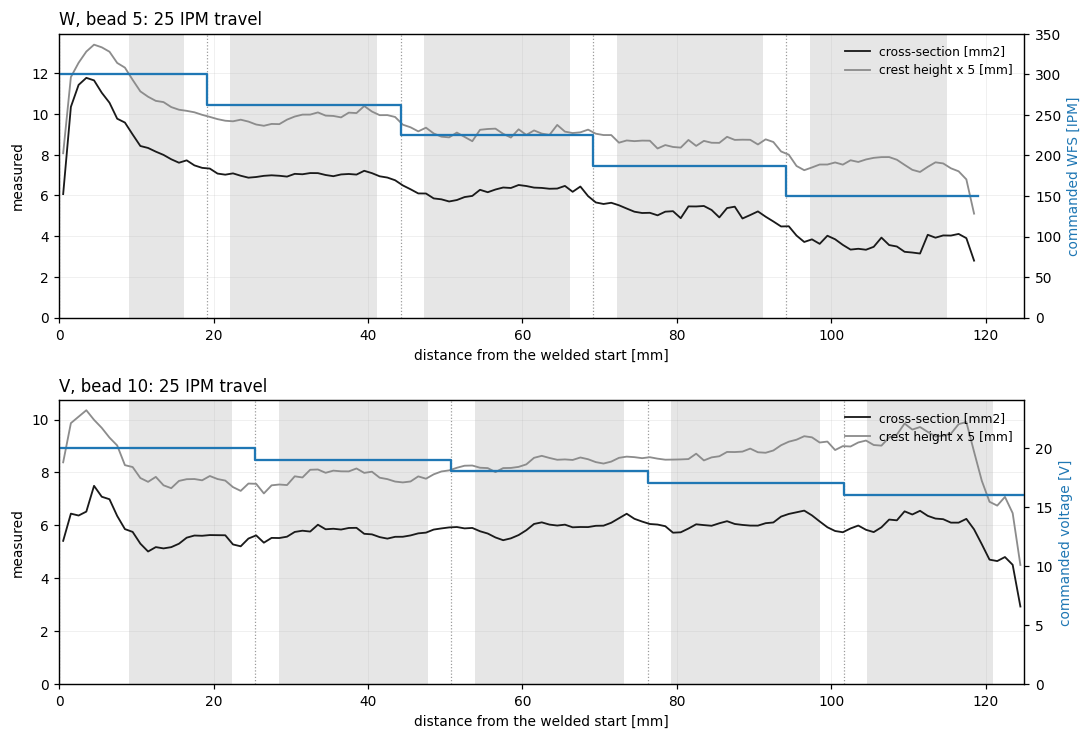

In [32]:
if long_results:
    fig, axes = plt.subplots(len(long_results), 1, figsize=(10, 3.4 * len(long_results)),
                             squeeze=False)
    for ax, (name, (bead, prof, rows)) in zip(axes[:, 0], long_results.items()):
        for row in rows:
            ax.axvspan(row['lo'], row['hi'], color='0.9', lw=0)
            ax.axvline(row['a'], color='0.6', lw=0.8, ls=':')
        ax.plot(prof[:, 0], prof[:, 1], '-', color='0.1', lw=1.2,
                label='cross-section [mm2]')
        ax.plot(prof[:, 0], prof[:, 2] * 5, '-', color='0.55', lw=1.2,
                label='crest height x 5 [mm]')
        ax.set_xlabel('distance from the welded start [mm]')
        ax.set_ylabel('measured')
        ax.set_xlim(0, max(r[2][-1]['b'] for r in long_results.values()))
        ax.set_ylim(0, None)
        twin = ax.twinx()
        volts = stretch_voltages(LONG_BEADS[name])
        by_voltage = len(set(volts)) > 1
        twin.step([r['a'] for r in rows] + [rows[-1]['b']],
                  (volts + volts[-1:]) if by_voltage
                  else [r['wfs'] for r in rows] + [rows[-1]['wfs']], where='post',
                  color='tab:blue', lw=1.5)
        twin.set_ylabel('commanded voltage [V]' if by_voltage else 'commanded WFS [IPM]',
                        color='tab:blue')
        twin.set_ylim(0, 24 if by_voltage else 350)
        ax.set_title(f'{name}, bead {bead["id"]}: {LONG_BEADS[name]["travel"]} IPM travel',
                     loc='left')
        ax.legend(fontsize=8, frameon=False, loc='upper right')
        ax.grid(alpha=0.3, lw=0.4)
    fig.tight_layout()
    plt.show()

**How to read the lines.** Black is the cross-section of each slice, grey the
crest height (scaled by 5 to share the axis), blue the commanded wire feed, and
the shaded bands are the windows the settled level is taken from. All panels share
one scale along the line. If the deposit follows the wire, the black line steps
down where the blue line does, and by the same fraction.

In D every stretch opens with a hump, and so does A: a start leaves more metal
than the travel behind it. The level behind the hump is what the schedule gives
once the torch is moving, and that is the number to compare with the wire feed. A
stretch marked *not settled* is too short for its own start: its level is still
falling when the next start arrives.

B2 and B3 are the two beads `nubec.ply` already showed. In both, the cross-section
drops tens of mm before the programmed step, which is the arc or the feeder and
not the schedule.

### Lines changed with the arc on: where a change lands and how long it takes

W and V were welded in one pass each, with the schedule changed every 25.4 mm
while the arc stayed on. The cross-section along such a line is modelled as one
level per stretch, joined by steps of one width:

$$A(s) = A_1 + \sum_{k=1}^{n-1} (A_{k+1} - A_k)\;
\tfrac12\!\left[1 + \operatorname{erf}\!\left(\frac{s - s_1 - (k-1)\,p}{\sqrt2\,\sigma}\right)\right]$$

with $s$ the distance from the scanned start [mm], $A_k$ the level of stretch $k$
[mm²], $s_1$ where the first change lands, $p$ the spacing between changes and
$\sigma$ the width of a step. The two ends of the line and the metal piled up at
the start are fitted with it and are not reported. A step goes from 10% to 90% of
its height over $2.56\,\sigma$.

The fit is run twice, once with $s_1$ and $p$ free and once with both at the
programmed 25.4 mm. Where the free fit is no better, the changes cannot be
located from that line and the programmed places are kept.

W: fitted on the cross-section, residual 0.204 mm2 with the changes free, 0.333 with them at 25.4 mm
   changes at     19.1, 44.2, 69.2, 94.2 mm from the scanned start, 25.0 mm apart (programmed 25.4)
   first change   +6.3 mm before its programmed place
   step width     sigma 1.95 mm: 10% to 90% over 5.0 mm, 0.47 s at 25 IPM
   levels         7.69, 7.01, 6.20, 5.23, 3.66 mm2, from the fit, with the start taken out
     change           WFS     level mm2   drop  drop %  wire %
          1  300.0>262.5    7.69>7.01     0.68    8.9%   12.5%
          2  262.5>225.0    7.01>6.20     0.81   11.5%   14.3%
          3  225.0>187.5    6.20>5.23     0.97   15.6%   16.7%
          4  187.5>150.0    5.23>3.66     1.57   30.1%   20.0%
   whole line     7.69 to 3.66 mm2, 52% down for 50% less wire
   A = m lambda   m = 0.6619 on this line alone; with an intercept, 0.6566 lambda +0.05 mm2
V: fitted on the crest height, residual 0.045 mm with the changes free, 0.048 with them at 25.4 mm
   the free

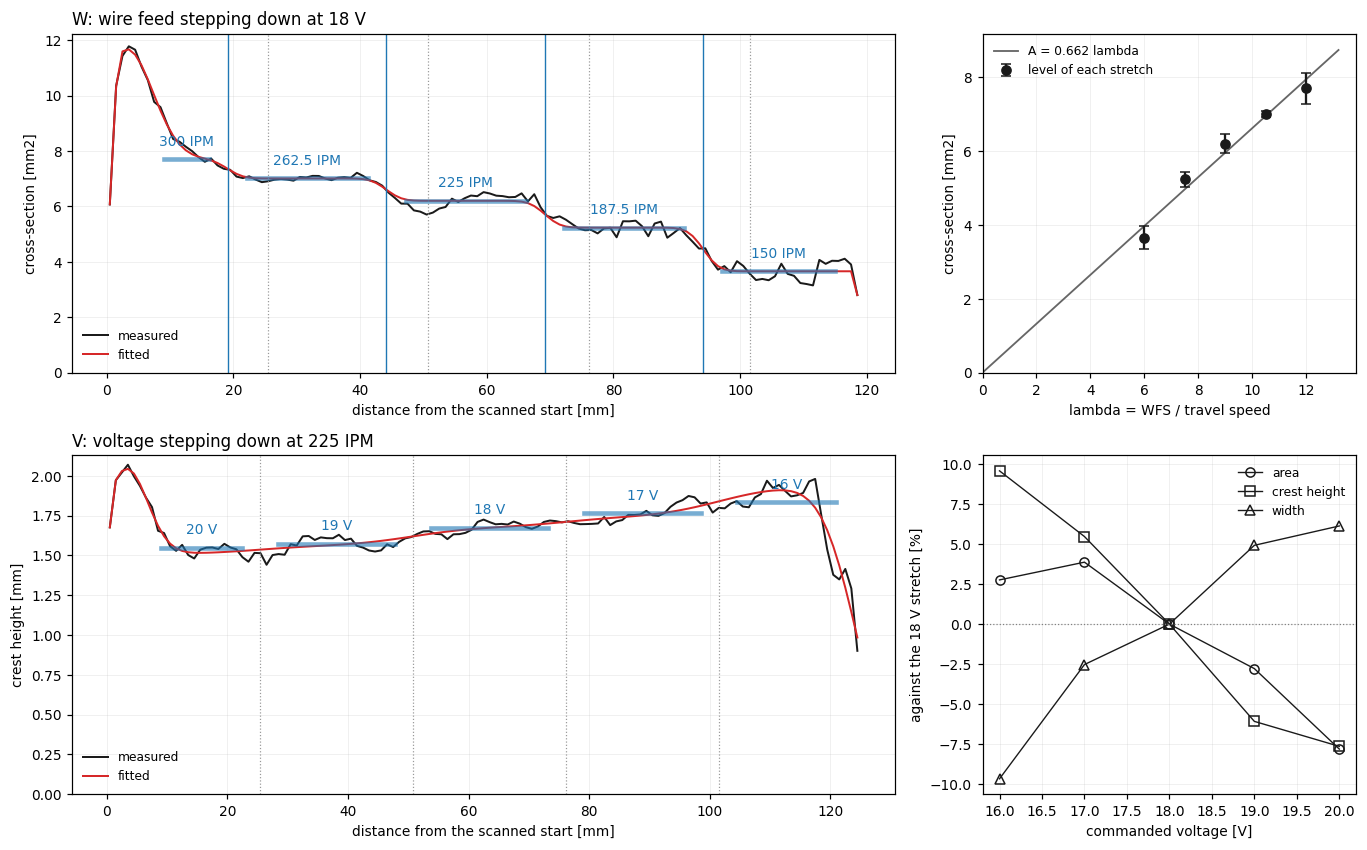

In [33]:
RISE_PER_SIGMA = 2.563    # 10 % to 90 % of an error-function step
LOCATED_GAIN = 0.90       # free fit must cut the residual below this share
PITCH_TOL_MM = 1.5        # the robot spaces the changes; the fit may move them this much


def line_model(q, s, n):
    """One level per stretch joined by steps of one width, between two rounded
    ends, plus the metal the start piles up."""
    levels, (first, pitch, sigma) = q[:n], q[n:n + 3]
    hump, hump_at, hump_sd, a0, sa, a1, sb = q[n + 3:]

    def step(at, sd):
        return 0.5 * (1 + special.erf((s - at) / (np.sqrt(2) * sd)))

    y = np.full_like(s, levels[0])
    for k in range(1, n):
        y = y + (levels[k] - levels[k - 1]) * step(first + pitch * (k - 1), sigma)
    return (y * (step(a0, sa) - step(a1, sb))
            + hump * np.exp(-0.5 * ((s - hump_at) / hump_sd) ** 2))


def fit_changes(prof, column, n, pitch, free):
    s, y = prof[:, 0], prof[:, column]
    top = float(y.max())
    q0 = [float(np.median(y))] * n + [pitch, pitch, 2.0,
                                      0.3 * top, 4.0, 3.0, 0.0, 1.5, s[-1] + 0.5, 1.5]
    lo = [0.0] * n + [pitch - 12, pitch - PITCH_TOL_MM, 0.3, 0.0, 0.0, 1.0, -3.0, 0.3,
                      s[-1] - 8, 0.3]
    hi = [2 * top] * n + [pitch + 12, pitch + PITCH_TOL_MM, 8.0, top, 10.0, 8.0, 3.0, 5.0,
                          s[-1] + 5, 5.0]
    if not free:
        lo[n], hi[n], lo[n + 1], hi[n + 1] = (pitch - 1e-6, pitch + 1e-6,
                                              pitch - 1e-6, pitch + 1e-6)
    best = None
    for shift in ((-8, -4, 0, 4, 8) if free else (0,)):
        start = list(q0)
        start[n] = pitch + shift
        fit = optimize.least_squares(lambda q: line_model(q, s, n) - y, start,
                                     bounds=(lo, hi))
        if best is None or fit.cost < best.cost:
            best = fit
    return best.x, float(np.sqrt(np.mean(best.fun ** 2)))


CHANGES = {}
for name, (bead, prof, rows) in long_results.items():
    spec = LONG_BEADS[name]
    if spec['own_starts'] or len(rows) < 2 or 'pitch' not in spec:
        continue
    volts = stretch_voltages(spec)
    by_voltage = len(set(volts)) > 1
    column, what, unit = (2, 'crest height', 'mm') if by_voltage else (1, 'cross-section', 'mm2')
    n, pitch = len(rows), spec['pitch']
    q_free, rms_free = fit_changes(prof, column, n, pitch, free=True)
    q_nom, rms_nom = fit_changes(prof, column, n, pitch, free=False)
    located = rms_free < LOCATED_GAIN * rms_nom
    q = q_free if located else q_nom
    CHANGES[name] = dict(q=q, column=column, located=located, by_voltage=by_voltage,
                         volts=volts, rows=rows, prof=prof)
    first, found_pitch, sigma = q[n:n + 3]
    speed = spec['travel'] * IPM_TO_MM_S
    print(f'{name}: fitted on the {what}, residual {rms_free:.3f} {unit} with the '
          f'changes free, {rms_nom:.3f} with them at {pitch} mm')
    if located:
        places = [first + found_pitch * k for k in range(n - 1)]
        print('   changes at     ' + ', '.join(f'{p:.1f}' for p in places)
              + f' mm from the scanned start, {found_pitch:.1f} mm apart '
              f'(programmed {pitch})')
        print(f'   first change   {pitch - first:+.1f} mm before its programmed place')
        print(f'   step width     sigma {sigma:.2f} mm: 10% to 90% over '
              f'{RISE_PER_SIGMA * sigma:.1f} mm, {RISE_PER_SIGMA * sigma / speed:.2f} s '
              f'at {spec["travel"]} IPM')
    else:
        print('   the free fit is no better: the changes cannot be located on this '
              'line, and the programmed places are kept')

    if not by_voltage:
        level = (np.asarray(q[:n], float) if located
                 else np.array([r['settled'] for r in rows]))
        lam_line = np.array([r['lam'] for r in rows])
        CHANGES[name]['level'] = level
        print('   levels         ' + ', '.join(f'{v:.2f}' for v in level)
              + (' mm2, from the fit, with the start taken out' if located
                 else ' mm2, settled windows'))
        print(f'   {"change":>8} {"WFS":>13} {"level mm2":>13} {"drop":>6} {"drop %":>7} '
              f'{"wire %":>7}')
        for k in range(1, n):
            print(f'   {k:>8} {rows[k - 1]["wfs"]:>6.1f}>{rows[k]["wfs"]:<6.1f} '
                  f'{level[k - 1]:>6.2f}>{level[k]:<6.2f} {level[k - 1] - level[k]:>6.2f} '
                  f'{100 * (1 - level[k] / level[k - 1]):>6.1f}% '
                  f'{100 * (1 - rows[k]["wfs"] / rows[k - 1]["wfs"]):>6.1f}%')
        slope_line = float(lam_line @ level / (lam_line @ lam_line))
        free_slope, intercept = np.polyfit(lam_line, level, 1)
        print(f'   whole line     {level[0]:.2f} to {level[-1]:.2f} mm2, '
              f'{100 * (1 - level[-1] / level[0]):.0f}% down for '
              f'{100 * (1 - rows[-1]["wfs"] / rows[0]["wfs"]):.0f}% less wire')
        print(f'   A = m lambda   m = {slope_line:.4f} on this line alone; with an '
              f'intercept, {free_slope:.4f} lambda {intercept:+.2f} mm2')
        CHANGES[name]['m'] = slope_line
    else:
        level = np.array([r['settled'] for r in rows])
        crest = np.array([r['crest'] for r in rows])
        width = np.array([r['width'] for r in rows])
        v = np.array(volts, float)
        print(f'   {"stretch":>8} {"V":>5} {"area":>6} {"crest":>6} {"width":>6}')
        for k in range(n):
            print(f'   {k + 1:>8} {v[k]:>5.1f} {level[k]:>6.2f} {crest[k]:>6.2f} '
                  f'{width[k]:>6.2f}')
        per_volt = {label: float(np.polyfit(v, np.log(values), 1)[0])
                    for label, values in (('area', level), ('crest', crest),
                                          ('width', width))}
        print('   per volt up    ' + ', '.join(f'{label} {100 * rate:+.1f}%'
                                               for label, rate in per_volt.items()))
        CHANGES[name]['per_volt'] = per_volt
print('area in mm2, crest and width in mm; width is read at '
      f'{TOE_MM} mm above the plate')

if CHANGES:
    fig, axes = plt.subplots(len(CHANGES), 2, figsize=(12.5, 3.9 * len(CHANGES)),
                             squeeze=False, gridspec_kw=dict(width_ratios=[2.2, 1]))
    for (left, right), (name, c) in zip(axes, CHANGES.items()):
        prof, rows, n, q = c['prof'], c['rows'], len(c['rows']), c['q']
        s = prof[:, 0]
        first, found_pitch = q[n], q[n + 1]
        left.plot(s, prof[:, c['column']], '-', color='0.1', lw=1.3, label='measured')
        left.plot(s, line_model(q, s, n), '-', color='tab:red', lw=1.3, label='fitted')
        for k in range(n - 1):
            left.axvline(LONG_BEADS[name]['pitch'] * (k + 1), color='0.6', lw=0.8, ls=':')
            if c['located']:
                left.axvline(first + found_pitch * k, color='tab:blue', lw=0.9)
        key = 'crest' if c['by_voltage'] else 'settled'
        for r in rows:
            if not c['by_voltage']:
                r = dict(r, settled=float(c['level'][r['stretch'] - 1]))
            left.plot([r['lo'], r['hi']], [r[key]] * 2, '-', color='tab:blue', lw=3,
                      alpha=0.6)
            label = (f"{c['volts'][r['stretch'] - 1]:.0f} V" if c['by_voltage']
                     else f"{r['wfs']:g} IPM")
            left.annotate(label, (0.5 * (r['lo'] + r['hi']), r[key]),
                          textcoords='offset points', xytext=(0, 9), ha='center',
                          fontsize=9, color='tab:blue')
        left.set_xlabel('distance from the scanned start [mm]')
        left.set_ylabel('crest height [mm]' if c['by_voltage'] else 'cross-section [mm2]')
        left.set_ylim(0, None)
        left.set_title(f'{name}: ' + ('voltage stepping down at 225 IPM' if c['by_voltage']
                                      else 'wire feed stepping down at 18 V'), loc='left')
        left.legend(fontsize=8, frameon=False, loc='lower left')
        if c['by_voltage']:
            v = np.array(c['volts'], float)
            base = int(np.argmin(np.abs(v - 18)))
            for key, label, mark in (('settled', 'area', 'o'), ('crest', 'crest height', 's'),
                                     ('width', 'width', '^')):
                values = np.array([r[key] for r in rows])
                right.plot(v, 100 * (values / values[base] - 1), mark + '-',
                           color='0.1', ms=6, fillstyle='none', lw=0.9, label=label)
            right.axhline(0, color='0.5', lw=0.8, ls=':')
            right.set_xlabel('commanded voltage [V]')
            right.set_ylabel('against the 18 V stretch [%]')
            right.legend(fontsize=8, frameon=False)
        else:
            lam_line = np.array([r['lam'] for r in rows])
            level = c['level']
            grid = np.linspace(0, lam_line.max() * 1.1, 20)
            right.plot(grid, c['m'] * grid, '-', color='0.4', lw=1.2,
                       label=f"A = {c['m']:.3f} lambda")
            right.errorbar(lam_line, level, yerr=[r['sd'] for r in rows], fmt='o',
                           color='0.1', ms=6, capsize=3, label='level of each stretch')
            right.set_xlim(0, None)
            right.set_ylim(0, None)
            right.set_xlabel('lambda = WFS / travel speed')
            right.set_ylabel('cross-section [mm2]')
            right.legend(fontsize=8, frameon=False)
        for axis in (left, right):
            axis.grid(alpha=0.3, lw=0.4)
    fig.tight_layout()
    plt.show()

**How to read it.** Left, black is the measured profile and red the fit. Dotted
lines are the programmed places of the changes, blue lines where the fit finds
them, and the blue bars are the level of each stretch: from the fit where the
changes were located, from the settled window where they were not. Right, for a line that steps the wire feed, the settled levels
against $\lambda$ with the through-origin slope of that line alone; for a line
that steps the voltage, area, crest height and width of each stretch against the
18 V stretch.

In W the area follows the wire: the first three changes lower it by close to the
fraction the wire feed drops, and the last one, down to 150 IPM, by more. The
first stretch is 19 mm long and opens with the arc start, so its level is still
coming down when the next change arrives; it is kept out of the slope. The changes sit 25.0 mm apart, as programmed, and all of them
about 6 mm early. The scan cannot say whether the line started 6 mm late or every
change came 6 mm early. A step takes about 5 mm, half a second of travel.

In V the wire feed is constant and the area still rises as the voltage falls.
Crest height rises and width falls, as the height relation expects. The stretches
of V are welded one after another on a plate that is heating, so voltage and
position along the line change together and this line alone cannot separate
them.

### The same beads in two scans

B2 and B3 are in `nubec.ply` (30 Sep) and again in `cloud0.ply`, and nothing was
welded on them in between. Any difference between the two readings is the
measurement itself: the scan, the datum and the mask. `SEEN_BEFORE` holds what
this notebook gives for them on the earlier scan (run it with `SCAN = 'nubec'`).
Two beads are a small sample, so the larger of the two changes is the number to
keep, not their mean.

In [34]:
SEEN_BEFORE = {     # whole-bead means on an earlier scan, from this same notebook
    'plate-1b': dict(scan='nubec.ply',
                     B2=dict(area=6.21, length=83.1, crest=1.752),
                     B3=dict(area=6.46, length=79.2, crest=1.788)),
    # cloud0.ply saw these four before W, V, 12 and 13 were welded beside them
    'plate-1c': dict(scan='cloud0.ply',
                     A=dict(area=6.43, length=20.3, crest=1.663),
                     B2=dict(area=6.04, length=84.5, crest=1.635),
                     B3=dict(area=6.51, length=79.2, crest=1.648),
                     D=dict(area=6.76, length=98.9, crest=1.864)),
}

earlier = dict(SEEN_BEFORE.get(PLATE_ID, {}))
earlier_scan = earlier.pop('scan', '')
shared = [(name, by_name[name]) for name in earlier if name in by_name]
if shared:
    print(f'{"bead":>5} {"":>9} {"area":>7} {"length":>7} {"crest":>7}')
    change = []
    for name, bead in shared:
        then, now = earlier[name], dict(area=bead['area_mean'], length=bead['length'],
                                        crest=bead['h_mean'])
        print(f'{name:>5} {earlier_scan:>9} {then["area"]:>7.2f} {then["length"]:>7.1f} '
              f'{then["crest"]:>7.3f}')
        print(f'{"":>5} {"this scan":>9} {now["area"]:>7.2f} {now["length"]:>7.1f} '
              f'{now["crest"]:>7.3f}')
        print(f'{"":>5} {"change":>9} {100 * (now["area"] / then["area"] - 1):>+6.1f}% '
              f'{now["length"] - then["length"]:>+6.1f}  {now["crest"] - then["crest"]:>+7.3f}')
        change.append(100 * (now['area'] / then['area'] - 1))
    print(f'\narea in mm2, length and crest in mm. The same metal reads within '
          f'{max(abs(c) for c in change):.1f}% between the two scans; a difference between '
          'two beads smaller than that is not a difference.')
else:
    print('No bead of this scan was measured in an earlier one.')

 bead              area  length   crest
    A cloud0.ply    6.43    20.3   1.663
      this scan    6.29    20.3   1.727
         change   -2.2%   +0.0   +0.064
   B2 cloud0.ply    6.04    84.5   1.635
      this scan    5.79    78.4   1.707
         change   -4.2%   -6.1   +0.072
   B3 cloud0.ply    6.51    79.2   1.648
      this scan    6.06    72.9   1.631
         change   -7.0%   -6.3   -0.017
    D cloud0.ply    6.76    98.9   1.864
      this scan    6.42    92.0   1.853
         change   -5.1%   -6.9   -0.011

area in mm2, length and crest in mm. The same metal reads within 7.0% between the two scans; a difference between two beads smaller than that is not a difference.


In [35]:
RESULT_COLUMNS = ['plate', 'bead', 'test', 'wfs_ipm', 'travel_ipm', 'voltage',
                  'lambda', 'current_a', 'voltage_fb', 'power_w', 'heat_j_mm',
                  'area_mm2', 'width_mm', 'height_mm', 'length_mm', 'kind']


def as_number(value):
    try:
        return float(value)
    except (TypeError, ValueError):
        return float('nan')


def load_results(path):
    '''Rows of the running CSV. Older files without the arc or shape columns
    read those as missing rather than failing.'''
    if not path.exists():
        return []
    with open(path, newline='') as handle:
        return [dict(plate=r['plate'], bead=int(r['bead']),
                     test=int(r['test']) if r['test'].isdigit() else r['test'],
                     wfs=float(r['wfs_ipm']), travel=float(r['travel_ipm']),
                     voltage=float(r['voltage']), lam=float(r['lambda']),
                     area=float(r['area_mm2']),
                     current=as_number(r.get('current_a')),
                     volts_arc=as_number(r.get('voltage_fb')),
                     power=as_number(r.get('power_w')),
                     heat=as_number(r.get('heat_j_mm')),
                     width=as_number(r.get('width_mm')),
                     height=as_number(r.get('height_mm')),
                     length=as_number(r.get('length_mm')),
                     kind=r.get('kind') or 'bead')
                for r in csv.DictReader(handle)]


def bead_summary(bead):
    '''Mean area, toe width and crest height of a bead over its divisions.'''
    d = bead['divisions']
    return dict(area=float(np.mean([x['area'] for x in d])),
                width=float(np.mean([x['w_toe'] for x in d])),
                height=float(np.mean([x['h_peak'] for x in d])),
                length=bead['length'], kind='bead')


def record_results(path, plate_id, log, summaries):
    '''Write this plate's beads into the running CSV, replacing any earlier rows
    for the same plate, so a re-run or a rescan does not double-count.'''
    path.parent.mkdir(parents=True, exist_ok=True)
    kept = []
    if path.exists():
        with open(path, newline='') as handle:
            kept = [r for r in csv.DictReader(handle) if r['plate'] != plate_id]
    with open(path, 'w', newline='') as handle:
        writer = csv.DictWriter(handle, RESULT_COLUMNS, restval='',
                                extrasaction='ignore')
        writer.writeheader()
        writer.writerows(kept)
        for row in log:
            s = summaries[row['bead']]
            writer.writerow({
                'plate': plate_id, 'bead': row['bead'], 'test': row['test'],
                'wfs_ipm': row['wfs_ipm'], 'travel_ipm': row['travel_ipm'],
                'voltage': row['voltage'], 'lambda': f"{row['lambda']:.4f}",
                'current_a': row['current_a'], 'voltage_fb': row['voltage_fb'],
                'power_w': f"{row['power_w']:.1f}",
                'heat_j_mm': f"{row['heat_j_mm']:.2f}",
                'area_mm2': f"{s['area']:.4f}", 'width_mm': f"{s['width']:.3f}",
                'height_mm': f"{s['height']:.3f}", 'length_mm': f"{s['length']:.1f}",
                'kind': s['kind']})
    return len(kept) + len(log)


def direction_check(log, summaries, n_beads):
    '''Correlation of lambda with area for the numbering in use and for the
    stack read from the other end. More wire per millimetre cannot deposit less
    metal, so the right direction is the one with the positive trend.'''
    if len(log) < 3:
        return None, None
    lam = np.array([row['lambda'] for row in log])
    as_is = np.array([summaries[row['bead']]['area'] for row in log])
    flipped = np.array([summaries[n_beads + 1 - row['bead']]['area'] for row in log])
    return float(np.corrcoef(lam, as_is)[0, 1]), float(np.corrcoef(lam, flipped)[0, 1])


if beads and len(beads) == len(plate_list):
    summaries = {b['id']: bead_summary(b) for b in beads}
    summaries.update(stage_summaries)
    n_stack = sum(1 for b in beads if not b.get('cross'))
    current, other = direction_check(WELDING_LOG, summaries, n_stack)
    if current is not None:
        print(f'corr(lambda, area) as numbered {current:+.3f}, '
              f'read from the other end {other:+.3f}')
        if other > current + 0.2:
            print('The other end fits much better: the stack is probably numbered '
                  'backwards. Flip STACK_REVERSE, restart, and run again.')
    total = record_results(RESULTS_CSV, PLATE_ID, WELDING_LOG + STAGE_LOG, summaries)
    print(f'recorded {len(WELDING_LOG)} beads and {len(STAGE_LOG)} stretches for '
          f'{PLATE_ID}; {total} rows now in {RESULTS_CSV}')
    absent = [p for p in PLATE_BEADS if p != PLATE_ID
              and not any(r['plate'] == p for r in load_results(RESULTS_CSV))]
    if absent:
        print(f'No rows for {absent} in the CSV: run the notebook on that scan as well, '
              'or the fit below rests on this scan alone.')
elif not beads:
    print(NO_BEADS)
else:
    print(f'{len(beads)} beads measured against {len(plate_list)} entries in '
          f'PLATE_BEADS[{PLATE_ID!r}]. Give one entry per bead on the plate, None '
          'for any whose settings are unknown, so the numbering lines up.')

recorded 2 beads and 10 stretches for plate-1c; 30 rows now in results/bead_areas.csv


In [36]:
def slope_through_origin(lam, area):
    '''Fit A = m*lambda with no intercept: zero feed must give zero area, so the
    line is not free to float off the origin.'''
    lam, area = np.asarray(lam, float), np.asarray(area, float)
    m = float(lam @ area / (lam @ lam))
    predicted = m * lam
    residual = area - predicted
    spread = (area - area.mean()) @ (area - area.mean())
    r_squared = 1 - residual @ residual / spread if spread > 0 else float('nan')
    return m, predicted, residual, float(r_squared)


records = load_results(RESULTS_CSV)
if records:
    lam = np.array([r['lam'] for r in records])
    area = np.array([r['area'] for r in records])
    used = np.array([str(r['test']) not in FIT_LEAVE_OUT for r in records])
    m, _, _, r_squared = slope_through_origin(lam[used], area[used])
    predicted = m * lam
    residual = area - predicted

    print(f'{"plate":>8} {"bead":>4} {"test":>4} {"WFS":>5} {"TS":>4} {"V":>4} '
          f'{"lambda":>7} {"power":>6} {"heat":>6} {"A_meas":>7} {"A_fit":>7} '
          f'{"resid":>7}')
    print('-' * 86)
    for r, p, e, u in sorted(zip(records, predicted, residual, used),
                             key=lambda t: (t[0]['plate'], t[0]['bead'])):
        print(f'{r["plate"]:>8} {r["bead"]:>4} {str(r["test"]):>4} {r["wfs"]:>5.0f} '
              f'{r["travel"]:>4.0f} {r["voltage"]:>4.0f} {r["lam"]:>7.2f} '
              f'{r["power"]:>6.0f} {r["heat"]:>6.0f} '
              f'{r["area"]:>7.2f} {p:>7.2f} {e:>+7.2f}' + ('' if u else '  *'))
    print('power in W, heat in J/mm of travel; nan where the voltage or the arc '
          'feedback was not logged')
    for r in records:
        if str(r['test']) in FIT_LEAVE_OUT:
            print(f'* {r["test"]} left out of the slope: {FIT_LEAVE_OUT[str(r["test"])]}')
    stretches = sum(1 for r in records if r['kind'] == 'stretch')
    if stretches:
        print(f'{stretches} rows are stretches of a staged line: their area is the '
              'settled level of the stretch, not the mean of a whole bead.')

    in_matrix = sum(1 for r in records if r['test'] in TEST_MATRIX)
    print(f'\npoints          {len(records)} ({in_matrix} of {len(TEST_MATRIX)} '
          f'designed, {len(records) - in_matrix} outside the matrix), '
          f'{int(used.sum())} in the slope')
    print(f'slope m         {m:.4f} mm2 per unit lambda')
    print(f'RMSE            {np.sqrt(np.mean(residual[used] ** 2)):.3f} mm2')
    print(f'R2              {r_squared:.3f}')
    correlation = (np.corrcoef(lam[used], area[used])[0, 1] if used.sum() > 1
                   else float('nan'))
    print(f'corr(lambda, A) {correlation:.3f}')
    if correlation < 0:
        print('\nNegative: more wire per millimetre cannot deposit less metal, so '
              'the beads are paired with the wrong rows. Check PLATE_BEADS against '
              'the stack order section 7 printed.')

    eta = m / (np.pi * WIRE_DIA_MM ** 2 / 4)
    print(f'\nwith WIRE_DIA_MM = {WIRE_DIA_MM}, implied eta = {eta:.3f}')
    if eta > 1.0:
        print(f'eta <= 1 bounds the wire from below at {np.sqrt(4 * m / np.pi):.3f} '
              f'mm, above the {WIRE_DIA_MM:.3f} mm assumed. Measure the wire with a '
              'micrometer and set WIRE_DIA_MM before using this number.')

    same_lambda = {}
    for r, u in zip(records, used):
        if u:
            same_lambda.setdefault(round(r['lam'], 3), []).append(r['area'])
    groups = {k: v for k, v in same_lambda.items() if len(v) > 1}
    if groups:
        print('\nbeads at one lambda -- the spread here is what lambda alone leaves '
              'unexplained: voltage, travel speed and process noise together:')
        for value, measured in sorted(groups.items()):
            print(f'   lambda {value:6.2f}: {len(measured)} beads, '
                  f'spread {max(measured) - min(measured):.2f} mm2')
    else:
        print('\nNo two beads share a lambda yet, so process noise and model error '
              'cannot be told apart. Weld a repeat to separate them.')
else:
    print(f'No results in {RESULTS_CSV} yet. The recording cell above did not write '
          'this plate; its message says why.')

   plate bead test   WFS   TS    V  lambda  power   heat  A_meas   A_fit   resid
--------------------------------------------------------------------------------------
 plate-1    1    1   325   25   16   13.00   3066    290    8.19    8.59   -0.40
 plate-1    2    2   325   20   18   16.25   3192    377   11.36   10.74   +0.63
 plate-1    3    3   300   25   18   12.00   3341    316    8.33    7.93   +0.40
 plate-1    4    4   300   20   16   15.00   2934    347   10.36    9.91   +0.45
 plate-1    5    5   325   30   18   10.83   3515    277    7.78    7.16   +0.62
 plate-1    6   A1   276   23   16   12.00   2427    249    7.04    7.93   -0.89
 plate-1    7   A2   276   23   17   12.00   2765    284    7.11    7.93   -0.82
 plate-1    8    6   300   20   20   15.00    nan    nan    8.10    9.91   -1.82
 plate-1    9    7   300   25   16   12.00   2067    195    8.46    7.93   +0.53
 plate-1   10    8   300   25   18   12.00   2722    257    8.19    7.93   +0.26
 plate-1   11    9   3

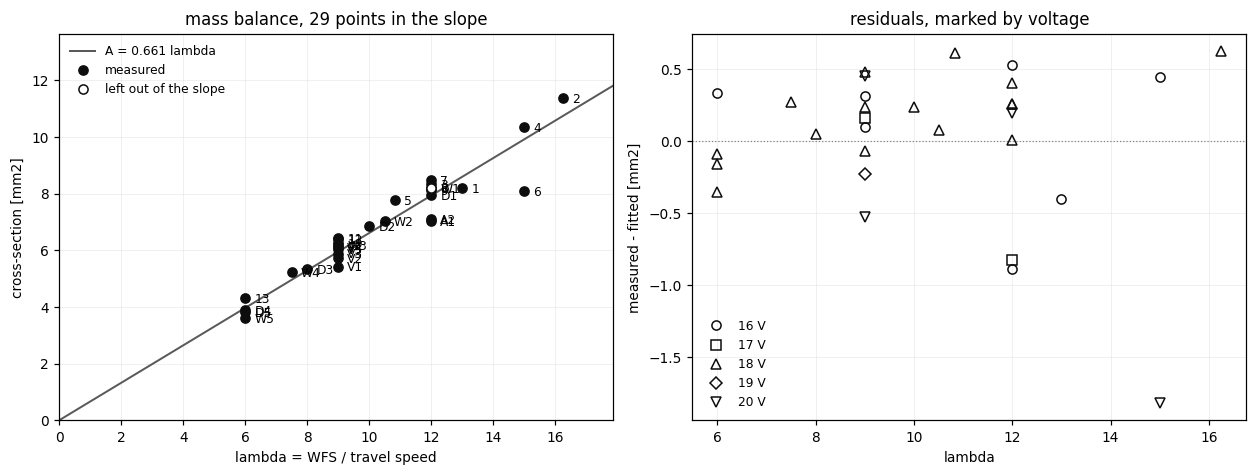

In [37]:
if records:
    fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.4))

    grid = np.linspace(0, lam.max() * 1.1, 50)
    ax[0].plot(grid, m * grid, '-', color='0.35', lw=1.3, label=f'A = {m:.3f} lambda')
    ax[0].plot(lam[used], area[used], 'o', color='0.05', ms=6, label='measured')
    if (~used).any():
        ax[0].plot(lam[~used], area[~used], 'o', color='0.05', ms=6, mfc='white',
                   label='left out of the slope')
    for r, a in zip(records, area):
        ax[0].annotate(str(r['test']), (r['lam'], a), textcoords='offset points',
                       xytext=(6, -3), fontsize=8)
    ax[0].set_xlabel('lambda = WFS / travel speed')
    ax[0].set_ylabel('cross-section [mm2]')
    ax[0].set_title(f'mass balance, {int(used.sum())} points in the slope')
    ax[0].set_xlim(0, lam.max() * 1.1)
    ax[0].set_ylim(0, area.max() * 1.2)
    ax[0].legend(fontsize=8, frameon=False)

    ax[1].axhline(0, color='0.5', lw=0.8, ls=':')
    known = sorted({r['voltage'] for r in records if np.isfinite(r['voltage'])})
    for voltage, marker in zip(known, 'os^Dvph'):
        pick = [i for i, r in enumerate(records) if r['voltage'] == voltage]
        ax[1].plot(lam[pick], residual[pick], marker, color='0.05', ms=6,
                   fillstyle='none', label=f'{voltage:.0f} V')
    pick = [i for i, r in enumerate(records) if not np.isfinite(r['voltage'])]
    if pick:
        ax[1].plot(lam[pick], residual[pick], 'x', color='0.05', ms=6,
                   label='voltage not logged')
    ax[1].set_xlabel('lambda')
    ax[1].set_ylabel('measured - fitted [mm2]')
    ax[1].set_title('residuals, marked by voltage')
    ax[1].legend(fontsize=8, frameon=False)

    for axis in ax:
        axis.grid(alpha=0.3, lw=0.4)
    fig.tight_layout()
    plt.show()

**How to read the fit.**

* Left: every welded test as a point, labelled with its test number, against the
  through-origin line the mass balance implies. Points bending below the line at
  high $\lambda$ mark where the process stops converting wire into bead, which
  sets the top of the usable range.
* Right: the same residuals against $\lambda$, with the marker showing voltage.
  Flat scatter mixed across voltages is process noise, the floor layer-to-layer
  control cannot go below. Residuals that sort by marker mean voltage moves the
  area on its own, and $\lambda$ alone does not describe the process.
* $\eta$ above 1.0 puts more metal in the bead than was fed, so an input is
  wrong. Wire diameter is the usual one, since it enters squared.

Tests 3 and 8 share one parameter set. Welded twice, they give the process spread
directly, which is what separates noise from model error in the residuals.

Open markers are rows left out of the slope, each for the reason printed with the
table. They are drawn so that it can be seen how far they sit from the line, not
because they support it.

### Crest height from area and voltage

The mass balance gives the area. The shape needs one more relation, fitted to the
same rows:

$$\ln h = a + b\,\ln A + c\,(V - 18)$$

with $h$ the crest height [mm], $A$ the cross-section [mm²] and $V$ the commanded
voltage [V]. $b$ says how the height grows with the area, and $c$ is the fraction
by which one volt lowers the crest at a fixed area.

In [38]:
def height_fit(rows):
    """ln h = a + b ln A + c (V - 18), least squares over the rows given."""
    rows = [r for r in rows if np.isfinite(r['height']) and np.isfinite(r['voltage'])]
    area = np.array([r['area'] for r in rows])
    height = np.array([r['height'] for r in rows])
    volts = np.array([r['voltage'] for r in rows])
    design = np.c_[np.ones(len(rows)), np.log(area), volts - 18]
    coef = np.linalg.lstsq(design, np.log(height), rcond=None)[0]
    error = design @ coef - np.log(height)
    return coef, float(np.sqrt(np.mean(error ** 2))), len(rows)


if records:
    kept = [r for r in records if str(r['test']) not in FIT_LEAVE_OUT]
    groups = {'all rows': kept,
              'whole beads': [r for r in kept if r['kind'] == 'bead'],
              'stretches': [r for r in kept if r['kind'] == 'stretch']}
    print(f'{"rows":>12} {"n":>3} {"a":>8} {"b":>7} {"c per V":>8} {"rms":>6} {"m":>7} '
          f'{"RMSE":>6}')
    for label, rows in groups.items():
        if len(rows) < 4:
            continue
        coef, rms, n = height_fit(rows)
        slope, _, left, _ = slope_through_origin([r['lam'] for r in rows],
                                                 [r['area'] for r in rows])
        print(f'{label:>12} {n:>3} {coef[0]:>8.4f} {coef[1]:>7.4f} {coef[2]:>8.4f} '
              f'{100 * rms:>5.1f}% {slope:>7.4f} {np.sqrt(np.mean(left ** 2)):>6.3f}')
    HEIGHT_COEF, HEIGHT_RMS, _ = height_fit(kept)
    print('rms is the scatter of the crest height about the fit; m and RMSE [mm2] are '
          'the mass balance over the same rows')
    print(f'\nh = exp({HEIGHT_COEF[0]:.4f}) * A^{HEIGHT_COEF[1]:.4f} * '
          f'exp({HEIGHT_COEF[2]:.4f} (V - 18))')

        rows   n        a       b  c per V    rms       m   RMSE
    all rows  29  -0.3820  0.5197  -0.0301   5.8%  0.6608  0.519
 whole beads  15  -0.4487  0.5520  -0.0307   6.3%  0.6611  0.688
   stretches  14  -0.3351  0.4927  -0.0318   5.1%  0.6603  0.226
rms is the scatter of the crest height about the fit; m and RMSE [mm2] are the mass balance over the same rows

h = exp(-0.3820) * A^0.5197 * exp(-0.0301 (V - 18))


### Line D: how the cross-section follows the wire feed

D asks whether the cross-section can be driven from the wire feed alone: travel
speed fixed, wire feed down by 50 IPM at each start. Four questions, each with its
own number.

**Does the area follow the schedule at all?** The slices are grouped by stretch.
$\eta^2$ is the share of the slice-to-slice variance that the grouping explains,
and Spearman's $\rho$ is the rank correlation between commanded wire feed and
slice area:

$$\eta^2 = \frac{\sum_k n_k\left(\bar A_k - \bar A\right)^2}{\sum_i \left(A_i - \bar A\right)^2}$$

where $A_i$ is the cross-section of slice $i$ [mm²], $\bar A_k$ the mean of
stretch $k$, $n_k$ its number of slices and $\bar A$ the mean of the line.
Neighbouring slices are not independent, so the $p$ value uses the effective
number $n_{\text{eff}} = n\,(1-r_1)/(1+r_1)$, with $r_1$ the correlation between
each slice and the next one along the line, about their stretch means. Both are
given twice: over every slice of the line, and over the slices inside the settled
windows. Slices this correlated leave few independent ones, so the test that
counts is the third line: the settled levels themselves, one per stretch, against
the wire feed, with every possible order of the levels tried.

**Is it the same law as the single beads?** The settled levels of the stretches
that settle, and whose wire feed is not in doubt, are fitted through the origin,
$A = m_D\,\lambda$, and $m_D$ is set against the slope $m$ of the single beads.
Two checks go with it. A settled level depends on where its window is put, so the
slope is repeated with every window starting 2 mm later. And a line with an
intercept, $A = a + b\,\lambda$, is fitted to the slices of those windows. An
intercept that cannot be told from zero is consistent with an area proportional
to the wire feed; with three stretches it does not prove it.

**Does every step do its job?** For each pair of neighbours, the drop in settled
level is set against $m\,\Delta\lambda$, the drop the wire feed step should give,
and against the scatter of the two windows. The settled level also gives the wire
feed the stretch behaved as if it had, $v_w = A\,v_t/m$.

**How does the shape change?** Width and crest height against the settled area, as
powers: $w \propto A^{p}$ and $h \propto A^{q}$. A bead that keeps its proportions
as it shrinks has $p = q = \tfrac12$; $q > p$ is a bead that gets flatter. The
section is also set against the box that contains it, $A / (w\,h)$, which is
$\tfrac23$ for the parabola of section 8.

In [39]:
def effective_n(about, s):
    """Neighbouring slices are not independent. The number that are, from the
    correlation between each slice and the next one along the line."""
    pair = np.diff(s) < 1.5 * SLICE_MM
    r1 = float(np.corrcoef(about[:-1][pair], about[1:][pair])[0, 1])
    return max(4.0, len(about) * (1 - r1) / (1 + r1)), r1


def schedule_share(s, slice_area, group, wfs):
    """How much of the slice-to-slice variance the stretch explains, and how the
    area ranks against the commanded wire feed."""
    about = slice_area - np.array([slice_area[group == k].mean() for k in group])
    spread = slice_area - slice_area.mean()
    n_eff, r1 = effective_n(about, s)
    rho = float(stats.spearmanr(wfs, slice_area)[0])
    t = rho * np.sqrt((n_eff - 2) / max(1 - rho ** 2, 1e-12))
    return dict(eta2=float(1 - about @ about / (spread @ spread)), rho=rho, r1=r1,
                n=len(slice_area), n_eff=n_eff, p=float(2 * stats.t.sf(abs(t), n_eff - 2)))


def order_by_chance(x, y):
    """Spearman's rho between two short lists, and how often a random order of y
    does as well: every order is tried."""
    rank = stats.rankdata(x)
    rho = float(np.corrcoef(rank, stats.rankdata(y))[0, 1])
    orders = [np.corrcoef(rank, order)[0, 1] for order in permutations(stats.rankdata(y))]
    return rho, float(np.mean(np.abs(orders) >= abs(rho) - 1e-12))


def staged_line(name, prof, rows, spec, m_single):
    """A line welded as separate starts, one schedule each: does its cross-section
    follow the wire feed, by the same law as the single beads, at every step?"""
    s, slice_area = prof[:, 0], prof[:, 1]
    group = np.digitize(s, [r['a'] for r in rows[1:]])
    wfs = np.array([r['wfs'] for r in rows])[group]
    settled = np.zeros(len(s), bool)
    for row in rows:
        settled |= (s >= row['lo']) & (s < row['hi'])
    print(f'{name}: {len(s)} slices in {len(rows)} stretches')
    for label, pick in (('every slice', np.ones(len(s), bool)), ('settled windows', settled)):
        share = schedule_share(s[pick], slice_area[pick], group[pick], wfs[pick])
        print(f'   {label:<16} eta2 = {share["eta2"]:.2f}   Spearman rho = '
              f'{share["rho"]:+.2f}, p = {share["p"]:.2g} with n_eff = '
              f'{share["n_eff"]:.0f} of {share["n"]} (r1 = {share["r1"]:.2f})')
    rho, chance = order_by_chance([r['wfs'] for r in rows], [r['settled'] for r in rows])
    print(f'   settled levels   Spearman rho = {rho:+.2f} over the {len(rows)} stretches; '
          f'a random order does as well {100 * chance:.1f}% of the time')

    tests = spec.get('tests') or [None] * len(rows)
    print(f'\n   {"":>2} {"WFS":>5} {"lambda":>7} {"m.lambda":>9} {"settled":>8} {"sd":>5} '
          f'{"ratio":>6} {"behaves as":>11} {"crest":>6} {"width":>6} {"crest/width":>12}')
    for row, test in zip(rows, tests):
        row['predicted'] = m_single * row['lam']
        row['behaves'] = row['settled'] / m_single * spec['travel']
        row['trusted'] = row['steady'] and str(test) not in FIT_LEAVE_OUT
        print(f'   {row["stretch"]:>2} {row["wfs"]:>5.0f} {row["lam"]:>7.2f} '
              f'{row["predicted"]:>9.2f} {row["settled"]:>8.2f} {row["sd"]:>5.2f} '
              f'{row["settled"] / row["predicted"]:>6.2f} {row["behaves"]:>7.0f} IPM '
              f'{row["crest"]:>6.2f} {row["width"]:>6.2f} '
              f'{row["crest"] / row["width"]:>12.3f}'
              + ('' if row['steady'] else '   not settled'))

    good = [r for r in rows if r['trusted']]
    if len(good) >= 2:
        lam_d = np.array([r['lam'] for r in good])
        area_d = np.array([r['settled'] for r in good])
        m_line = float(lam_d @ area_d / (lam_d @ lam_d))
        left = area_d - m_line * lam_d
        se = float(np.sqrt(left @ left / (len(good) - 1) / (lam_d @ lam_d)))
        reach = stats.t.ppf(0.975, len(good) - 1) * se
        print(f'\n   settled levels through the origin   m_{name} = {m_line:.3f}, 95% from '
              f'{m_line - reach:.2f} to {m_line + reach:.2f}, on stretches '
              f'{[r["stretch"] for r in good]}')
        print(f'   single beads                        m = {m_single:.3f}   '
              f'({100 * (m_line / m_single - 1):+.1f}%)')
        later = np.array([slice_area[(s >= min(r['lo'] + 2.0, r['hi'] - 2 * SLICE_MM))
                                     & (s < r['hi'])].mean() for r in good])
        m_later = float(lam_d @ later / (lam_d @ lam_d))
        print(f'   every window starting 2 mm later    m_{name} = {m_later:.3f}   '
              f'({100 * (m_later / m_single - 1):+.1f}%)')
        pick = np.zeros(len(s), bool)
        for row in good:
            pick |= (s >= row['lo']) & (s < row['hi'])
        line = stats.linregress(wfs[pick] / spec['travel'], slice_area[pick])
        about = slice_area[pick] - np.array([slice_area[pick][group[pick] == k].mean()
                                             for k in group[pick]])
        widen = np.sqrt(pick.sum() / effective_n(about, s[pick])[0])
        print(f'   with an intercept                   A = {line.intercept:+.2f} + '
              f'{line.slope:.3f} lambda, intercept +/- {line.intercept_stderr * widen:.2f}: '
              + ('not told from zero' if abs(line.intercept) < 2 * line.intercept_stderr * widen
                 else 'not zero, so the area is not simply proportional here'))

    steady = [r for r in rows if r['steady']]
    if len(steady) >= 3:
        log_area = np.log([r['settled'] for r in steady])
        p_width = np.polyfit(log_area, np.log([r['width'] for r in steady]), 1)[0]
        p_crest = np.polyfit(log_area, np.log([r['crest'] for r in steady]), 1)[0]
        fill = np.mean([r['settled'] / (r['crest'] * r['width']) for r in steady])
        print(f'   shape, stretches {[r["stretch"] for r in steady]}             '
              f'width ~ A^{p_width:.2f}, crest ~ A^{p_crest:.2f}; the section fills '
              f'{fill:.2f} of width x crest (a parabola fills 0.67)')

    print(f'\n   {"step":>6} {"WFS":>11} {"should drop":>12} {"dropped":>8} {"scatter":>8}')
    for upper, lower in zip(rows[:-1], rows[1:]):
        drop = upper['settled'] - lower['settled']
        noise = float(np.hypot(upper['sd'], lower['sd']))
        verdict = ('' if drop > 2 * noise else
                   '   no drop beyond the scatter' if abs(drop) <= 2 * noise else '   rose')
        print(f'   {upper["stretch"]}->{lower["stretch"]:<3} '
              f'{upper["wfs"]:>5.0f}->{lower["wfs"]:<4.0f} '
              f'{m_single * (upper["lam"] - lower["lam"]):>12.2f} {drop:>8.2f} '
              f'{noise:>8.2f}' + verdict)


staged = {name: result for name, result in long_results.items()
          if LONG_BEADS[name]['own_starts'] and len(result[2]) > 1}
if staged and records:
    single = used & np.array([r['kind'] == 'bead' for r in records])
    m_single = slope_through_origin(lam[single], area[single])[0]
    print(f'slope of the {int(single.sum())} single beads alone: m = {m_single:.3f} '
          f'mm2 per unit lambda\n')
    for name, (bead, prof, rows) in staged.items():
        staged_line(name, prof, rows, LONG_BEADS[name], m_single)
    print('\nareas in mm2, crest and width in mm')
else:
    print('No line welded as separate starts in this scan.')

No line welded as separate starts in this scan.


In [40]:
if staged and records:
    for name, (bead, prof, rows) in staged.items():
        fig, ax = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={'width_ratios': [1.7, 1]})
        for row in rows:
            ax[0].axvspan(row['lo'], row['hi'], color='0.9', lw=0)
            ax[0].plot([row['a'], row['b']], [row['predicted']] * 2, '-', color='tab:red',
                       lw=1.4, label='m lambda' if row is rows[0] else None)
            ax[0].annotate(f'{row["wfs"]:.0f}', (0.5 * (row['a'] + row['b']), 0.25),
                           ha='center', fontsize=8, color='tab:blue')
        ax[0].plot(prof[:, 0], prof[:, 1], '-', color='0.1', lw=1.2, label='cross-section')
        ax[0].set_xlabel('distance from the welded start [mm]')
        ax[0].set_ylabel('cross-section [mm2]')
        ax[0].set_xlim(0, rows[-1]['b'])
        ax[0].set_ylim(0, None)
        ax[0].set_title(f'{name}: commanded WFS in blue [IPM], settled windows in grey',
                        loc='left')
        ax[0].legend(fontsize=8, frameon=False, loc='upper right')
        ax[0].grid(alpha=0.3, lw=0.4)

        reach = np.linspace(0, 1.1 * max(r['lam'] for r in rows), 20)
        ax[1].plot(reach, m_single * reach, '-', color='0.35', lw=1.3,
                   label=f'single beads, A = {m_single:.3f} lambda')
        ax[1].plot(lam[single], area[single], '.', color='0.6', ms=7, label='single beads')
        for row in rows:
            ax[1].errorbar(row['lam'], row['settled'], yerr=row['sd'], fmt='o', ms=7,
                           color='0.05', mfc='0.05' if row['trusted'] else 'white',
                           capsize=3, lw=1.0)
            ax[1].annotate(str(row['stretch']), (row['lam'], row['settled']),
                           textcoords='offset points', xytext=(7, -10), fontsize=8)
        ax[1].set_xlabel('lambda = WFS / travel speed')
        ax[1].set_ylabel('settled cross-section [mm2]')
        ax[1].set_xlim(0, None)
        ax[1].set_ylim(0, None)
        ax[1].set_title('stretches against the single-bead line', loc='left')
        ax[1].legend(fontsize=8, frameon=False, loc='upper left')
        ax[1].grid(alpha=0.3, lw=0.4)
        fig.tight_layout()
        plt.show()

**How to read it.** Left, the profile again with the settled windows in grey and,
in red, the level $m\lambda$ the single beads predict for each stretch. Right, the
settled level of each stretch against $\lambda$: filled where the stretch settled
and its wire feed is not in doubt, open otherwise. Grey dots are the single beads
and the line is their fit through the origin.

* Filled points on the line mean the staged line obeys the same mass balance as
  the single beads, so a cross-section can be set by choosing $\lambda$.
* A stretch above the line at the low end did not get as little wire as it was
  asked for. *Behaves as* gives the wire feed it corresponds to. Metal is not made
  on the plate: a stretch that holds more than its schedule feeds was welded with
  more wire, or slower, than the schedule says.
* A stretch that has not settled is shorter than its own start transient at that
  wire feed. Its level is not a measurement of the schedule.
* $\eta^2$ low over every slice and high over the settled windows means that most
  of what varies along D is the starts, not the schedules. The next subsection
  takes the starts out.

### What a start adds

Every stretch of D opens with a hump, and so does A. A weld is described here by
two things: the level it holds while the torch travels, and what its start leaves
beyond that level.

$$A(s) = \frac{L}{2}\left[\operatorname{erf}\frac{s - s_0}{\sqrt2\,\sigma_e}
       - \operatorname{erf}\frac{s - s_1}{\sqrt2\,\sigma_e}\right]
       + \frac{S}{\sqrt{2\pi}\,\sigma_h}\,
         \exp\!\left(-\frac{(s - s_0)^2}{2\sigma_h^2}\right)$$

where $s_0$ and $s_1$ are where the weld starts and stops [mm], $L$ the level
[mm²], $\sigma_e$ the rounding of the two ends [mm], $S$ the surplus of the start
[mm³] and $\sigma_h$ the width of its hump [mm]. The first term integrates to
$L\,(s_1 - s_0)$, the metal of steady travel, and the second to $S$. The top of
the hump sits a mm or so after $s_0$, because the level is still rising there.

A line of several welds is the sum of one such term per weld, each starting where
the last one ended: $s_0 = s_{\text{first}} + k\,p$, with $p$ the pitch. The fit
finds where the first weld started, the pitch, the two widths and one surplus per
start. A stretch that settled keeps its settled level; the level of one that did
not is fitted with the rest. The uncertainty of the pitch is widened for the
correlation between neighbouring slices.

This gives three things the settled levels do not. The mean step the robot made,
measured on the metal. What a start costs in metal, which is what a short bead
carries in its mean and what a correction pass has to count. And a profile to
predict with, used on the cut line below. Two kinds of start are kept apart: the
first start of a line, on bare plate, and a start on a line that is being welded,
which lands on the end of the weld before it.

In [41]:
# used when a scan has no line with its own starts; measured on cloud0.ply
START_DEFAULT = dict(first=37.0, interior=26.0, hump_mm=3.0, end_mm=2.5)


def weld_metal(s, start, end, level, surplus, hump_mm, end_mm):
    """Cross-section one weld leaves along its line: a level from its start to its
    end, rounded at both, and what its start leaves beyond that as a hump there."""
    span = 0.5 * (special.erf((s - start) / (np.sqrt(2) * end_mm))
                  - special.erf((s - end) / (np.sqrt(2) * end_mm)))
    hump = np.exp(-0.5 * ((s - start) / hump_mm) ** 2) / (hump_mm * np.sqrt(2 * np.pi))
    return level * span + surplus * hump


def fit_welds(prof, rows):
    """Welds end to end at one pitch, fitted to the profile of their line. A stretch
    that settled keeps its settled level; the level of the others is left free."""
    s, slice_area = prof[:, 0], prof[:, 1]
    n = len(rows)
    free = [k for k, row in enumerate(rows) if not row['steady']]
    length = (rows[-1]['b'] - rows[0]['a']) / n

    def unpack(p):
        levels = [row['settled'] for row in rows]
        for k, value in zip(free, p[4 + n:]):
            levels[k] = value
        return p[0], p[1], p[2], p[3], p[4:4 + n], levels

    def model(p, level_only=False):
        first, pitch, hump_mm, end_mm, surplus, levels = unpack(p)
        return sum(weld_metal(s, first + k * pitch, first + (k + 1) * pitch, levels[k],
                              0.0 if level_only else surplus[k], hump_mm, end_mm)
                   for k in range(n))

    guess = [3.0, length, 2.5, 2.0] + [25.0] * n + [rows[k]['settled'] for k in free]
    lower = [0.0, 0.8 * length, 1.0, 0.5] + [0.0] * n + [0.3 * rows[k]['settled'] for k in free]
    upper = [8.0, 1.2 * length, 6.0, 4.0] + [200.0] * n + [1.5 * rows[k]['settled'] for k in free]
    fit = optimize.least_squares(lambda p: model(p) - slice_area, guess, bounds=(lower, upper))
    left = fit.fun
    r1 = float(np.corrcoef(left[:-1], left[1:])[0, 1])
    covariance = (np.linalg.pinv(fit.jac.T @ fit.jac) * (left @ left)
                  / max(len(s) - len(fit.x), 1) * (1 + r1) / max(1 - r1, 0.05))
    first, pitch, hump_mm, end_mm, surplus, levels = unpack(fit.x)
    return dict(first=float(first), pitch=float(pitch),
                pitch_se=float(np.sqrt(covariance[1, 1])), hump_mm=float(hump_mm),
                end_mm=float(end_mm), surplus=np.array(surplus), levels=levels,
                model=model(fit.x), level=model(fit.x, level_only=True),
                rms=float(np.sqrt(np.mean(left ** 2))))


def line_offsets(bead, rows, start):
    """Sideways offset of each stretch from one straight line through the whole
    centreline, in mm."""
    path = bead['path']
    centre = path.mean(axis=0)
    direction = np.linalg.eigh(np.cov((path - centre).T))[1][:, 1]
    across = (path - centre) @ np.array([-direction[1], direction[0]])
    s = np.r_[0.0, np.cumsum(np.linalg.norm(np.diff(path, axis=0), axis=1))]
    axis = 0 if start.endswith('x') else 1
    if (path[0, axis] > path[-1, axis]) == start.startswith('-'):
        s = s[-1] - s
    return [float(across[(s >= r['a']) & (s < r['b'])].mean()) for r in rows]


start_fits, first_starts, interior_starts = {}, [], []
for name, (bead, prof, rows) in long_results.items():
    if not LONG_BEADS[name]['own_starts']:
        continue
    fit = fit_welds(prof, rows)
    start_fits[name] = fit
    offsets = line_offsets(bead, rows, LONG_BEADS[name]['start'])
    several = len(rows) > 1
    print(f'{name}: {len(rows)} weld' + ('s end to end, ' if several else ', ')
          + f'first start {fit["first"]:.1f} mm into the mask, '
          + (f'pitch {fit["pitch"]:.2f} +/- {fit["pitch_se"]:.2f} mm' if several
             else f'{fit["pitch"]:.1f} mm of travel'))
    print(f'   hump {2.355 * fit["hump_mm"]:.1f} mm wide at half height, ends rounded '
          f'over {fit["end_mm"]:.1f} mm, model within {fit["rms"]:.2f} mm2 rms of the '
          'profile')
    print(f'   {"start":>5} {"at":>6} {"hump top":>9} {"level":>6} {"surplus":>8} '
          + (f'{"sideways":>9}' if several else ''))
    for k, row in enumerate(rows):
        print(f'   {k + 1:>5} {fit["first"] + k * fit["pitch"]:>6.1f} {row["peak_at"]:>9.1f} '
              f'{fit["levels"][k]:>6.2f} {fit["surplus"][k]:>8.1f} '
              + (f'{offsets[k]:>+9.2f}' if several else '')
              + ('' if row['steady'] else '   level fitted, the stretch does not settle'))
        if row['steady']:
            (interior_starts if k else first_starts).append(float(fit['surplus'][k]))
    if several:
        tops = np.diff([row['peak_at'] for row in rows])
        print('   hump tops ' + ', '.join(f'{d:.0f}' for d in tops) + ' mm apart: the pitch '
              f'is their mean step. The stretches sit within {np.ptp(offsets):.2f} mm of '
              'one straight line')
    else:
        whole = bead['area_mean']
        print(f'   whole-bead mean {whole:.2f} mm2 against {rows[0]["settled"]:.2f} settled: '
              f'the start makes a bead {bead["length"]:.0f} mm long read '
              f'{100 * (whole / rows[0]["settled"] - 1):+.0f}%')

if first_starts or interior_starts:
    every = first_starts + interior_starts
    START = dict(first=float(np.mean(first_starts or every)),
                 interior=float(np.mean(interior_starts or every)),
                 hump_mm=float(np.median([f['hump_mm'] for f in start_fits.values()])),
                 end_mm=float(np.median([f['end_mm'] for f in start_fits.values()])))
    wire = np.pi * WIRE_DIA_MM ** 2 / 4
    if first_starts:
        print(f'\nthe first start of a line, on bare plate, leaves {START["first"]:.0f} mm3 '
              f'beyond the level of its stretch ({len(first_starts)} whose stretch settled), '
              f'the metal of {START["first"] / wire:.0f} mm of wire')
    if interior_starts:
        spread = np.std(interior_starts, ddof=1) if len(interior_starts) > 1 else 0.0
        print(f'a start on a line that is being welded leaves {START["interior"]:.0f} mm3 '
              f'(sd {spread:.0f}, {len(interior_starts)} starts), '
              f'{START["interior"] / wire:.0f} mm of wire')
else:
    START = dict(START_DEFAULT)
    print('No line with its own starts in this scan: a first start is taken as '
          f'{START["first"]:.0f} mm3, measured on cloud0.ply.')
print('positions in mm from the start of the mask, level in mm2, surplus in mm3')

No line with its own starts in this scan: a first start is taken as 37 mm3, measured on cloud0.ply.
positions in mm from the start of the mask, level in mm2, surplus in mm3


In [42]:
if start_fits:
    widths = [long_results[name][1][-1, 0] for name in start_fits]
    fig, axes = plt.subplots(1, len(start_fits), figsize=(13, 3.9), squeeze=False,
                             gridspec_kw={'width_ratios': [max(w, 30) for w in widths]})
    for ax, (name, fit) in zip(axes[0], start_fits.items()):
        bead, prof, rows = long_results[name]
        ax.fill_between(prof[:, 0], fit['level'], fit['model'], color='tab:red', alpha=0.25,
                        lw=0, label='start')
        ax.plot(prof[:, 0], fit['level'], '--', color='0.45', lw=1.1, label='level')
        ax.plot(prof[:, 0], fit['model'], '-', color='tab:red', lw=1.3, label='level + start')
        ax.plot(prof[:, 0], prof[:, 1], '-', color='0.1', lw=1.2, label='measured')
        for k in range(len(rows)):
            ax.axvline(fit['first'] + k * fit['pitch'], color='0.6', lw=0.8, ls=':')
        ax.set_xlabel('distance from the welded start [mm]')
        ax.set_xlim(0, prof[-1, 0] + 0.5)
        ax.set_ylim(0, None)
        ax.set_title(f'{name}: within {fit["rms"]:.2f} mm2 rms', loc='left')
        ax.grid(alpha=0.3, lw=0.4)
    axes[0][0].set_ylabel('cross-section [mm2]')
    axes[0][0].legend(fontsize=8, frameon=False, loc='upper right')
    fig.tight_layout()
    plt.show()

**How to read it.** Black is the measured profile, red the model, the dashed line
the levels alone. The shaded area between them is the starts. Dotted lines mark
where each weld began.

* *Surplus* near one value on starts welded at different wire feeds means a start
  adds an amount of metal, not a share of the bead. It weighs more the shorter
  the bead. On A it lifts the whole-bead mean above the settled level, and the
  whole-bead mean is what the fit of this section uses for single beads: compare
  beads of one length, or compare settled levels.
* A first start leaves more than a start inside a line. The first start of D is
  the largest and its stretch does not settle; it is also the only one at
  300 IPM, so the scan cannot say which of the two makes it large. It is left
  out of both averages.
* *Pitch* is one number for all the starts of a line: their mean step. The hump
  tops, printed with it, show how even the steps are. Against the step in the
  robot program the pitch checks the scale of the scan and the robot together.
* *Sideways* is how far each stretch sits from one straight line through D.
  A few tenths of a mm would not show in a wall built this way; a millimetre
  would show as a step.

### A cut line and the pass that would close it

C stopped twice on its way: three pieces with bare plate between them. Section 7
joins the pieces into one bead because they share an axis, and the slices show
where the metal ends and starts again.

Section 10 corrects a whole layer with one number. A gap needs the other kind of
correction, one that depends on position: a pass over the part of the line that is
short of metal. The cross-section after a pass from $s_a$ to $s_b$ at wire feed
$v_w$ is predicted by laying the weld of the previous subsection on what is
already there,

$$A_{\text{after}}(s) = A(s) + m\,\frac{v_w}{v_t}\,E(s;\,s_a, s_b) + S\,G(s - s_a)$$

where $A(s)$ is the measured cross-section [mm²], $m$ the slope of the mass
balance, $v_t$ the travel speed, $E$ the span of the pass with its rounded ends,
$G$ the shape of the hump of a start and $S$ the surplus of a first start, since a
pass is a weld of its own. A pass is judged by the metal it leaves out of place
against the target $A^{*}$,

$$J = \int \left|A^{*} - A_{\text{after}}(s)\right| ds$$

which is the metal still short of the target plus the metal laid above it [mm³],
counted from `PASS_REACH_MM` before the first gap to `PASS_REACH_MM` after the
last.

Two plans are compared. *One pass per gap*: for each gap, the start, the end and
the wire feed that leave the least out of place, with both ends within
`PASS_REACH_MM` of the bare plate. The pass also has to stay over metal lower than
the wire tip, with `PASS_PLACING_MM` to spare at each end, so that it runs at one
height even if it lands that far off. *One pass of `PASS_MM`*, the length that was
asked for: the same search with the length fixed. The wire feed stays inside
`PASS_WFS_RANGE`, where the stretches of D settled and the starts were measured.
Passes run the way the line was welded, so the hump of each start is at its low
end.

**In robot coordinates.** Distances are given from where the wire of the line
started. That point is found the way the start of a pass is defined: it is the
start $s_0$ of the weld model fitted to the first 10 mm of the line. With the
taught start of the line $\mathbf{p}_0$ and its taught end $\mathbf{p}_1$ in
`LINE_ROBOT`, a distance $d$ becomes

$$\mathbf{p}(d) = \mathbf{p}_0 + d\,\hat{\mathbf{u}},\qquad
\hat{\mathbf{u}} = \frac{\mathbf{p}_1 - \mathbf{p}_0}{\lVert\mathbf{p}_1 - \mathbf{p}_0\rVert}$$

The offset that moves the torch along the line, of any length, can stand in for
$\mathbf{p}_1 - \mathbf{p}_0$; Z is then only as good as that offset follows the
plate. Keeping 0.035 in between tip and plate needs two more numbers. The plate is
not flat along the line: its height against the straight line between the two
ends of C is printed at both ends of each pass, and goes into Z. It holds if the
plate sits on the table as it did under the scanner. And where a pass runs over
metal that is already there, the surface under the wire is the crest of that
metal, printed as *metal under the wire*.

In [43]:
PASS_MM = 30.0                  # length of the correction pass that was asked for
PASS_TARGET_MM2 = 7.8           # cross-section the line should have: 300 IPM at
                                # 25 IPM, 0.65 x 12
PASS_TRAVEL_IPM = 25.0
PASS_WFS_RANGE = (150.0, 250.0) # wire feeds whose stretch settled on D
PASS_REACH_MM = 8.0             # a pass for one gap starts and ends within this of it
PASS_PLACING_MM = 1.5           # how well a pass can be placed along the line
GAP_MM2 = 0.5                   # a slice under this cross-section is bare plate
TIP_GAP_MM = 0.035 * 25.4       # wire tip above the plate
LINE_ROBOT = {'C': None}        # dict(start=(X, Y, Z), end=(X, Y, Z)): the taught
                                # start and end of the line, mm in the robot frame.
                                # direction=(dX, dY, dZ) can stand in for the end


def pieces_and_gaps(prof, floor, shortest=3.0):
    """Stretches of a line with metal on them, and the bare plate between."""
    labels, count = ndimage.label(prof[:, 1] > floor)
    pieces = [(float(prof[labels == k, 0].min() - 0.5 * SLICE_MM),
               float(prof[labels == k, 0].max() + 0.5 * SLICE_MM))
              for k in range(1, count + 1)]
    pieces = [p for p in pieces if p[1] - p[0] >= shortest]
    return pieces, [(a[1], b[0]) for a, b in zip(pieces[:-1], pieces[1:])]


def wire_start(prof, start):
    """Where the first weld of a line started: the start of the weld model fitted
    to its first 10 mm, so that it means for the line what it means for a pass."""
    head = prof[prof[:, 0] < 10.0]
    fit = optimize.least_squares(
        lambda p: weld_metal(head[:, 0], p[0], 1e3, p[1], p[2], start['hump_mm'],
                             start['end_mm']) - head[:, 1],
        [3.0, head[-1, 1], start['first']], bounds=([0.0, 0.5, 0.0], [8.0, 30.0, 400.0]))
    return float(fit.x[0])


def lay(s, passes, m, start, surplus):
    """Cross-section that passes (start, end, wire feed) add along a line."""
    return sum((weld_metal(s, a, b, m * wfs / PASS_TRAVEL_IPM, surplus, start['hump_mm'],
                           start['end_mm']) for a, b, wfs in passes), np.zeros(len(s)))


def out_of_place(line_area, target):
    """Metal short of the target and metal above it along a line, in mm3."""
    return (float(np.clip(target - line_area, 0, None).sum() * SLICE_MM),
            float(np.clip(line_area - target, 0, None).sum() * SLICE_MM))


def best_pass(s, line_area, target, judged, windows, feeds, m, start):
    """Among the windows and wire feeds allowed, the pass that leaves the least
    metal out of place: short of the target plus above it."""
    best, least = None, np.inf
    for a, b in windows:
        span = weld_metal(s, a, b, 1.0, 0.0, start['hump_mm'], start['end_mm'])[judged]
        hump = weld_metal(s, a, b, 0.0, start['first'], start['hump_mm'],
                          start['end_mm'])[judged]
        for wfs in feeds:
            wrong = sum(out_of_place(line_area[judged] + m * wfs / PASS_TRAVEL_IPM * span
                                     + hump, target))
            if wrong < least:
                best, least = (float(a), float(b), float(wfs)), wrong
    return best


def highest_under(s, crest, a, b):
    """Highest metal already on the line under a pass from a to b, in mm."""
    inside = (s > a) & (s < b)
    return float(max(np.interp(a, s, crest), np.interp(b, s, crest),
                     crest[inside].max(initial=0.0)))


def under_the_line(bead, start):
    """Along a centreline, from its welded start: the height of the plate against
    the straight line between its two ends, and how far the centreline itself
    strays sideways from that line."""
    path = bead['path']
    axis = 0 if start.endswith('x') else 1
    if (path[0, axis] > path[-1, axis]) == start.startswith('-'):
        path = path[::-1]
    column = np.clip(((path[:, 0] - grid_origin[0]) / CELL_MM).astype(int), 0, n_cols - 1)
    row = np.clip(((path[:, 1] - grid_origin[1]) / CELL_MM).astype(int), 0, n_rows - 1)
    z = datum_surface[row, column]
    s = np.r_[0.0, np.cumsum(np.linalg.norm(np.diff(path, axis=0), axis=1))]
    chord = (path[-1] - path[0]) / np.linalg.norm(path[-1] - path[0])
    sideways = (path - path[0]) @ np.array([-chord[1], chord[0]])
    return s, z - (z[0] + (z[-1] - z[0]) * s / s[-1]), sideways


def plan_cut_line(name, bead, spec):
    """The gaps of a line and the passes that would close them."""
    prof = along_profile(bead, SLICE_MM, CELL_MM, spec['start'])
    s, line_area, crest = prof[:, 0], prof[:, 1], prof[:, 2]
    pieces, gaps = pieces_and_gaps(prof, GAP_MM2)
    origin = wire_start(prof, START)
    print(f'{name} (bead {bead["id"]}): {len(pieces)} pieces, {len(gaps)} gaps, '
          f'{line_area.sum() * SLICE_MM:.0f} mm3 of metal over {s[-1] + 0.5 * SLICE_MM:.0f} mm; '
          f'the wire started {origin:.1f} mm into the mask')
    print(f'   {"piece":>5} {"from-to mm":>11} {"length":>7} {"metal":>6} {"peak":>6} '
          f'{"ends at":>8}')
    for k, (a, b) in enumerate(pieces, start=1):
        inside = (s >= a) & (s < b)
        print(f'   {k:>5} {a:>5.0f}-{b:<5.0f} {b - a:>7.1f} '
              f'{line_area[inside].sum() * SLICE_MM:>6.0f} {line_area[inside].max():>6.2f} '
              f'{line_area[inside][-6:].mean():>8.2f}')
    print('   length in mm, metal in mm3, peak and the mean of the last 6 mm in mm2')
    if not gaps:
        return prof, pieces, gaps, {}, origin

    feeds = np.arange(PASS_WFS_RANGE[0], PASS_WFS_RANGE[1] + 1, 5.0)
    judged = (s >= gaps[0][0] - PASS_REACH_MM) & (s < gaps[-1][1] + PASS_REACH_MM)
    short, above = out_of_place(line_area[judged], PASS_TARGET_MM2)
    print(f'\n   target {PASS_TARGET_MM2} mm2, {PASS_TRAVEL_IPM:.0f} IPM travel, wire feed '
          f'{PASS_WFS_RANGE[0]:.0f} to {PASS_WFS_RANGE[1]:.0f} IPM, m = {m:.3f}; a start '
          f'adds {START["first"]:.0f} mm3 over {2.355 * START["hump_mm"]:.1f} mm')
    print(f'   as scanned, between {s[judged][0] - 0.5 * SLICE_MM:.0f} and '
          f'{s[judged][-1] + 0.5 * SLICE_MM:.0f} mm: {short:.0f} mm3 short of the target, '
          f'{above:.0f} mm3 above it')

    plans, passes, after = {}, [], line_area.copy()
    for gap in gaps:
        windows = [(a, b)
                   for a in np.arange(gap[0] - PASS_REACH_MM, gap[0] + 2.01, 0.5)
                   for b in np.arange(gap[1] - 2.0, gap[1] + PASS_REACH_MM + 0.01, 0.5)]
        clear = [(a, b) for a, b in windows
                 if highest_under(s, crest, a - PASS_PLACING_MM, b + PASS_PLACING_MM)
                 < TIP_GAP_MM]
        if not clear:
            print(f'   no pass over the gap at {gap[0]:.0f} mm clears the metal beside it '
                  f'by {PASS_PLACING_MM} mm: the one below needs Z to follow the crest')
        passes.append(best_pass(s, after, PASS_TARGET_MM2, judged, clear or windows, feeds,
                                m, START))
        after = after + lay(s, passes[-1:], m, START, START['first'])
    plans['one pass per gap'] = passes
    first = max(gaps[0][0] - PASS_MM, 0.0)
    last = min(gaps[-1][1], s[-1] + 0.5 * SLICE_MM - PASS_MM)
    windows = [(a, a + PASS_MM) for a in np.arange(first, last + 0.01, 0.5)]
    if windows:
        plans[f'one {PASS_MM:.0f} mm pass'] = [best_pass(s, line_area, PASS_TARGET_MM2, judged,
                                                         windows, feeds, m, START)]

    s_plate, sag, sideways = under_the_line(bead, spec['start'])
    taught = LINE_ROBOT.get(name)
    profiles = {}
    for label, passes in plans.items():
        after = line_area + lay(s, passes, m, START, START['first'])
        profiles[label] = after
        short, above = out_of_place(after[judged], PASS_TARGET_MM2)
        print(f'\n   {label}: leaves {short:.0f} mm3 short and {above:.0f} mm3 above')
        for surplus, what in ((START['interior'], 'as small as inside a line'),
                              (1.5 * START['first'], 'half as large again')):
            other = line_area + lay(s, passes, m, START, surplus)
            short, above = out_of_place(other[judged], PASS_TARGET_MM2)
            print(f'      with a start {what}, {surplus:.0f} mm3: {short:.0f} short, '
                  f'{above:.0f} above')
        print('      between the pieces  '
              + ',  '.join(f'gap {k}: {after[(s > a - 1) & (s < b + 1)].min():.1f} to '
                           f'{after[(s > a - 1) & (s < b + 1)].max():.1f} mm2'
                           for k, (a, b) in enumerate(gaps, start=1)))
        print(f'      {"from-to mm":>11} {"length":>7} {"WFS":>5} {"from the wire start":>21} '
              f'{"plate":>13}   metal under the wire')
        for a, b, wfs in passes:
            dz = np.interp([a, b], s_plate, sag)
            top = highest_under(s, crest, a - PASS_PLACING_MM, b + PASS_PLACING_MM)
            over = s[(s > a) & (s < b) & (crest >= TIP_GAP_MM)]
            print(f'      {a:>5.1f}-{b:<5.1f} {b - a:>7.1f} {wfs:>5.0f} '
                  f'{a - origin:>9.1f} to {b - origin:<8.1f} {dz[0]:>+6.2f} {dz[1]:>+6.2f}   '
                  f'{top:.2f} at most'
                  + (f', above the wire tip from {over.min() - origin:.0f} to '
                     f'{over.max() - origin:.0f} mm' if len(over) else ''))
            if taught:
                p0 = np.array(taught['start'], float)
                u = (np.array(taught['end'], float) - p0 if 'end' in taught
                     else np.array(taught['direction'], float))
                u = u / np.linalg.norm(u)
                for point, distance, lift in zip(('start', 'end'), (a - origin, b - origin), dz):
                    p = p0 + distance * u + np.array([0.0, 0.0, lift])
                    print(f'         robot {point:<5} X {p[0]:9.3f}  Y {p[1]:9.3f}  Z {p[2]:8.3f}')
    print(f'\n   distances in mm, from-to along the mask. plate: its height at the start and '
          f'at the end of the pass against the straight line between the ends of {name}; '
          f'along the whole line it runs from {sag.min():+.2f} to {sag.max():+.2f} mm. metal '
          f'under the wire: the highest crest already there within {PASS_PLACING_MM} mm of '
          f'the pass, against the {TIP_GAP_MM:.2f} mm between tip and plate')
    print(f'   the pieces sit within {np.ptp(sideways):.2f} mm of one straight line')
    if not taught:
        print(f'   LINE_ROBOT[{name!r}] is empty. With the taught start p0 of the line and a '
              'unit vector u along it, a distance d from the wire start is p0 + d u, and '
              'the plate height is added to Z.')
    saved = RESULTS_CSV.parent / f'pass_plan_{PLATE_ID}_{name}.csv'
    with open(saved, 'w', newline='') as handle:
        writer = csv.writer(handle)
        writer.writerow(['s_mm', 'scanned_mm2'] + [f'after {label}' for label in profiles])
        writer.writerows([f'{s[k]:.1f}', f'{line_area[k]:.3f}']
                         + [f'{after[k]:.3f}' for after in profiles.values()]
                         for k in range(len(s)))
    print(f'   wrote {saved}: the profile as scanned and after each plan')
    return prof, pieces, gaps, {k: (plans[k], profiles[k]) for k in plans}, origin


cut_results = {}
for name, spec in CUT_BEADS.items():
    if name in by_name and records:
        cut_results[name] = plan_cut_line(name, by_name[name], spec)
    else:
        print(f'{name}: not among the measured beads')

In [44]:
for name, (prof, pieces, gaps, plans, origin) in cut_results.items():
    if not plans:
        continue
    fig, ax = plt.subplots(figsize=(11, 4.4))
    for gap in gaps:
        ax.axvspan(gap[0], gap[1], color='0.9', lw=0)
    ax.plot(prof[:, 0], prof[:, 1], '-', color='0.1', lw=1.4, label='as scanned')
    for level, (colour, (label, (passes, after))) in enumerate(
            zip(('tab:red', '0.55'), plans.items())):
        ax.plot(prof[:, 0], after, '-', color=colour, lw=1.4, label=f'after {label}')
        for a, b, wfs in passes:
            ax.plot([a, b], [0.35 + 0.55 * level] * 2, '-', color=colour, lw=4,
                    solid_capstyle='butt')
            ax.annotate(f'{wfs:.0f}', (0.5 * (a + b), 0.35 + 0.55 * level), ha='center',
                        va='center', fontsize=7, color='w')
    ax.axhline(PASS_TARGET_MM2, color='0.3', lw=0.9, ls='--', label='target')
    ax.set_xlim(max(gaps[0][0] - 0.8 * PASS_MM, 0),
                min(gaps[-1][1] + 0.8 * PASS_MM, prof[-1, 0] + 0.5))
    ax.set_ylim(0, None)
    ax.set_xlabel('distance along the line, from the start of its mask [mm]')
    ax.set_ylabel('cross-section [mm2]')
    ax.set_title(f'{name}: predicted cross-section after each plan; bare plate shaded, '
                 'passes as bars with their WFS [IPM]', loc='left')
    ax.legend(fontsize=8, frameon=False, loc='upper right')
    ax.grid(alpha=0.3, lw=0.4)
    fig.tight_layout()
    plt.show()

**How to read it.** Black is C as scanned, the dashed line the target, the shaded
bands the bare plate. Red is the line after one pass per gap, grey after the single
pass of `PASS_MM`. The bars at the bottom are the passes, with their wire feed.

* One schedule lays the same amount everywhere in its window. Where the window
  covers a piece that already has its metal, that amount goes on top of it, and
  the wire has to climb over the piece to get there.
* A pass per gap starts on the thin tail of the piece before the gap, where the
  hump of the start fills what the tail lacks, and stops before the next piece
  rises above the wire tip. What it cannot reach is the dip left where it stops.
* If the bare plate ends below the target, the pass is at the top of
  `PASS_WFS_RANGE`: the highest wire feed that settled on D lays less than the
  target asks for. A slower pass would close the difference. A higher wire feed is
  outside what this scan measured.

**How far to trust it.** The passes are shorter than any weld the model was fitted
on, and a large part of what a short pass lays is its start. The start is the
least known number here: the two lines printed under each plan show what the same
passes leave if it is as small as inside D, or half as large again. The rounding
of the ends is a fitted width and not a measured bead end, so the junctions with
the pieces are good to about 1 mm². Where the line starts is known to about a mm,
which is what `PASS_PLACING_MM` allows for.

The prediction is the test. Scanning the plate after the pass and running this
notebook again gives the profile to set against the red line. The difference
between the two scans is what the pass added, by itself: where it starts and ends
against where it was sent is the error of the registration, and its metal against
$m\,(v_w/v_t)(s_b - s_a) + S$ is the mass balance of one pass. The profile as
scanned and both predictions are saved in `results/`, because `output/` is
rewritten by every scan.

### Process map: travel speed against arc power

The mass balance says how much metal a bead holds. It says nothing about how that
metal spreads, and that is set by heat. Arc power comes from the feedback the
source logged, not from the setpoint -- current is never commanded, so the
feedback is the only record of it:

$$P = V_{\text{arc}} \, I_{\text{arc}}, \qquad
Q = \frac{P}{v_t}$$

$Q$ is the heat put into each millimetre of travel. Two beads at the same
$\lambda$ carry the same metal; the one with more $Q$ keeps a larger, hotter pool
behind the arc, which has longer to spread before it freezes.

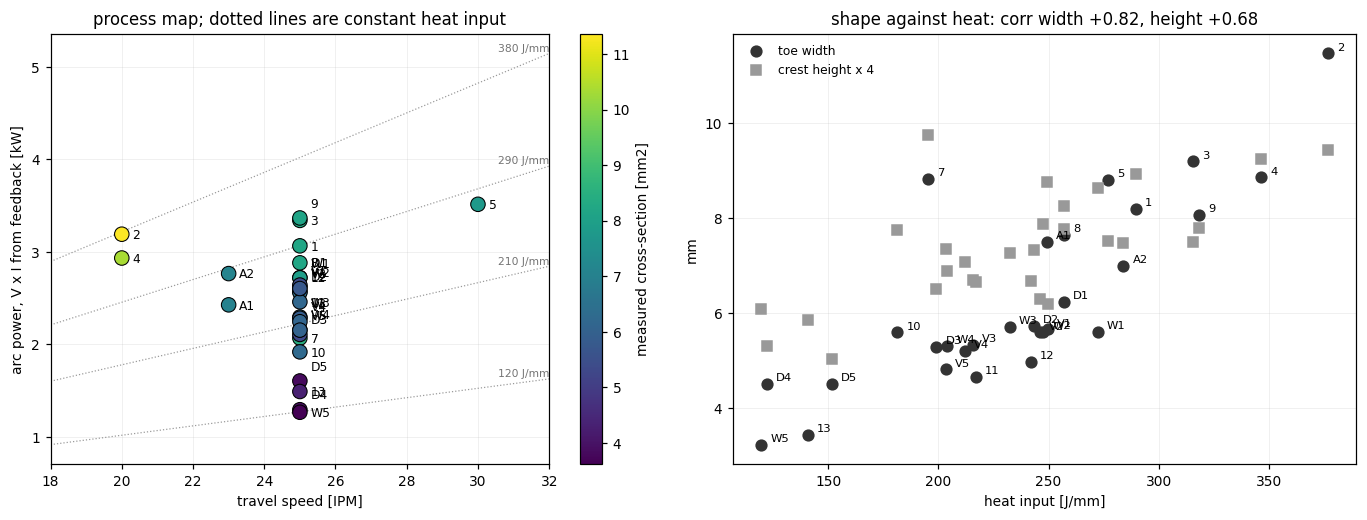

corr(area left over after lambda, heat input) +0.11
Near zero is what the mass balance predicts: heat moves the shape, not the amount of metal. A strong value here would mean heat changes how much wire ends up in the bead, which is eta varying with the arc.


In [45]:
def plot_process_map(records):
    have = [r for r in records if np.isfinite(r['power'])]
    if len(have) < 2:
        print('Fewer than two beads carry arc feedback. Fill ARC_FEEDBACK from the '
              'Power Wave Manager export and run section 11 again.')
        return
    travel = np.array([r['travel'] for r in have])
    power = np.array([r['power'] for r in have]) / 1000.0
    area = np.array([r['area'] for r in have])
    heat = np.array([r['heat'] for r in have])
    width = np.array([r['width'] for r in have])
    height = np.array([r['height'] for r in have])

    fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.8))

    ts_axis = np.linspace(travel.min() - 2, travel.max() + 2, 50)
    for q in np.round(np.linspace(heat.min(), heat.max(), 4), -1):
        ax[0].plot(ts_axis, q * ts_axis * IPM_TO_MM_S / 1000.0, ':', color='0.6', lw=0.8)
        ax[0].annotate(f'{q:.0f} J/mm', (ts_axis[-1], q * ts_axis[-1] * IPM_TO_MM_S / 1000),
                       fontsize=7, color='0.45', ha='right', va='bottom')
    points = ax[0].scatter(travel, power, c=area, cmap='viridis', s=90,
                           edgecolors='black', linewidths=0.7, zorder=3)
    plt.colorbar(points, ax=ax[0], label='measured cross-section [mm2]')
    for k, (r, x, y) in enumerate(zip(have, travel, power)):
        crowded = any(j != k and abs(x - travel[j]) < 0.5 and 0 < y - power[j] < 0.12
                      for j in range(len(have)))
        ax[0].annotate(str(r['test']), (x, y), textcoords='offset points',
                       xytext=(7, 7) if crowded else (7, -3), fontsize=8)
    ax[0].set_xlabel('travel speed [IPM]')
    ax[0].set_ylabel('arc power, V x I from feedback [kW]')
    ax[0].set_title('process map; dotted lines are constant heat input')
    ax[0].set_xlim(ts_axis.min(), ts_axis.max())
    ax[0].grid(alpha=0.3, lw=0.4)

    ax[1].plot(heat, width, 'o', color='0.2', ms=7, label='toe width')
    ax[1].plot(heat, height * 4, 's', color='0.6', ms=6, label='crest height x 4')
    for r, q, w in zip(have, heat, width):
        ax[1].annotate(str(r['test']), (q, w), textcoords='offset points',
                       xytext=(6, 2), fontsize=7.5)
    ax[1].set_xlabel('heat input [J/mm]')
    ax[1].set_ylabel('mm')
    ax[1].set_title(f'shape against heat: corr width {np.corrcoef(heat, width)[0, 1]:+.2f}, '
                    f'height {np.corrcoef(heat, height)[0, 1]:+.2f}')
    ax[1].legend(fontsize=8, frameon=False)
    ax[1].grid(alpha=0.3, lw=0.4)

    fig.tight_layout()
    plt.show()

    if len(have) >= 3:
        lam = np.array([r['lam'] for r in have])
        slope = float(lam @ area / (lam @ lam))
        leftover = area - slope * lam
        print(f'corr(area left over after lambda, heat input) '
              f'{np.corrcoef(leftover, heat)[0, 1]:+.2f}')
        print('Near zero is what the mass balance predicts: heat moves the shape, '
              'not the amount of metal. A strong value here would mean heat changes '
              'how much wire ends up in the bead, which is eta varying with the arc.')


if records:
    plot_process_map(records)

**How to read the process map.** Each point is one run, placed by its travel
speed and the power the arc actually drew, and coloured by the area measured.
Dotted lines are constant heat input: moving along one keeps $Q$ fixed while
both speed and power rise.

* Points on the same dotted line put the same heat into each millimetre. If they
  differ in width, something besides heat is setting the spread.
* The right panel separates what heat does from what $\lambda$ does. Width should
  rise with heat input and height should fall; if both rise together, the extra
  width is coming from extra metal, and the two effects are not separated.
* The printed correlation checks the mass balance from the other side: once
  $\lambda$ is accounted for, what is left of the area should not track heat.

Power is taken from the feedback, not from the commanded voltage, because the
source picks the current itself: at one wire feed, raising the voltage lengthens
the arc and shortens the wire stickout, and the current changes to compensate.

### Wire feed against arc power at fixed travel speed

From schedule 7 on, travel speed stays at 25 IPM, so the runs lie in the plane of
wire feed against arc power, $P = V_{fb} I_{fb}$, with nothing else changing. At a
fixed wire feed the voltage setting moves a run sideways in power; the colour is
the measured cross-section. Runs at other travel speeds are left out of this view.

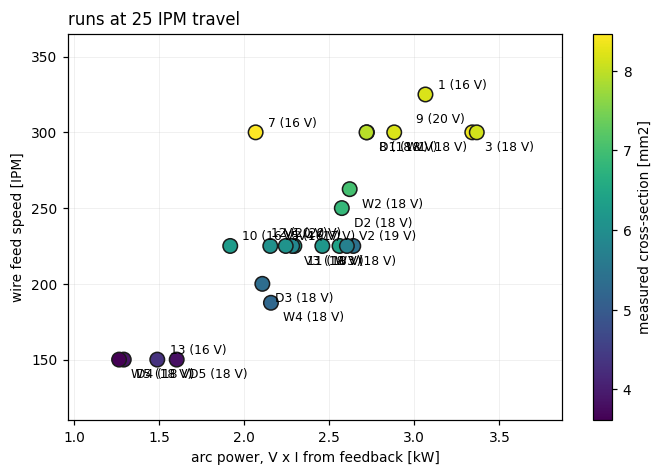

In [46]:
fixed = [r for r in records if abs(r['travel'] - 25) < 1e-6 and np.isfinite(r['power'])]
if fixed:
    fig, ax = plt.subplots(figsize=(6.4, 4.4))
    pts = ax.scatter([r['power'] / 1000 for r in fixed], [r['wfs'] for r in fixed],
                     c=[r['area'] for r in fixed], cmap='viridis', s=90,
                     edgecolors='0.1', zorder=3)
    for r in fixed:
        ax.annotate(f"{r['test']} ({r['voltage']:.0f} V)", (r['power'] / 1000, r['wfs']),
                    xytext={16: (8, 4), 18: (8, -12), 20: (-8, 6)}.get(int(r['voltage']), (8, 4)),
                    ha='right' if r['voltage'] == 20 else 'left',
                    textcoords='offset points', fontsize=8)
    fig.colorbar(pts, ax=ax, label='measured cross-section [mm2]')
    ax.set_xlabel('arc power, V x I from feedback [kW]')
    ax.set_ylabel('wire feed speed [IPM]')
    ax.set_title('runs at 25 IPM travel', loc='left')
    ax.set_ylim(min(r['wfs'] for r in fixed) - 40, max(r['wfs'] for r in fixed) + 40)
    p_kw = [r['power'] / 1000 for r in fixed]
    ax.set_xlim(min(p_kw) - 0.3, max(p_kw) + 0.5)
    ax.grid(alpha=0.3, lw=0.4)
    fig.tight_layout()
    plt.show()
else:
    print('No run at 25 IPM with arc feedback in the results yet.')

### Design coverage and where the prediction is trusted

The fit gives a slope; the design says where it will be used. Those are not the
same range. A test whose $\lambda$ falls outside the span of the beads already
welded is predicted by extending the line past its evidence, and the line has no
way to signal that it has stopped being valid there.

Because $\lambda = \text{WFS}/\text{TS}$, a fixed $\lambda$ is a straight line
through the origin in the speed plane. The calibrated span is therefore a wedge,
and everything outside it is extrapolation.

In [47]:
def prediction_band(lam_fit, area_fit):
    '''Slope, its standard error, and the residual scatter about it. The band a
    new bead is expected to land in combines both: the line itself is uncertain,
    and the process scatters about wherever the line truly is.'''
    lam_fit, area_fit = np.asarray(lam_fit, float), np.asarray(area_fit, float)
    slope = float(lam_fit @ area_fit / (lam_fit @ lam_fit))
    residual = area_fit - slope * lam_fit
    if len(lam_fit) > 1:
        scatter = float(np.sqrt(residual @ residual / (len(lam_fit) - 1)))
        slope_se = scatter / float(np.sqrt(lam_fit @ lam_fit))
    else:
        scatter = slope_se = float('nan')
    return slope, slope_se, scatter


def design_table(test_matrix, extra, welded, lam_lo, lam_hi, slope, slope_se, scatter):
    '''Every planned trial with its lambda, predicted area and expected spread.'''
    trials = []
    for name, (wfs, travel, voltage) in {**test_matrix, **extra}.items():
        lam = wfs / travel
        trials.append(dict(
            test=name, wfs=wfs, travel=travel, voltage=voltage, lam=lam,
            predicted=slope * lam,
            sigma=float(np.sqrt((lam * slope_se) ** 2 + scatter ** 2)),
            extrapolated=not (lam_lo <= lam <= lam_hi),
            welded=name in welded))
    return sorted(trials, key=lambda t: t['lam'])



if records:
    lam_done, area_done = lam[used], area[used]
    slope, slope_se, scatter = prediction_band(lam_done, area_done)
    lam_lo, lam_hi = float(lam_done.min()), float(lam_done.max())
    welded_ids = {r['test'] for r in records}

    trials = design_table(TEST_MATRIX, EXTRA_SCHEDULES, welded_ids,
                          lam_lo, lam_hi, slope, slope_se, scatter)

    print(f'calibrated on  {len(lam_done)} points, lambda {lam_lo:.2f} to {lam_hi:.2f}')
    print(f'slope          {slope:.4f} +/- {slope_se:.4f} mm2 per unit lambda')
    print(f'scatter        {scatter:.3f} mm2 about the line\n')
    print(f'{"trial":>6} {"WFS":>4} {"TS":>3} {"V":>3} {"lambda":>7} '
          f'{"A_pred":>7} {"+/-2sd":>7}  {"status":<12}')
    print('-' * 60)
    for t in trials:
        status = ('welded' if t['welded'] else
                  'EXTRAPOLATED' if t['extrapolated'] else 'within range')
        print(f'{str(t["test"]):>6} {t["wfs"]:>4} {t["travel"]:>3} {t["voltage"]:>3} '
              f'{t["lam"]:>7.2f} {t["predicted"]:>7.2f} {2 * t["sigma"]:>7.3f}  {status:<12}')

    outside = [t['test'] for t in trials if t['extrapolated'] and not t['welded']]
    if outside:
        print(f'\nOutside the calibrated wedge: {outside}. The prediction there '
              'extends the line past its evidence, so weld one of them early: it '
              'is where the model will fail first if it is going to.')

    groups = {}
    for t in trials:
        groups.setdefault(round(t['lam'], 3), []).append(t)
    shared = {k: v for k, v in groups.items() if len(v) > 1}
    if shared:
        print('\nTrials sharing a lambda:')
        for lam, members in sorted(shared.items()):
            voltages = sorted({t['voltage'] for t in members})
            ids = ', '.join(str(t['test']) for t in members)
            kind = ('repeat at one setting, so the spread is process noise'
                    if len(voltages) == 1 else
                    f'same lambda at {voltages} V, so any area difference is voltage')
            print(f'   lambda {lam:6.2f}: {ids}  -- {kind}')
else:
    trials = []
    print(f'No welded beads in {RESULTS_CSV}, so there is nothing to predict from. The '
          'recording cell above did not write this plate: its message says why, usually '
          'that the number of beads found differs from the entries in PLATE_BEADS.')

calibrated on  29 points, lambda 6.00 to 16.25
slope          0.6608 +/- 0.0093 mm2 per unit lambda
scatter        0.528 mm2 about the line

 trial  WFS  TS   V  lambda  A_pred  +/-2sd  status      
------------------------------------------------------------
    13  150  25  16    6.00    3.97   1.062  welded      
    14  150  25  18    6.00    3.97   1.062  within range
    15  150  25  20    6.00    3.97   1.062  within range
    10  225  25  16    9.00    5.95   1.070  welded      
    11  225  25  18    9.00    5.95   1.070  welded      
    12  225  25  20    9.00    5.95   1.070  welded      
     5  325  30  18   10.83    7.16   1.076  welded      
     3  300  25  18   12.00    7.93   1.080  welded      
     7  300  25  16   12.00    7.93   1.080  welded      
     8  300  25  18   12.00    7.93   1.080  welded      
     9  300  25  20   12.00    7.93   1.080  welded      
    A1  276  23  16   12.00    7.93   1.080  welded      
    A2  276  23  17   12.00    7.93   1.080 

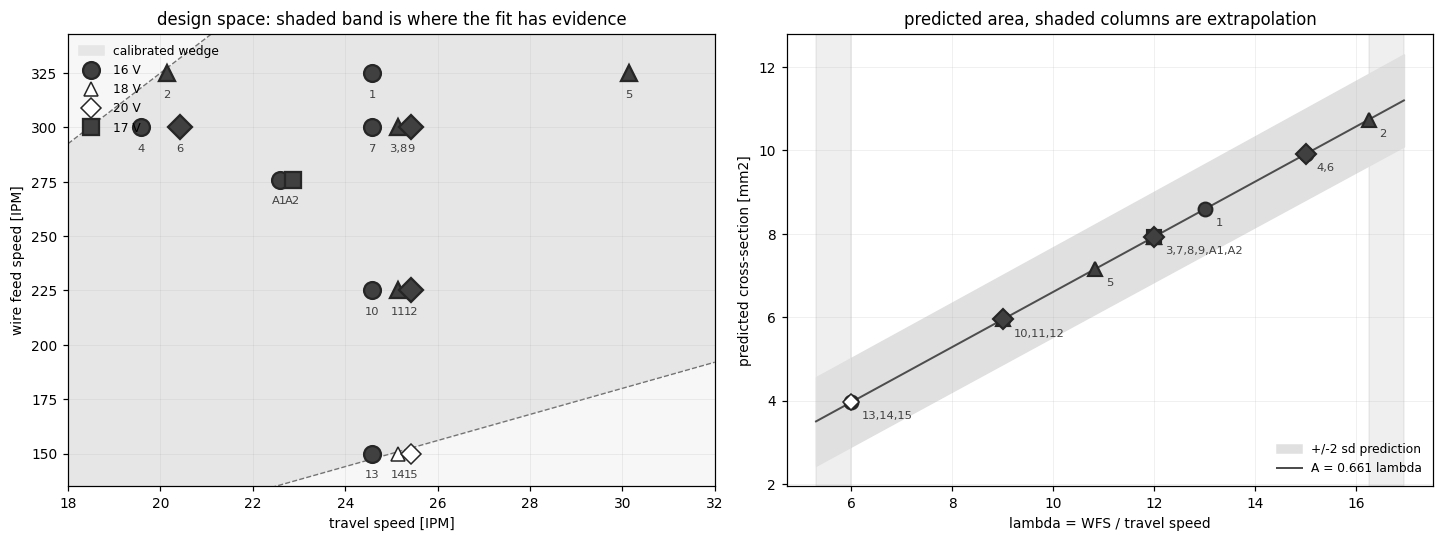

In [48]:
def plot_design_map(trials, lam_lo, lam_hi, slope, slope_se, scatter):
    voltages = sorted({t['voltage'] for t in trials})
    marker = dict(zip(voltages, 'os^Dvph'))
    spread = np.linspace(-0.42, 0.42, len(voltages)) if len(voltages) > 1 else [0.0]
    offset = dict(zip(voltages, spread))
    fig, ax = plt.subplots(1, 2, figsize=(13.2, 5.0))

    travel = np.array([t['travel'] for t in trials], float)
    feed = np.array([t['wfs'] for t in trials], float)
    ts_axis = np.linspace(travel.min() - 2, travel.max() + 2, 60)

    # The calibrated wedge, and the two extrapolation zones either side of it.
    ax[0].fill_between(ts_axis, lam_lo * ts_axis, lam_hi * ts_axis,
                       color='0.90', zorder=0, label='calibrated wedge')
    ax[0].fill_between(ts_axis, 0, lam_lo * ts_axis, color='0.97', zorder=0)
    ax[0].fill_between(ts_axis, lam_hi * ts_axis, 1e4, color='0.97', zorder=0)
    for value, label_at in ((lam_lo, 'lambda low'), (lam_hi, 'lambda high')):
        ax[0].plot(ts_axis, value * ts_axis, '--', color='0.45', lw=0.9, zorder=1)

    grouped = {}
    for t in trials:
        grouped.setdefault((t['travel'] + offset[t['voltage']], t['wfs']), []).append(t)
    seen = set()
    for (x, y), members in grouped.items():
        voltage = members[0]['voltage']
        done = any(t['welded'] for t in members)
        ax[0].plot(x, y, marker[voltage], ms=11 if done else 9,
                   mfc='0.25' if done else 'white', mec='0.15',
                   mew=1.5 if done else 1.0, zorder=3,
                   label=f'{voltage} V' if voltage not in seen else None)
        seen.add(voltage)
        ax[0].annotate(','.join(str(t['test']) for t in members), (x, y),
                       textcoords='offset points', xytext=(0, -16),
                       ha='center', fontsize=7.5, color='0.25')
    ax[0].set_xlim(travel.min() - 2, travel.max() + 2)
    ax[0].set_ylim(feed.min() - 15, feed.max() + 18)
    ax[0].set_xlabel('travel speed [IPM]')
    ax[0].set_ylabel('wire feed speed [IPM]')
    ax[0].set_title('design space: shaded band is where the fit has evidence')
    ax[0].legend(fontsize=8, loc='upper left', frameon=False)
    ax[0].grid(alpha=0.3, lw=0.4)

    lam_axis = np.linspace(min(t['lam'] for t in trials) - 0.7,
                           max(t['lam'] for t in trials) + 0.7, 120)
    band = np.sqrt((lam_axis * slope_se) ** 2 + scatter ** 2)
    ax[1].fill_between(lam_axis, slope * lam_axis - 2 * band,
                       slope * lam_axis + 2 * band, color='0.88',
                       label='+/-2 sd prediction')
    ax[1].plot(lam_axis, slope * lam_axis, '-', color='0.3', lw=1.3,
               label=f'A = {slope:.3f} lambda')
    ax[1].axvspan(lam_axis.min(), lam_lo, color='0.5', alpha=0.12, zorder=0)
    ax[1].axvspan(lam_hi, lam_axis.max(), color='0.5', alpha=0.12, zorder=0)

    by_lambda = {}
    for t in trials:
        by_lambda.setdefault(round(t['lam'], 3), []).append(t)
    for lam, members in sorted(by_lambda.items()):
        predicted = members[0]['predicted']
        for depth, t in enumerate(sorted(members, key=lambda m: m['voltage'])):
            ax[1].plot(lam, predicted, marker[t['voltage']],
                       ms=9 if t['welded'] else 7,
                       mfc='0.25' if t['welded'] else 'white', mec='0.15',
                       mew=1.4 if t['welded'] else 1.0, zorder=3 + depth)
        ax[1].annotate(','.join(str(t['test']) for t in members), (lam, predicted),
                       textcoords='offset points', xytext=(7, -11),
                       fontsize=7.5, color='0.25')
    ax[1].set_xlabel('lambda = WFS / travel speed')
    ax[1].set_ylabel('predicted cross-section [mm2]')
    ax[1].set_title('predicted area, shaded columns are extrapolation')
    ax[1].legend(fontsize=8, loc='lower right', frameon=False)
    ax[1].grid(alpha=0.3, lw=0.4)

    fig.tight_layout()
    plt.show()


if trials and np.isfinite(scatter):
    plot_design_map(trials, lam_lo, lam_hi, slope, slope_se, scatter)
elif trials:
    print('One bead cannot give a scatter, so there is no band to draw. '
          'Weld a second at a different lambda.')

**How to read the design space.** Travel speed across, wire feed up, so every
point is one trial. Voltage is the marker shape, and filled markers are beads
already welded. Labels list the trials at that setting, so `3,8,13` is three
trials sharing one point.

Because $\lambda$ is the ratio of the two axes, a line of constant $\lambda$ runs
from the origin through the plane: **steeper lines are more wire per millimetre
travelled, and bigger beads.** Points on one such line should all give the same
cross-section, whatever their speeds, which is the claim the mass balance makes.

* **Inside the shaded band** — $\lambda$ lies between the lowest and highest
  already welded, so the prediction interpolates. The $\pm2$ sd figure in the
  table is the whole expected error.
* **Outside it** — the prediction extends the line past any bead that supports
  it. The stated interval still assumes the line holds there, so the real error
  can be larger without warning. Weld these early.
* **Points stacked on one $\lambda$ line at different voltages** — same wire per
  millimetre, different arc. If their measured areas match, $\lambda$ describes
  the process on its own. If they separate, voltage moves the area too and the
  model needs a second term.
* **Points at one setting repeated** — the spread among them is process noise,
  and it sets the floor no correction can go below.

Moving up and right along the same $\lambda$ line keeps the bead area but raises
both speeds, so the arc travels faster over hotter metal. Area may hold while
the bead gets narrower and taller, which the right panel cannot show: that
belongs to the width and height columns of section 7.

## 12. Comparison against the vernier caliper

**Theory.** The scan has no external reference: the bar in section 3 checks scale
in the plane, nothing checks height. A caliper reading of the same divisions
gives an independent estimate, and the difference $d_i = \text{scan}_i -
\text{caliper}_i$ splits into a systematic and a random part:

$$\bar d \;(\text{bias}), \qquad s_d \;(\text{repeatability}), \qquad
\text{RMSE}^2 = \bar d^{\,2} + s_d^{\,2}, \qquad
\text{LoA} = \bar d \pm 1.96\,s_d$$

A bias is correctable with one constant; $s_d$ is not. The correlation
coefficient is reported but is not accuracy — a method reading double the truth
still gives $r = 1$. What matters is distance from the identity line.

**Protocol — three things that went wrong before and how to avoid them.**

1. **Measure at the division centres**, the white dots in section 7, not at the
   ends of a bead. The ends are arc start and stop ramps where height changes
   fast, so a small positioning error there becomes a large height difference and
   is read as scanner error.
2. **Record the physical position** (`upper right`, `centre`, …), not a bead
   number read off the screen. The join is by `(plate, position, station)`.
3. **Do not subtract plate thickness.** Height is the difference of two caliper
   readings — over the crest and on the plate beside the bead — so the plate
   cancels. Subtracting it again removes several millimetres and makes every
   comparison meaningless.

Fill in `caliper_measurements.csv` and re-run; the section is inert until the file
exists.

In [49]:
def write_caliper_template(path, beads, positions, plate_id):
    with open(path, 'w', newline='') as handle:
        writer = csv.writer(handle)
        writer.writerow(['plate', 'position', 'station', 's_mid_mm',
                         'h_caliper_mm', 'w_caliper_mm'])
        for bead in beads:
            for d in bead['divisions']:
                writer.writerow([plate_id, positions.get(bead['id'], ''), d['division'],
                                 f"{d['s_mid']:.1f}", '', ''])


def load_caliper(path):
    rows = []
    with open(path) as handle:
        for record in csv.DictReader(handle):
            if not record['h_caliper_mm'].strip():
                continue
            width = record.get('w_caliper_mm', '').strip()
            rows.append(dict(plate=int(record['plate']),
                             position=record['position'].strip(),
                             station=int(record['station']),
                             height=float(record['h_caliper_mm']),
                             width=float(width) if width else None))
    return rows


def match_scan_to_caliper(beads, caliper_rows, positions, plate_id):
    '''Join on (plate, physical position, station).'''
    reference = {(row['plate'], row['position'], row['station']): row
                 for row in caliper_rows}
    matched = []
    for bead in beads:
        label = positions.get(bead['id'], '')
        for d in bead['divisions']:
            row = reference.get((plate_id, label, d['division']))
            if row is None:
                continue
            matched.append(dict(position=label, station=d['division'],
                                h_scan=d['h_peak'], h_caliper=row['height'],
                                w_scan=d['w_toe'], w_caliper=row['width']))
    return matched


template_path = OUT_DIR / 'caliper_template.csv'
write_caliper_template(template_path, beads, POSITIONS, PLATE_ID)
print(f'wrote {template_path} — fill in h_caliper_mm (and w_caliper_mm), save as '
      f'{CALIPER_CSV.name}')

if CALIPER_CSV.exists():
    matched = match_scan_to_caliper(beads, load_caliper(CALIPER_CSV), POSITIONS, PLATE_ID)
    print(f'{len(matched)} divisions matched to caliper readings')
else:
    matched = []
    print(f'{CALIPER_CSV} not found — the comparison below stays empty until it is.')

wrote output/caliper_template.csv — fill in h_caliper_mm (and w_caliper_mm), save as caliper_measurements.csv
output/caliper_measurements.csv not found — the comparison below stays empty until it is.


In [50]:
def agreement(reference, measured, label, unit='mm'):
    difference = measured - reference
    bias, spread = difference.mean(), difference.std()
    stats = dict(n=len(difference), bias=bias, sd=spread,
                 rmse=float(np.sqrt((difference ** 2).mean())),
                 mae=float(np.abs(difference).mean()),
                 r=float(np.corrcoef(reference, measured)[0, 1])
                 if len(reference) > 2 and reference.std() > 0 else float('nan'),
                 loa=(bias - 1.96 * spread, bias + 1.96 * spread),
                 difference=difference)
    print(f'--- {label} ---')
    print(f'  n     {stats["n"]}')
    print(f'  bias  {bias:+.4f} {unit}')
    print(f'  sd    {spread:.4f} {unit}')
    print(f'  RMSE  {stats["rmse"]:.4f} {unit}   '
          f'(bias^2 + sd^2 -> {np.hypot(bias, spread):.4f})')
    print(f'  MAE   {stats["mae"]:.4f} {unit}')
    print(f'  r     {stats["r"]:.4f}')
    print(f'  LoA   [{stats["loa"][0]:+.3f}, {stats["loa"][1]:+.3f}] {unit}')
    return stats


def plot_agreement(reference, measured, groups, stats, title, unit='mm'):
    marks = ['o', 's', '^', 'D', 'v', 'P', 'X', '*']
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))
    low = min(reference.min(), measured.min())
    high = max(reference.max(), measured.max())
    pad = 0.06 * max(high - low, 0.1)
    low, high = low - pad, high + pad
    ax[0].plot([low, high], [low, high], 'k--', lw=0.9, label='identity')
    for k, name in enumerate(sorted(set(groups))):
        take = np.array(groups) == name
        ax[0].plot(reference[take], measured[take], marks[k % len(marks)], mfc='none',
                   mec='k', ms=4.5, lw=0, label=name)
    ax[0].set_xlim(low, high)
    ax[0].set_ylim(low, high)
    ax[0].set_aspect('equal')
    ax[0].set_xlabel(f'caliper [{unit}]')
    ax[0].set_ylabel(f'scanner [{unit}]')
    ax[0].set_title('correlation')
    ax[0].legend(fontsize=7)
    ax[0].grid(alpha=0.3, lw=0.4)

    mean_of_both = 0.5 * (reference + measured)
    ax[1].axhspan(stats['loa'][0], stats['loa'][1], color='0.9')
    ax[1].axhline(0, color='0.5', lw=0.8)
    ax[1].axhline(stats['bias'], color='k', ls='--', lw=1.0)
    for value in stats['loa']:
        ax[1].axhline(value, color='k', ls=':', lw=0.8)
    for k, name in enumerate(sorted(set(groups))):
        take = np.array(groups) == name
        ax[1].plot(mean_of_both[take], stats['difference'][take], marks[k % len(marks)],
                   mfc='none', mec='k', ms=4.5, lw=0)
    ax[1].set_xlabel(f'mean of caliper and scanner [{unit}]')
    ax[1].set_ylabel(f'scanner - caliper [{unit}]')
    ax[1].set_title(f"Bland-Altman: bias {stats['bias']:+.3f}, "
                    f"LoA +/- {1.96 * stats['sd']:.3f} {unit}")
    ax[1].grid(alpha=0.3, lw=0.4)
    fig.suptitle(title, y=1.01)
    fig.tight_layout()
    plt.show()


if matched:
    groups = [row['position'] for row in matched]
    h_scan = np.array([row['h_scan'] for row in matched])
    h_caliper = np.array([row['h_caliper'] for row in matched])
    stats_height = agreement(h_caliper, h_scan, 'HEIGHT: scanner vs caliper')
    plot_agreement(h_caliper, h_scan, groups, stats_height, 'Peak height')

    with_width = [row for row in matched if row['w_caliper'] is not None]
    if with_width:
        w_scan = np.array([row['w_scan'] for row in with_width])
        w_caliper = np.array([row['w_caliper'] for row in with_width])
        stats_width = agreement(w_caliper, w_scan, '\nWIDTH: scanner vs caliper')
        plot_agreement(w_caliper, w_scan, [row['position'] for row in with_width],
                       stats_width, 'Toe width')

    print('\nper position')
    print(f"{'position':>14} {'n':>4} {'bias':>9} {'sd':>8} {'rmse':>8}")
    for name in sorted(set(groups)):
        take = np.array(groups) == name
        if take.sum() < 2:
            continue
        difference = h_scan[take] - h_caliper[take]
        print(f'{name:>14} {take.sum():>4} {difference.mean():>+9.4f} '
              f'{difference.std():>8.4f} {np.sqrt((difference ** 2).mean()):>8.4f}')
else:
    print('No matched readings yet.')

No matched readings yet.


**How to read the agreement plots.** Both axes mm.

* *Correlation* — caliper on $x$, scanner on $y$, one marker per division, dashed
  identity line, markers grouped by physical position. Distance from the line is
  the error; the line itself is the reference.
* *Bland-Altman* — difference against the mean of the two methods. The dashed line
  is the bias, the dotted lines and shaded band the limits of agreement, inside
  which 95% of differences fall.
* *Per position* — the same statistics per bead, because an aggregate bias can
  hide one bead with spatter inflating its toe.

**Good result:** bias small compared with the tolerance in section 8, points
scattered evenly about the bias line, LoA narrower than the process variation
being studied, per-position biases similar.

**Problem:** a trend in the Bland-Altman panel — the two methods disagree more at
larger beads, which is a scale error, not an offset, and one constant will not fix
it; one position offset from the rest — check that bead for spatter or a
mis-stationed reading; a bias of several millimetres — plate thickness was
subtracted somewhere it should not have been.

Expect the toe width to read systematically wider on the scan: the smoothing in
section 6 spreads the toe by about one $\sigma$ per side. That offset should be
stable, and once it is quantified here it is a known correction rather than an
unknown.

## 13. Robot registration and bead placement

Everything above describes the plate in the scanner's frame. To weld on it, the
robot needs the plate in its own frame. This section builds that link from three
points on the plate touched with the robot, shows it, and lets the plate be
turned to check that a bead defined on the plate follows it.

It runs in this order: what to do on the robot, the touches as entered, the two
views of the plate (robot and scanner), the averaged touches, the transformation
matrices, and a control to turn the plate and watch where a bead goes.

### On the robot

The three points are the corner of the plate, one point along the edge at
90 degrees to the robot, and one along the edge aligned with it (Section 2.4 of
the report shows them). Each is touched three times so the average is steadier
than any one touch.

1. Select the torch tool frame, with its TCP at the wire tip, and cut the wire to
   the stick-out used when welding. The TCP is defined at that length.
2. Keep the torch orientation the same for all nine touches. With the same W, P,
   R at every touch, a small error in the TCP definition shifts all nine by the
   same amount; with different orientations it bends the frame instead.
3. Jog the wire tip down onto the plate edge at the corner until it just touches.
4. Open MENU, DATA, Position Register, put the cursor on the register and record
   the current position into it. Use PR[4], PR[5], PR[6] for the three corner
   touches, lifting and coming back between them.
5. Do the same at the 90-degree point (PR[1]-PR[3]) and the aligned point
   (PR[7]-PR[9]).
6. Read X, Y, Z of all nine registers in the same frame, preferably the world
   frame, and type them into `ROBOT_TOUCH_REPEATS` in the next cell.
7. Run this section. It prints the user frame as X, Y, Z, W, P, R.
8. On the pendant, SETUP, Frames, User Frame: pick a number, method Direct Entry,
   and type the six values. Direct entry keeps the average of the three touches;
   the pendant's own three-point method takes one touch per point.
9. Weld programs set `UFRAME_NUM` to that number. Their positions are then plate
   coordinates, and the controller converts them.

**Touching again.** When the plate is unclamped, moved or swapped, only steps 3
to 8 are repeated: touch the three points again, run this section, update the
user frame. The weld programs do not change. Between beads or layers on a plate
that has not moved, nothing is repeated.

### The plate frame

The averaged touches $\mathbf{c}$ (corner), $\mathbf{b}$ (90-degree arm) and
$\mathbf{a}$ (aligned arm), all in robot coordinates [mm], define the plate's
axes directly:

$$\hat{\mathbf{x}} = \frac{\mathbf{b}-\mathbf{c}}{\|\mathbf{b}-\mathbf{c}\|},\qquad
\hat{\mathbf{z}} = \frac{\hat{\mathbf{x}}\times(\mathbf{a}-\mathbf{c})}{\|\hat{\mathbf{x}}\times(\mathbf{a}-\mathbf{c})\|},\qquad
\hat{\mathbf{y}} = \hat{\mathbf{z}}\times\hat{\mathbf{x}}$$

$$T_{robot \leftarrow plate} = \begin{bmatrix}\hat{\mathbf{x}} & \hat{\mathbf{y}} & \hat{\mathbf{z}} & \mathbf{c}\\ 0&0&0&1\end{bmatrix},\qquad
\mathbf{p}_{robot} = T_{robot \leftarrow plate}\,\mathbf{p}_{plate}$$

The origin is the corner touch, $x$ runs through the 90-degree touch, and $z$ is
normal to the plane of the three, so the frame follows the plate's tilt as well as
its turn. This is the same construction as the pendant's three-point method; it
uses only the touches, not the nominal distances between the marks, which were
measured by rule and are the less certain of the two.

In [51]:
# ---- entered by the user ------------------------------------------------------
# Nine touches: three per point, X, Y, Z in mm, all read in the same robot frame.
ROBOT_TOUCH_REPEATS = {
    'arm_90deg':   [(-454.191, -194.388, -3.559),     # PR[1]
                    (-454.074, -194.757, -3.577),     # PR[2]
                    (-454.265, -194.454, -3.595)],    # PR[3]
    'corner':      [(-590.828, -197.895, -2.569),     # PR[4]
                    (-591.083, -197.506, -2.587),     # PR[5]
                    (-590.988, -197.461, -2.603)],    # PR[6]
    'arm_aligned': [(-592.065, -128.269, -4.013),     # PR[7]
                    (-592.091, -128.434, -4.027),     # PR[8]
                    (-592.274, -128.685, -4.045)],    # PR[9]
}
TOUCH_WPR_ROBOT = (2.376, -3.222, 66.449)   # W, P, R the touches were made with

# Beads in plate coordinates: start (x, y) in mm from the corner, angle in degrees
# from the plate x axis (the 90-degree arm), length in mm, weld schedule.
BEAD_PLAN = [
    dict(name='A', start=(15.0, 10.0), angle_deg=90.0, length_mm=40.0, schedule=3),
    dict(name='B', start=(60.0, 10.0), angle_deg=30.0, length_mm=40.0, schedule=3),
]

PLATE_SIZE_MM = (150.0, 100.0)  # drawn rectangle, x by y from the corner; to confirm
PLATE_TURN_DEG = 30.0           # turn previewed when the slider is off or unavailable
PLATE_TURN_SLIDER = True        # slider in Jupyter or VS Code (needs ipywidgets); set
                                # False when running headless, e.g. with nbconvert
USER_FRAME = 1
TOOL_FRAME = 1
APPROACH_MM = 20.0              # approach and retract height above the plate
TCP_HEIGHT_MM = 0.0             # TCP above the plate surface while welding

TOUCH_SPREAD_WARN_MM = 0.5      # a touch group looser than this was not repeatable
CORNER_ANGLE_TOL_DEG = 3.0      # how far the touched corner may sit from square
MAX_EXTRAPOLATION_MM = 50.0     # how far past the scan an arm touch may lie and
                                # still be placed by extending its fitted edge

The next cell holds the machinery: the frame construction, the search for the
plate corner in the scan, Kabsch, and the program writer. Nothing in it needs
editing.

In [52]:
def average_touches(repeats):
    '''Mean position of a touch group, with the spread that justifies it.'''
    points = np.asarray(repeats, float)
    mean = points.mean(axis=0)
    return dict(mean=mean,
                sd=points.std(axis=0, ddof=1) if len(points) > 1 else np.zeros(3),
                spread=float(np.linalg.norm(points - mean, axis=1).max()),
                n=len(points))


def frame_from_three(origin, x_point, y_point):
    '''Right-handed frame from three points: origin, a point on +x, a point in
    the xy plane on the +y side. Returns the 4x4 that maps frame coordinates to
    the coordinates the points were given in.'''
    x = x_point - origin
    x = x / np.linalg.norm(x)
    z = np.cross(x, y_point - origin)
    z = z / np.linalg.norm(z)
    y = np.cross(z, x)
    T = np.eye(4)
    T[:3, :3] = np.column_stack([x, y, z])
    T[:3, 3] = origin
    return T


def invert_rigid(T):
    inverse = np.eye(4)
    inverse[:3, :3] = T[:3, :3].T
    inverse[:3, 3] = -T[:3, :3].T @ T[:3, 3]
    return inverse


def wpr_from_rotation(R):
    '''FANUC W, P, R in degrees: rotations about the fixed X, Y and Z axes,
    applied in that order, so R = Rz(r) Ry(p) Rx(w).'''
    return (float(np.degrees(np.arctan2(R[2, 1], R[2, 2]))),
            float(np.degrees(np.arcsin(-np.clip(R[2, 0], -1, 1)))),
            float(np.degrees(np.arctan2(R[1, 0], R[0, 0]))))


def rotation_from_wpr(w, p, r):
    w, p, r = np.radians([w, p, r])
    Rx = np.array([[1, 0, 0], [0, np.cos(w), -np.sin(w)], [0, np.sin(w), np.cos(w)]])
    Ry = np.array([[np.cos(p), 0, np.sin(p)], [0, 1, 0], [-np.sin(p), 0, np.cos(p)]])
    Rz = np.array([[np.cos(r), -np.sin(r), 0], [np.sin(r), np.cos(r), 0], [0, 0, 1]])
    return Rz @ Ry @ Rx


def show(name, T):
    print(name)
    for row in T:
        print('   ' + '  '.join(f'{v:11.5f}' for v in row))


def plate_step_points(points, cell_mm=0.5, band_mm=1.5, drop_mm=4.0,
                      table_within_mm=10.0):
    '''Where the plate ends: cells on the boundary of the plate surface with the
    table visible within table_within_mm of them.

    The plate can end at a gap that shows the table, against a fixture bar with
    no gap, or in a scanner shadow beside that bar. Taking only the drop to the
    table finds the first case and puts the other two on the far side of the
    bar, several millimetres out. Every plate boundary is a candidate instead,
    and the table has to be close: that rules out the edge of the scan, where
    nothing lies beyond, and the toes of the beads, which sit well inside.'''
    origin = points[:, :2].min(axis=0)
    index = np.floor((points[:, :2] - origin) / cell_mm).astype(int)
    top = np.full(tuple(index.max(axis=0) + 1), np.nan)
    np.fmax.at(top, (index[:, 0], index[:, 1]), points[:, 2])
    seen = np.isfinite(top)
    plate = seen & (np.abs(top) < band_mm)
    plate = ndimage.binary_opening(plate, np.ones((3, 3)))
    # Screw heads and clamp pads sit at plate height too, as islands beside it.
    # Only the largest connected piece is the plate.
    pieces, n_pieces = ndimage.label(plate)
    if n_pieces > 1:
        sizes = ndimage.sum(plate, pieces, range(1, n_pieces + 1))
        plate = pieces == 1 + int(np.argmax(sizes))
    plate = ndimage.binary_fill_holes(plate)
    boundary = plate & ~ndimage.binary_erosion(plate, np.ones((3, 3)))
    table = seen & (top < -drop_mm)
    reach = int(round(table_within_mm / cell_mm))
    near_table = ndimage.binary_dilation(table, np.ones((3, 3)), iterations=reach)
    i, j = np.where(boundary & near_table)
    return origin + (np.column_stack([i, j]) + 0.5) * cell_mm


def fit_edge_line(xy, tol_mm=2.0, trials=600, seed=0, across=None,
                  min_angle_deg=60.0):
    '''RANSAC line through the step points, refined by total least squares on
    its inliers. The tolerance is loose on purpose: a fixture rim along the edge
    blurs where the step is by a millimetre or so. With `across` given, only
    lines at least min_angle_deg from it are considered, so the second edge
    cannot be a second step running beside the first.'''
    rng = np.random.default_rng(seed)
    best = None
    for _ in range(trials):
        a, b = xy[rng.choice(len(xy), 2, replace=False)]
        d = b - a
        if np.hypot(*d) < 10:
            continue
        d = d / np.hypot(*d)
        if across is not None and np.degrees(np.arccos(min(1.0, abs(d @ across)))) < min_angle_deg:
            continue
        n = np.array([-d[1], d[0]])
        inliers = np.abs((xy - a) @ n) < tol_mm
        if best is None or inliers.sum() > best.sum():
            best = inliers
    if best is None:
        return None
    pts = xy[best]
    centre = pts.mean(axis=0)
    direction = np.linalg.svd(pts - centre)[2][0]
    spread = float(np.std((pts - centre) @ np.array([-direction[1], direction[0]])))
    return centre, direction, best, spread


def physical_corner(points, min_inliers=40):
    '''The one plate corner the scan can actually see: two step edges, fitted in
    turn, meeting near a right angle.'''
    step = plate_step_points(points)
    if len(step) < 2 * min_inliers:
        return None
    first = fit_edge_line(step)
    if first is None:
        return None
    c1, d1, in1, s1 = first
    rest = step[~in1]
    if len(rest) < min_inliers:
        return None
    second = fit_edge_line(rest, seed=1, across=d1)
    if second is None:
        return None
    c2, d2, in2, s2 = second
    if in1.sum() < min_inliers or in2.sum() < min_inliers:
        return None
    free_angle = float(np.degrees(np.arccos(abs(d1 @ d2))))
    # A plate is cut square, and the edge with more support fixes the direction
    # far better than the other can: take the second edge perpendicular to the
    # first and fit only where it sits. Its points scatter along the first edge,
    # and that scatter is how well the corner is placed in that direction.
    across = np.array([-d1[1], d1[0]])
    if across @ d2 < 0:
        across = -across
    along = (rest[in2] - c1) @ d1
    offset = float(np.median(along))
    corner = c1 + offset * d1
    position_sd = float(1.4826 * np.median(np.abs(along - offset)))
    e1 = d1 if ((step[in1] - corner) @ d1).mean() > 0 else -d1
    e2 = across if ((rest[in2] - corner) @ across).mean() > 0 else -across
    reach1 = float(((step[in1] - corner) @ e1).max())
    reach2 = float(((rest[in2] - corner) @ e2).max())
    return dict(corner=corner, edges=(e1, e2), reach=(reach1, reach2),
                spread=(s1, s2), inliers=(int(in1.sum()), int(in2.sum())),
                free_angle=free_angle, position_sd=position_sd)


def surface_height(points, xy, inward, start_mm=14, stop_mm=32, radius_mm=3.0):
    '''Plate height beside a touch point. Fixture rims along the edges stand a few
    millimetres proud, so the sample moves inward until it finds plain plate.'''
    flat = points[np.abs(points[:, 2]) < 1.5]
    tree = cKDTree(flat[:, :2])
    for distance in np.arange(start_mm, stop_mm, 2.0):
        near = tree.query_ball_point(xy + inward * distance, radius_mm)
        if len(near) > 10:
            return float(np.median(flat[near, 2])), float(distance)
    return float('nan'), float('nan')


def plane_height(points, target, around, radius_mm=45.0):
    '''Plate height at a point the scan does not reach. A plane is fitted to the
    flat plate within radius_mm of `around`, the last scanned spot on the way
    there, trimmed once of outliers such as bead toes, and evaluated at the
    target. A local plane, because the plate bends: one fitted to the whole plate
    would carry the far side's warp into the extrapolation.'''
    flat = points[np.abs(points[:, 2]) < 1.5]
    near = flat[np.linalg.norm(flat[:, :2] - around, axis=1) < radius_mm]
    A = np.column_stack([near[:, 0], near[:, 1], np.ones(len(near))])
    coef = np.linalg.lstsq(A, near[:, 2], rcond=None)[0]
    residual = near[:, 2] - A @ coef
    keep = np.abs(residual) < 2.5 * residual.std()
    coef = np.linalg.lstsq(A[keep], near[keep, 2], rcond=None)[0]
    residual = near[keep, 2] - A[keep] @ coef
    return float(coef @ [target[0], target[1], 1.0]), float(residual.std()), int(keep.sum())


def kabsch(source, target):
    '''Rigid transform mapping source onto target, with per-point residual.'''
    source_mean, target_mean = source.mean(axis=0), target.mean(axis=0)
    H = (source - source_mean).T @ (target - target_mean)
    U, _, Vt = np.linalg.svd(H)
    reflect = np.sign(np.linalg.det(Vt.T @ U.T)) or 1.0
    rotation = Vt.T @ np.diag([1.0, 1.0, reflect]) @ U.T
    translation = target_mean - rotation @ source_mean
    residual = np.linalg.norm((source @ rotation.T + translation) - target, axis=1)
    return rotation, translation, residual


def turn_sign(origin, a, b):
    '''+1 if going from a to b around origin turns counter-clockwise in plan.'''
    u, v = a[:2] - origin[:2], b[:2] - origin[:2]
    return int(np.sign(u[0] * v[1] - u[1] * v[0]))



def to_robot_frame(points_xyz, transform):
    '''Points in some frame -> robot-frame points, through a 4x4 transform.'''
    pts = np.asarray(points_xyz, float)
    if pts.ndim == 1:
        pts = pts[None, :]
    if pts.shape[1] == 2:
        pts = np.c_[pts, np.zeros(len(pts))]
    return pts @ transform[:3, :3].T + transform[:3, 3]


def plate_rectangle(size_mm):
    '''Corners of the drawn plate rectangle in plate coordinates, closed.'''
    sx, sy = size_mm
    return np.array([[0, 0, 0], [sx, 0, 0], [sx, sy, 0], [0, sy, 0], [0, 0, 0]], float)


def plan_bead(bead, T_plate):
    '''Start, end, approach and retract of one bead, in the plate frame and in the
    robot frame, with the torch turned by the bead angle.'''
    phi = np.radians(bead['angle_deg'])
    direction = np.array([np.cos(phi), np.sin(phi), 0.0])
    start = np.array([*bead['start'], TCP_HEIGHT_MM])
    end = start + bead['length_mm'] * direction
    up = np.array([0.0, 0.0, APPROACH_MM])
    plate_points = [start + up, start, end, end + up]
    torch_plate = rotation_from_wpr(0, 0, bead['angle_deg']) @ rotation_from_wpr(*TORCH_WPR_ALONG_X)
    torch_robot = T_plate[:3, :3] @ torch_plate
    robot_points = [(T_plate @ np.r_[p, 1.0])[:3] for p in plate_points]
    return dict(plate=plate_points, robot=robot_points,
                wpr_plate=wpr_from_rotation(torch_plate),
                wpr_robot=wpr_from_rotation(torch_robot))


def ls_program(name, beads_planned, plan):
    '''A FANUC TP program in .LS form, positions in the user frame. For review:
    run it first in T1 with the arc disabled.'''
    lines, positions, index = [], [], 1
    lines += [f'   1:  UFRAME_NUM={USER_FRAME} ;', f'   2:  UTOOL_NUM={TOOL_FRAME} ;']
    step = 3
    for bead, p in zip(beads_planned, plan):
        ids = list(range(index, index + 4))
        for pid, point in zip(ids, p['plate']):
            w, pp, r = p['wpr_plate']
            positions.append(
                f"P[{pid}]{{\n   GP1:\n\tUF : {USER_FRAME}, UT : {TOOL_FRAME},\t"
                f"CONFIG : 'N U T, 0, 0, 0',\n\tX = {point[0]:9.3f}  mm,\tY = "
                f"{point[1]:9.3f}  mm,\tZ = {point[2]:9.3f}  mm,\n\tW = {w:9.3f} deg,\t"
                f"P = {pp:9.3f} deg,\tR = {r:9.3f} deg\n}};")
        s = bead['schedule']
        lines += [f'{step:4d}:  !bead {bead["name"]}, {bead["angle_deg"]:.0f} deg ;',
                  f'{step + 1:4d}:J P[{ids[0]}] 20% FINE ;',
                  f'{step + 2:4d}:L P[{ids[1]}] 50mm/sec FINE ;',
                  f'{step + 3:4d}:  Arc Start[{s}] ;',
                  f'{step + 4:4d}:L P[{ids[2]}] WELD_SPEED FINE ;',
                  f'{step + 5:4d}:  Arc End[{s}] ;',
                  f'{step + 6:4d}:L P[{ids[3]}] 50mm/sec FINE ;']
        step += 7
        index += 4
    return ('/PROG  ' + name + '\n/ATTR\nDEFAULT_GROUP\t= 1,*,*,*,*;\n/MN\n'
            + '\n'.join(lines) + '\n/POS\n' + '\n'.join(positions) + '\n/END\n')



def touch_noise_sd(repeats):
    '''Per-axis spread of a single touch, pooled over the touched points.'''
    groups = [np.asarray(v, float) for v in repeats.values()]
    residuals = np.vstack([g - g.mean(axis=0) for g in groups])
    dof = sum(len(g) - 1 for g in groups)
    return np.sqrt((residuals ** 2).sum(axis=0) / dof)


def placement(G0, pivot, turn_deg, tilt_deg=(0.0, 0.0), shift=(0.0, 0.0, 0.0)):
    '''The plate set down again: turned about a vertical axis through `pivot`,
    tilted, and shifted. Returns the new plate-to-robot transform.'''
    R = rotation_from_wpr(tilt_deg[0], tilt_deg[1], turn_deg)
    M = np.eye(4)
    M[:3, :3] = R
    M[:3, 3] = pivot + np.asarray(shift) - R @ pivot
    return M @ G0


def retouch(G, touch_points, sd, rng, repeats=3):
    '''What the robot reads at the three points: each touched `repeats` times
    with noise, and averaged.'''
    read = []
    for u in touch_points:
        true = G[:3, :3] @ u + G[:3, 3]
        read.append((true + rng.normal(0, sd, (repeats, 3))).mean(axis=0))
    return read


def landing(G, T_sent, p):
    '''Where a point sent through T_sent actually lands, in plate coordinates.'''
    return (invert_rigid(G) @ T_sent @ np.r_[p, 1.0])[:3]

In [53]:
touches = {name: average_touches(pts) for name, pts in ROBOT_TOUCH_REPEATS.items()}
robot_corner = touches['corner']['mean']
robot_arm_90 = touches['arm_90deg']['mean']
robot_arm_aligned = touches['arm_aligned']['mean']
robot_points = np.array([robot_corner, robot_arm_90, robot_arm_aligned])

arm_90_mm = float(np.linalg.norm((robot_arm_90 - robot_corner)[:2]))
arm_aligned_mm = float(np.linalg.norm((robot_arm_aligned - robot_corner)[:2]))
corner_angle = float(np.degrees(np.arccos(np.clip(
    (robot_arm_90 - robot_corner)[:2] @ (robot_arm_aligned - robot_corner)[:2]
    / (arm_90_mm * arm_aligned_mm), -1, 1))))

T_robot_plate = frame_from_three(robot_corner, robot_arm_90, robot_arm_aligned)
uf = (*T_robot_plate[:3, 3], *wpr_from_rotation(T_robot_plate[:3, :3]))
touch_in_plate = {name: (invert_rigid(T_robot_plate) @ np.r_[p, 1.0])[:3]
                  for name, p in (('corner', robot_corner), ('90-deg arm', robot_arm_90),
                                  ('aligned arm', robot_arm_aligned))}
TORCH_WPR_ALONG_X = wpr_from_rotation(
    T_robot_plate[:3, :3].T @ rotation_from_wpr(*TOUCH_WPR_ROBOT))

# ---- the same corner, found in the scan ---------------------------------------
scan_notes, scan_problems = [], []
robot_from_scanner = None
scanner_points = None
scene = levelled @ rotation_about_z(travel_dir).T     # the frame beads are measured in
found_corner = physical_corner(scene) if up else None
if not up:
    scan_problems.append('the cloud was flipped to put material on +z, which mirrors '
                         'the frame; a rigid transform cannot undo a mirror')
elif found_corner is None:
    scan_problems.append('no plate corner found: the scan needs two plate edges with '
                         'the table visible past them')
elif not beads:
    scan_problems.append('the corner is found, but the beads are needed to tell the two '
                         'edges apart, and none were measured')
else:
    corner = found_corner['corner']
    e1, e2 = found_corner['edges']
    along = np.mean([b['path'][-1] - b['path'][0] for b in beads], axis=0)
    along = along / np.linalg.norm(along)
    e_aligned, e_90 = (e1, e2) if abs(e1 @ along) > abs(e2 @ along) else (e2, e1)
    scan_notes += [
        f'plate corner in the scan ({corner[0]:.2f}, {corner[1]:.2f}), from '
        f'{found_corner["inliers"][0]} and {found_corner["inliers"][1]} edge points',
        f'first edge line scatter {found_corner["spread"][0]:.2f} mm; second edge taken '
        f'square to it (fitted freely {found_corner["free_angle"]:.1f} deg), its position '
        f'uncertain by {found_corner["position_sd"]:.1f} mm',
        f'beads run {abs(e_aligned @ along):.3f} parallel to the aligned-arm edge, '
        f'{abs(e_90 @ along):.3f} to the other']
    p_corner = corner
    p_90 = corner + e_90 * arm_90_mm
    p_aligned = corner + e_aligned * arm_aligned_mm
    coverage = cKDTree(scene[:, :2])
    beyond = {}
    for name, point in (('corner', p_corner), ('90-deg', p_90), ('aligned', p_aligned)):
        if len(coverage.query_ball_point(point, 5.0)) >= 20:
            continue
        gap, nearest = coverage.query(point)
        if name == 'corner':
            scan_problems.append('the corner itself falls outside the scan')
        elif gap > MAX_EXTRAPOLATION_MM:
            scan_problems.append(f'the {name} touch lies {gap:.1f} mm past the scan, '
                                 f'beyond the {MAX_EXTRAPOLATION_MM:.0f} mm allowed')
        else:
            beyond[name] = (float(gap), scene[nearest, :2])
    if turn_sign(p_corner, p_90, p_aligned) != turn_sign(robot_corner, robot_arm_90,
                                                         robot_arm_aligned):
        scan_problems.append('the scanner and the robot see the corner with opposite '
                             'handedness, so the edge assignment or the frame is mirrored')
    if not scan_problems:
        inward = (e_90 + e_aligned) / np.linalg.norm(e_90 + e_aligned)
        z_corner, _ = surface_height(scene, p_corner, inward)
        heights = {}
        for name, point, into in (('90-deg', p_90, e_aligned), ('aligned', p_aligned, e_90)):
            if name in beyond:
                gap, edge_end = beyond[name]
                heights[name], z_sd, used = plane_height(scene, point, edge_end)
                scan_notes.append(
                    f'{name} touch is {gap:.1f} mm past the edge of the scan: placed by '
                    f'extending its fitted edge, height {heights[name]:+.3f} mm from a plane '
                    f'fitted to {used} plate points where the scan ends (scatter {z_sd:.3f} mm)')
            else:
                heights[name], _ = surface_height(scene, point, into)
        scanner_points = np.array([[*p_corner, z_corner], [*p_90, heights['90-deg']],
                                   [*p_aligned, heights['aligned']]])
        rotation, translation, residual = kabsch(scanner_points, robot_points)
        robot_from_scanner = np.eye(4)
        robot_from_scanner[:3, :3] = rotation
        robot_from_scanner[:3, 3] = translation

have_scan = robot_from_scanner is not None
if have_scan:
    T_work_plate = frame_from_three(*scanner_points)
    T_plate_work = invert_rigid(T_work_plate)
    T_robot_work = T_robot_plate @ T_plate_work

print('robot side    ready: user frame from the nine touches')
print('scanner side  ' + ('ready: plate corner found in this scan' if have_scan else
                          'not available -- ' + '; '.join(scan_problems)))

robot side    ready: user frame from the nine touches
scanner side  not available -- no plate corner found: the scan needs two plate edges with the table visible past them


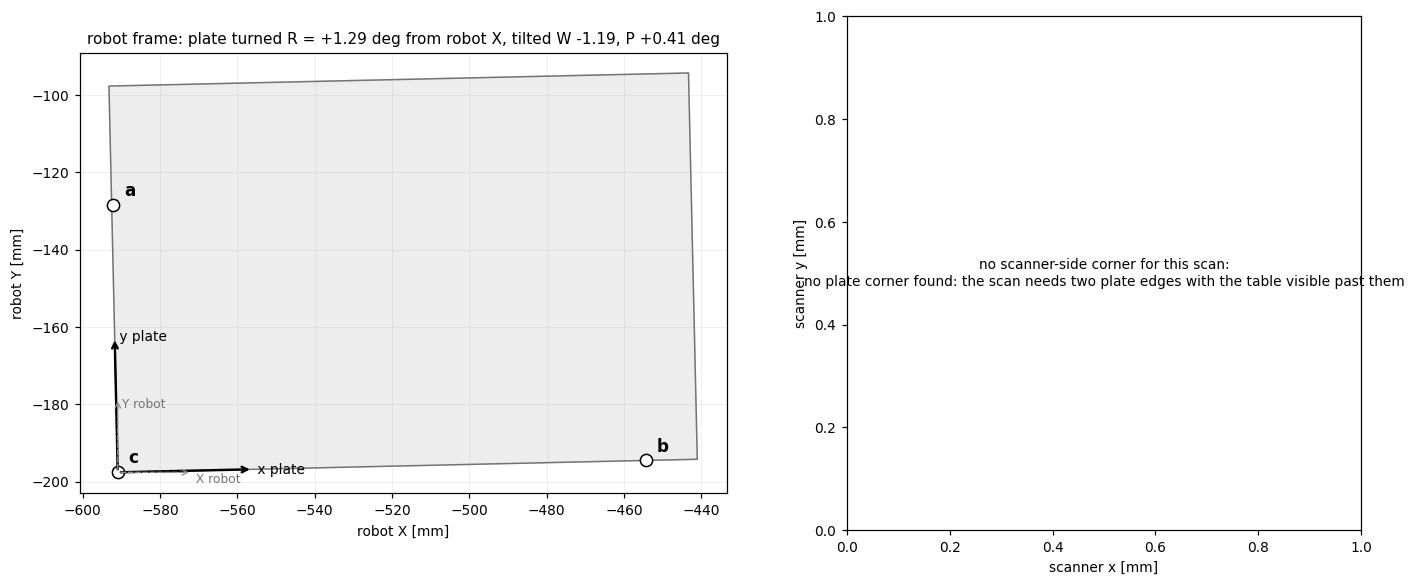

In [54]:
fig, ax = plt.subplots(1, 2, figsize=(13.5, 5.4))
rect_plate = plate_rectangle(PLATE_SIZE_MM)

# ---- robot view -----------------------------------------------------------------
rect = to_robot_frame(rect_plate, T_robot_plate)
ax[0].fill(rect[:, 0], rect[:, 1], color='0.93', zorder=0)
ax[0].plot(rect[:, 0], rect[:, 1], color='0.45', lw=1.0)
for name, pts in ROBOT_TOUCH_REPEATS.items():
    pts = np.asarray(pts)
    ax[0].plot(pts[:, 0], pts[:, 1], 'x', color='0.35', ms=5)
for label, p in (('c', robot_corner), ('b', robot_arm_90), ('a', robot_arm_aligned)):
    ax[0].plot(*p[:2], 'o', mfc='white', mec='black', ms=8, zorder=3)
    ax[0].annotate(label, p[:2], xytext=(7, 6), textcoords='offset points', fontsize=11,
                   weight='bold')
axis_len = 0.35 * min(PLATE_SIZE_MM)
for vec, lab in ((T_robot_plate[:3, 0], 'x plate'), (T_robot_plate[:3, 1], 'y plate')):
    tip = robot_corner[:2] + axis_len * vec[:2]
    ax[0].annotate('', xy=tip, xytext=robot_corner[:2],
                   arrowprops=dict(arrowstyle='->', lw=1.6, color='black'))
    ax[0].text(*tip, ' ' + lab, fontsize=9, va='center')
for vec, lab in (((1, 0), 'X robot'), ((0, 1), 'Y robot')):
    tip = robot_corner[:2] + 0.55 * axis_len * np.array(vec)
    ax[0].annotate('', xy=tip, xytext=robot_corner[:2],
                   arrowprops=dict(arrowstyle='->', lw=0.9, color='0.55', ls='--'))
    ax[0].text(*tip, ' ' + lab, fontsize=8, color='0.45', va='top')
ax[0].set_title(f'robot frame: plate turned R = {uf[5]:+.2f} deg from robot X, '
                f'tilted W {uf[3]:+.2f}, P {uf[4]:+.2f} deg', fontsize=10)
ax[0].set_xlabel('robot X [mm]')
ax[0].set_ylabel('robot Y [mm]')
ax[0].set_aspect('equal')
ax[0].grid(alpha=0.3, lw=0.4)

# ---- scanner view ---------------------------------------------------------------
if have_scan:
    cell = 0.5
    o = scene[:, :2].min(axis=0)
    ij = np.floor((scene[:, :2] - o) / cell).astype(int)
    grid = np.full(tuple(ij.max(axis=0) + 1), np.nan)
    np.fmax.at(grid, (ij[:, 0], ij[:, 1]), scene[:, 2])
    ax[1].imshow(grid.T, origin='lower', cmap='gray', vmin=-7, vmax=4,
                 extent=[o[0], o[0] + grid.shape[0] * cell, o[1], o[1] + grid.shape[1] * cell])
    rect_s = to_robot_frame(rect_plate, T_work_plate)
    ax[1].plot(rect_s[:, 0], rect_s[:, 1], color='white', lw=2.4)
    ax[1].plot(rect_s[:, 0], rect_s[:, 1], color='black', lw=1.0, ls='--')
    for label, p in zip('cba', scanner_points):
        ax[1].plot(*p[:2], 'o', mfc='white', mec='black', ms=8, zorder=3)
        ax[1].annotate(label, p[:2], xytext=(7, 6), textcoords='offset points',
                       fontsize=11, weight='bold', color='black', backgroundcolor='white')
    scan_turn = np.degrees(np.arctan2(T_work_plate[1, 0], T_work_plate[0, 0]))
    ax[1].set_title(f'scanner frame: same plate, turned {scan_turn:+.2f} deg from '
                    f'the scanner x axis', fontsize=10)
    lo = np.minimum(rect_s[:, :2].min(axis=0), o) - 10
    hi = np.maximum(rect_s[:, :2].max(axis=0), o + np.array(grid.shape) * cell) + 10
    ax[1].set_xlim(lo[0], hi[0])
    ax[1].set_ylim(lo[1], hi[1])
else:
    ax[1].text(0.5, 0.5, 'no scanner-side corner for this scan:\n' + '\n'.join(scan_problems),
               ha='center', va='center', transform=ax[1].transAxes, fontsize=9, wrap=True)
ax[1].set_xlabel('scanner x [mm]')
ax[1].set_ylabel('scanner y [mm]')
ax[1].set_aspect('equal')
fig.tight_layout()
plt.show()

**How to read the two views.** Left, the plate as the robot knows it: the nine
touches as crosses, their averages as circles, and the plate rectangle drawn from
the corner along the plate axes the touches define. The dashed arrows are the
robot's own X and Y; the angle between them and the plate axes is the turn the
user frame absorbs. Right, the same plate as the scanner sees it, with the same
rectangle drawn from the corner found in the scan. The rectangle is the drawing
size `PLATE_SIZE_MM`, not a measurement of the plate: only the corner and the two
edge directions are measured, and the scan often stops before the plate does.

In [55]:
print(f'{"point":>13} {"n":>2} {"X":>10} {"Y":>10} {"Z":>8}   '
      f'{"sd X":>6} {"sd Y":>6} {"sd Z":>6} {"spread":>7}')
print('-' * 84)
for name, touch in touches.items():
    m, s = touch['mean'], touch['sd']
    print(f'{name:>13} {touch["n"]:>2} {m[0]:10.3f} {m[1]:10.3f} {m[2]:8.3f}   '
          f'{s[0]:6.3f} {s[1]:6.3f} {s[2]:6.3f} {touch["spread"]:7.3f}')
print(f'\ncorner to 90-deg arm   {arm_90_mm:.2f} mm')
print(f'corner to aligned arm  {arm_aligned_mm:.2f} mm')
print(f'angle at the corner    {corner_angle:.2f} deg')

loose = [n for n, t in touches.items() if t['spread'] > TOUCH_SPREAD_WARN_MM]
if loose:
    print(f'\nTouch groups above {TOUCH_SPREAD_WARN_MM} mm spread: {loose}. Touch those '
          'again, approaching the edge from the same direction each time.')
if abs(corner_angle - 90) > CORNER_ANGLE_TOL_DEG:
    print(f'\nOff square by {abs(corner_angle - 90):.1f} deg. Three points close to a '
          'straight line fix a frame badly: move the touches further apart along the edges.')

        point  n          X          Y        Z     sd X   sd Y   sd Z  spread
------------------------------------------------------------------------------------
    arm_90deg  3   -454.177   -194.533   -3.577    0.096  0.197  0.018   0.246
       corner  3   -590.966   -197.621   -2.586    0.129  0.239  0.017   0.308
  arm_aligned  3   -592.143   -128.463   -4.028    0.114  0.209  0.016   0.258

corner to 90-deg arm   136.82 mm
corner to aligned arm  69.17 mm
angle at the corner    89.68 deg


In [56]:
show('T_robot<-plate  (from the nine touches; this is the user frame)', T_robot_plate)
print(f'\nenter as user frame {USER_FRAME}:  X {uf[0]:.3f}  Y {uf[1]:.3f}  Z {uf[2]:.3f}  '
      f'W {uf[3]:.3f}  P {uf[4]:.3f}  R {uf[5]:.3f}')

print('\nthe touches seen from the plate (p_plate = T_robot<-plate^-1 p_robot):')
for name, p in touch_in_plate.items():
    print(f'   {name:<12} ({p[0]:8.3f}, {p[1]:8.3f}, {p[2]:7.3f})')

if have_scan:
    print()
    for note in scan_notes:
        print(note)
    print('\nscanner-side points / robot-side points:')
    for name, s, r in zip(('corner', '90-deg arm', 'aligned arm'), scanner_points, robot_points):
        print(f'   {name:<12} ({s[0]:8.2f},{s[1]:8.2f},{s[2]:6.2f})   '
              f'({r[0]:9.2f},{r[1]:9.2f},{r[2]:7.2f})')
    show('\nT_robot<-scanner  (Kabsch on the three pairs)', robot_from_scanner)
    w, p, r = wpr_from_rotation(robot_from_scanner[:3, :3])
    print(f'   W {w:+.3f}  P {p:+.3f}  R {r:+.3f} deg;  residual '
          f'{np.round(residual, 3)} mm, RMS {np.sqrt((residual ** 2).mean()):.3f}')
    show('\nT_robot<-work = T_robot<-plate . T_plate<-work  (the same link as a chain)',
         T_robot_work)
    print(f'\n{"bead":>5} {"scanner x, y":>22} {"robot x, y, z":>32}')
    for bead in beads:
        centre = np.array([bead['centroid'][0], bead['centroid'][1], 0.0])
        moved = to_robot_frame(centre, robot_from_scanner)[0]
        print(f'{bead["id"]:>5} ({centre[0]:8.2f}, {centre[1]:8.2f})   '
              f'({moved[0]:9.2f}, {moved[1]:9.2f}, {moved[2]:8.2f})')
    print('\nOnly the corner is found directly in the scan; the two arm points are placed '
          'along the fitted edges at the distances the robot measured, so the residual '
          'carries the corner angle and the heights, not the arm lengths.')
else:
    print('\nNo T_robot<-scanner for this scan: ' + '; '.join(scan_problems) + '.')
    print('T_robot<-plate above does not need the scan and is what the robot uses.')

T_robot<-plate  (from the nine touches; this is the user frame)
       0.99972     -0.02271      0.00677   -590.96633
       0.02257      0.99953      0.02096   -197.62067
      -0.00724     -0.02080      0.99976     -2.58633
       0.00000      0.00000      0.00000      1.00000

enter as user frame 1:  X -590.966  Y -197.621  Z -2.586  W -1.192  P 0.415  R 1.293

the touches seen from the plate (p_plate = T_robot<-plate^-1 p_robot):
   corner       (   0.000,    0.000,  -0.000)
   90-deg arm   ( 136.828,   -0.000,   0.000)
   aligned arm  (   0.394,   69.182,   0.000)

No T_robot<-scanner for this scan: no plate corner found: the scan needs two plate edges with the table visible past them.
T_robot<-plate above does not need the scan and is what the robot uses.


### Five touches: the transformation matrix and the offset for a move

This is the part to run for a new plate. It takes five positions of the wire tip
and a move given on the plate, and returns the transformation matrix and the three
numbers to type in the position register.

**On the robot**

1. Keep the user frame and the tool frame of the weld program active. The tool
   centre point is the wire tip, with the 0.3 in of stick-out already in it.
2. Bring the tip to `TOUCH_GAP_IN` above the plate at five places spread over it,
   with the same torch orientation at all five.
3. At each place read X, Y, Z on the POSITION screen, in USER coordinates, and
   type them into `FIVE_TOUCHES`.
4. Set `ORIGIN_TOUCH` and `X_AXIS_TOUCH`: the plate $x$ axis runs from the first to
   the second.
5. Set the move in `MOVE_X_MM` and `MOVE_Y_MM` and run the cell.

**From the touches to the matrix**

A plane is fitted to the five tips by singular value decomposition. Its normal is
$\hat{\mathbf{z}}$, and the distance of each touch to the plane is the error of
that touch. The line from the origin touch to the $x$ touch, laid on the plane, is
$\hat{\mathbf{x}}$, and $\hat{\mathbf{y}} = \hat{\mathbf{z}}\times\hat{\mathbf{x}}$.
The tips are one gap $g$ above the plate, so the origin is the origin touch
lowered by $g$:

$$\mathbf{T} = \begin{bmatrix}\hat{\mathbf{x}} & \hat{\mathbf{y}} & \hat{\mathbf{z}} &
\mathbf{p}_o\\ 0&0&0&1\end{bmatrix},\qquad
\mathbf{p}_o = \mathbf{p}_{origin} - g\,\hat{\mathbf{z}}$$

**From a move on the plate to the offset**

A point on the plate goes through the whole matrix. A move is the difference
between two points, the origin cancels, and only the rotation
$\mathbf{R} = [\hat{\mathbf{x}}\ \hat{\mathbf{y}}\ \hat{\mathbf{z}}]$ is left:

$$\Delta\mathbf{p}_{robot} = \mathbf{R}\,\Delta\mathbf{p}_{plate} =
a\,\hat{\mathbf{x}} + b\,\hat{\mathbf{y}}$$

for $a$ mm along the plate $x$ and $b$ mm along the plate $y$. These three numbers
go in the position register as X, Y, Z, with W, P, R at zero, and the register is
used as `Offset,PR[n]` after `FINE`. The plate is taken as a plane.

**If the pendant says the position cannot be reached**

The end of the move is the taught point plus the offset, a few mm from a point the
robot already stands on. Check, in this order:

1. The length of the offset equals the move asked for. Values in the hundreds of
   mm mean the origin of the matrix was added to it.
2. The register is Cartesian and its W, P, R are zero.
3. The taught point and the five touches were read in the same user frame, and
   the values of that frame have stayed the same since the point was taught.

Type what the register holds into `REGISTER_TYPED` and the cell runs checks 1 and
2 on it.

touch      X         Y         Z      x plate   y plate   to plane [mm]
  P1    705.969  -239.969   -21.078    183.80   -227.05     -0.026
  P2    546.801  -446.334   -21.038     73.66      9.15     +0.004
  P3    666.578  -320.798   -21.014    130.11   -154.92     +0.038
  P4    588.778  -507.552   -21.066      0.00      0.00     -0.014
  P5    474.258  -286.231   -21.022    249.19      0.00     -0.002

touch to plane   rms 0.021 mm, max 0.038 mm
plate tilt       0.0095 deg from Z

T_robot<-plate  (five touches)
      -0.45956     -0.88815      0.00015    588.77786
       0.88815     -0.45956     -0.00007   -507.55194
       0.00013      0.00011      1.00000    -21.95500
       0.00000      0.00000      0.00000      1.00000

move on the plate   x 0.000   y 20.000 mm
offset for PR[1]    X -17.763   Y -9.191   Z 0.002   W 0   P 0   R 0
length              20.000 mm

program lines
   PR[1]=LPOS-LPOS ;
   PR[1,1]=-17.763 ;
   PR[1,2]=-9.191 ;
   PR[1,3]=0.002 ;
   L P[1] 100mm/sec FINE ;


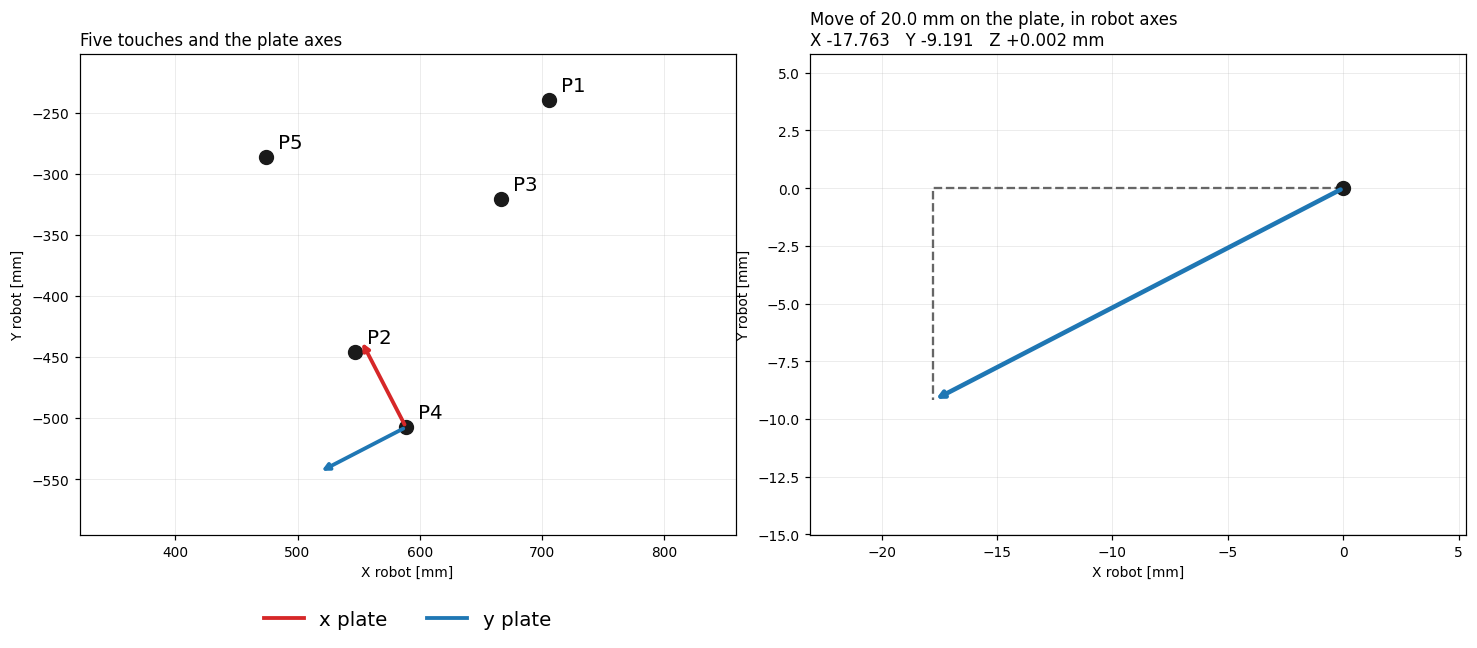

In [57]:
# ---- entered by the user ------------------------------------------------------
FIVE_TOUCHES = [            # X, Y, Z [mm] of the wire tip, USER coordinates
    (705.969, -239.969, -21.078),   # P1
    (546.801, -446.334, -21.038),   # P2
    (666.578, -320.798, -21.014),   # P3
    (588.778, -507.552, -21.066),   # P4
    (474.258, -286.231, -21.022),   # P5
]
ORIGIN_TOUCH = 4            # touch taken as the plate origin
X_AXIS_TOUCH = 5            # touch the plate x axis points to
TOUCH_GAP_IN = 0.035        # wire tip above the plate at every touch
MOVE_X_MM = 0.0             # move asked for along the plate x axis
MOVE_Y_MM = 20.0            # move asked for along the plate y axis
START_POINT = None          # X, Y, Z of the taught start, same frame; or None
REGISTER_TYPED = None       # X, Y, Z, W, P, R now in the register; or None
OFFSET_REGISTER = 1         # position register that holds the offset
TOUCH_TOL_MM = 0.20         # a touch farther than this from the plane is flagged
# ------------------------------------------------------------------------------


def plate_matrix(touches, origin, x_to, gap_mm):
    p = np.asarray(touches, float)[:, :3]
    centre = p.mean(axis=0)
    _, spread, axes = np.linalg.svd(p - centre, full_matrices=False)
    z = axes[2] if axes[2][2] > 0 else -axes[2]
    off_plane = (p - centre) @ z
    x = p[x_to - 1] - p[origin - 1]
    x = x - (x @ z) * z
    x = x / np.linalg.norm(x)
    T = np.eye(4)
    T[:3, :3] = np.c_[x, np.cross(z, x), z]
    T[:3, 3] = p[origin - 1] - gap_mm * z
    return T, off_plane, spread


def offset_for_move(T, along_x, along_y, along_z=0.0):
    return T[:3, :3] @ np.array([along_x, along_y, along_z], float)


def check_register(typed, offset, move_mm):
    typed = np.asarray(typed, float)
    notes = []
    length = np.linalg.norm(typed[:3])
    if abs(length - move_mm) > 0.05:
        notes.append(f'its length is {length:.3f} mm and the move asked for is '
                     f'{move_mm:.3f} mm')
    if length > 10 * max(move_mm, 1.0):
        notes.append('it holds a position: the origin of the matrix was added')
    if len(typed) > 3 and np.abs(typed[3:6]).max() > 1e-3:
        notes.append('W, P, R are not zero: the torch is turned as well as moved')
    if not notes and np.abs(typed[:3] - offset).max() > 0.05:
        notes.append('its length is right and its direction is another one')
    return notes


gap_mm = TOUCH_GAP_IN * 25.4
T_robot_plate5, off_plane5, spread5 = plate_matrix(FIVE_TOUCHES, ORIGIN_TOUCH,
                                                   X_AXIS_TOUCH, gap_mm)
touch5 = np.asarray(FIVE_TOUCHES, float)[:, :3]
on_plate5 = (touch5 - T_robot_plate5[:3, 3]) @ T_robot_plate5[:3, :3]
move_mm = float(np.hypot(MOVE_X_MM, MOVE_Y_MM))
offset5 = offset_for_move(T_robot_plate5, MOVE_X_MM, MOVE_Y_MM)

print('touch      X         Y         Z      x plate   y plate   to plane [mm]')
for k, (p, q, e) in enumerate(zip(touch5, on_plate5, off_plane5), start=1):
    flag = '   <-- check this touch' if abs(e) > TOUCH_TOL_MM else ''
    print(f'  P{k}  {p[0]:9.3f} {p[1]:9.3f} {p[2]:9.3f}  {q[0]:8.2f}  {q[1]:8.2f}'
          f'     {e:+.3f}{flag}')
print(f'\ntouch to plane   rms {np.sqrt(np.mean(off_plane5 ** 2)):.3f} mm, '
      f'max {np.abs(off_plane5).max():.3f} mm')
print(f'plate tilt       {np.degrees(np.arccos(T_robot_plate5[2, 2])):.4f} deg from Z')
if spread5[1] < 0.15 * spread5[0]:
    print('the five touches are close to one line: spread them over the plate')
if np.linalg.norm(touch5[X_AXIS_TOUCH - 1] - touch5[ORIGIN_TOUCH - 1]) < 50:
    print('the origin touch and the x touch are under 50 mm apart: x is poorly set')
show('\nT_robot<-plate  (five touches)', T_robot_plate5)

print(f'\nmove on the plate   x {MOVE_X_MM:.3f}   y {MOVE_Y_MM:.3f} mm')
print(f'offset for PR[{OFFSET_REGISTER}]    X {offset5[0]:.3f}   Y {offset5[1]:.3f}   '
      f'Z {offset5[2]:.3f}   W 0   P 0   R 0')
print(f'length              {np.linalg.norm(offset5):.3f} mm')
if START_POINT is not None:
    end5 = np.asarray(START_POINT, float)[:3] + offset5
    print(f'end of the move     X {end5[0]:.3f}   Y {end5[1]:.3f}   Z {end5[2]:.3f}')
if REGISTER_TYPED is not None:
    found = check_register(REGISTER_TYPED, offset5, move_mm)
    print('\nregister as typed:  ' + ('agrees with the offset' if not found
                                      else '; '.join(found)))

print('\nprogram lines')
for line in (f'PR[{OFFSET_REGISTER}]=LPOS-LPOS ;',
             *(f'PR[{OFFSET_REGISTER},{k}]={value:.3f} ;'
               for k, value in enumerate(offset5, start=1)),
             'L P[1] 100mm/sec FINE ;',
             f'L P[1] 25.0inch/min FINE Offset,PR[{OFFSET_REGISTER}] ;'):
    print('   ' + line)

fig, ax = plt.subplots(1, 2, figsize=(13.5, 6.0))
origin5 = T_robot_plate5[:3, 3]
reach5 = 0.3 * np.ptp(touch5[:, :2], axis=0).max()
ax[0].plot(touch5[:, 0], touch5[:, 1], 'o', color='0.1', ms=9)
for k, p in enumerate(touch5, start=1):
    ax[0].annotate(f'P{k}', p[:2], textcoords='offset points', xytext=(8, 6), fontsize=13)
for axis, name, colour in ((T_robot_plate5[:3, 0], 'x plate', 'tab:red'),
                           (T_robot_plate5[:3, 1], 'y plate', 'tab:blue')):
    ax[0].annotate('', xy=origin5[:2] + reach5 * axis[:2], xytext=origin5[:2],
                   arrowprops=dict(arrowstyle='-|>', color=colour, lw=2.5))
    ax[0].plot([], [], color=colour, lw=2.5, label=name)
ax[0].legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False,
             fontsize=13)
ends5 = np.array([origin5[:2] + 1.35 * reach5 * axis[:2] for axis in T_robot_plate5[:3, :2].T])
ax[0].plot(ends5[:, 0], ends5[:, 1], alpha=0)
ax[0].margins(0.12)
ax[0].set_aspect('equal', adjustable='datalim')
ax[0].set_xlabel('X robot [mm]')
ax[0].set_ylabel('Y robot [mm]')
ax[0].set_title('Five touches and the plate axes', loc='left')
ax[0].grid(alpha=0.3, lw=0.5)

ax[1].annotate('', xy=offset5[:2], xytext=(0, 0),
               arrowprops=dict(arrowstyle='-|>', color='tab:blue', lw=3))
ax[1].plot([0, offset5[0], offset5[0]], [0, 0, offset5[1]], '--', color='0.4', lw=1.5)
ax[1].plot(0, 0, 'o', color='0.1', ms=9)
ax[1].set_title(f'Move of {move_mm:.1f} mm on the plate, in robot axes\n'
                f'X {offset5[0]:+.3f}   Y {offset5[1]:+.3f}   Z {offset5[2]:+.3f} mm',
                loc='left')
ax[1].margins(0.3)
ax[1].set_aspect('equal', adjustable='datalim')
ax[1].set_xlabel('X robot [mm]')
ax[1].set_ylabel('Y robot [mm]')
ax[1].grid(alpha=0.3, lw=0.5)
fig.tight_layout()
plt.show()

### Turning the plate

Move the slider to turn the plate on the table. The preview does what touching
again would do: it turns the three touch points with the plate, rebuilds the frame
from them, and sends the beads through it. Left, the robot's view: the plate and
the beads already welded on it (grey), the planned beads (black), and where the
plate sat before (dotted). Right, the plate's own view, which does not change:
that is the point. Below the figure, the user frame to enter for that turn and the
robot coordinates of each bead.

Without `ipywidgets` installed, or with `PLATE_TURN_SLIDER = False`, the preview
is drawn once at `PLATE_TURN_DEG`; `pip install ipywidgets` in the notebook's
environment gives the slider. Set the flag off when the notebook is run without
an interface (nbconvert, papermill): a slider waits for a screen that is not
there, and the run never finishes.

ipywidgets is not installed, so there is no slider: preview at PLATE_TURN_DEG = 30.0 deg



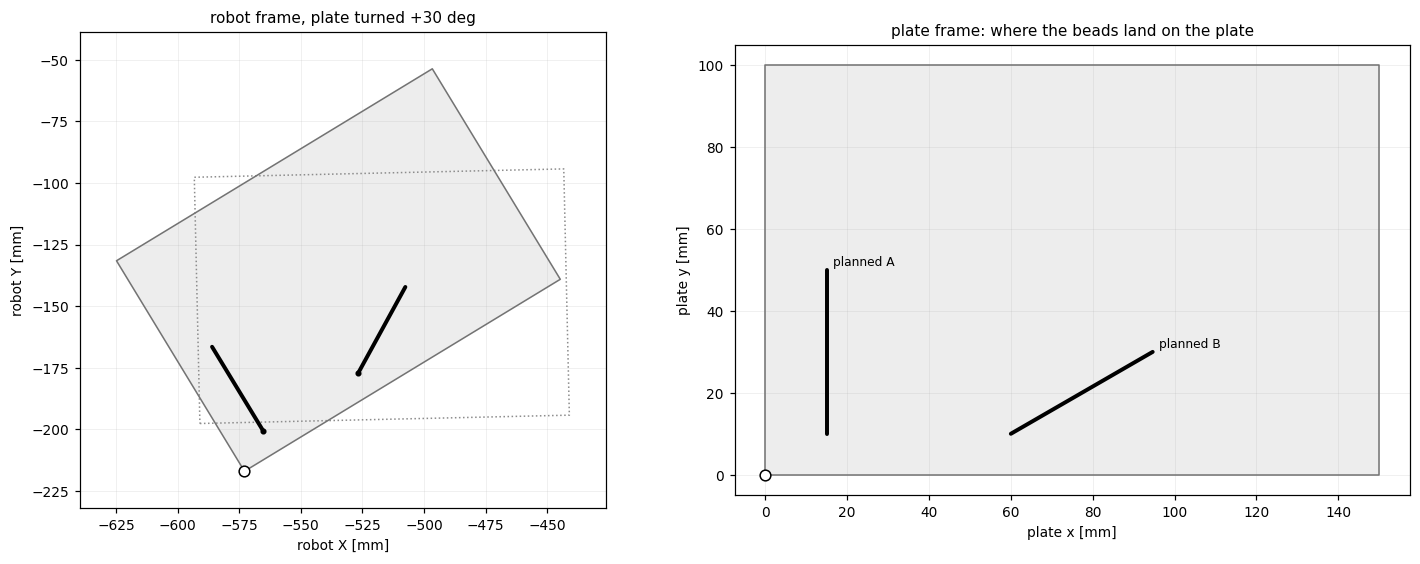

user frame 1 for this turn:  X -572.869  Y -216.996  Z -2.586  W -1.192  P 0.415  R 31.293
bead                            start (robot)                  end (robot)  length
planned A        ( -565.25, -200.66, -2.90) ( -586.02, -166.49, -3.74)   40.00
planned B        ( -526.79, -177.29, -3.23) ( -507.58, -142.21, -3.90)   40.00


In [58]:
PIVOT = robot_points.mean(axis=0)
SCAN_BEADS = []
if have_scan:
    for b in beads:
        path = np.c_[b['path'][:, :2], np.zeros(len(b['path']))]
        SCAN_BEADS.append((b['id'], to_robot_frame(path, T_plate_work)))

preview_beads = []
for bead in BEAD_PLAN:
    phi = np.radians(bead['angle_deg'])
    s = np.array([*bead['start'], 0.0])
    preview_beads.append((f'planned {bead["name"]}', s,
                          s + bead['length_mm'] * np.array([np.cos(phi), np.sin(phi), 0.0])))
if have_scan:
    real = next((b for b in beads if b['id'] == 3), beads[0])
    ends = [to_robot_frame(np.r_[real['path'][k][:2], 0.0], T_plate_work)[0] for k in (0, -1)]
    preview_beads.append((f'scanned bead {real["id"]}', np.r_[ends[0][:2], 0.0],
                          np.r_[ends[1][:2], 0.0]))


def preview(turn_deg=0.0):
    '''The plate turned by turn_deg about its touch centroid, touched again, and
    every bead sent through the new frame.'''
    G = placement(T_robot_plate, PIVOT, turn_deg)
    touched = [G[:3, :3] @ u + G[:3, 3] for u in touch_in_plate.values()]
    T_new = frame_from_three(*touched)

    fig, ax = plt.subplots(1, 2, figsize=(13.5, 5.2))
    rect_plate = plate_rectangle(PLATE_SIZE_MM)
    before = to_robot_frame(rect_plate, T_robot_plate)
    after = to_robot_frame(rect_plate, T_new)
    ax[0].plot(before[:, 0], before[:, 1], ':', color='0.55', lw=1.0)
    ax[0].fill(after[:, 0], after[:, 1], color='0.93', zorder=0)
    ax[0].plot(after[:, 0], after[:, 1], color='0.45', lw=1.0)
    for _, path in SCAN_BEADS:
        world = to_robot_frame(path, G)
        ax[0].plot(world[:, 0], world[:, 1], color='0.65', lw=2.4, solid_capstyle='round')
    for name, s, e in preview_beads:
        pts = to_robot_frame(np.array([s, e]), T_new)
        lw = 2.6 if name.startswith('planned') else 1.2
        ax[0].plot(pts[:, 0], pts[:, 1], 'k-', lw=lw, solid_capstyle='round')
        ax[0].plot(*pts[0, :2], 'ko', ms=3)
    ax[0].plot(*T_new[:2, 3], 'o', mfc='white', mec='black', ms=7)
    span = np.vstack([before[:, :2], after[:, :2]])
    lo, hi = span.min(axis=0) - 15, span.max(axis=0) + 15
    ax[0].set_xlim(lo[0], hi[0])
    ax[0].set_ylim(lo[1], hi[1])
    ax[0].set_aspect('equal')
    ax[0].grid(alpha=0.3, lw=0.4)
    ax[0].set_xlabel('robot X [mm]')
    ax[0].set_ylabel('robot Y [mm]')
    ax[0].set_title(f'robot frame, plate turned {turn_deg:+.0f} deg', fontsize=10)

    ax[1].fill(rect_plate[:, 0], rect_plate[:, 1], color='0.93', zorder=0)
    ax[1].plot(rect_plate[:, 0], rect_plate[:, 1], color='0.45', lw=1.0)
    if have_scan:
        for _, path in SCAN_BEADS:
            ax[1].plot(path[:, 0], path[:, 1], color='0.65', lw=2.4, solid_capstyle='round')
    for name, s, e in preview_beads:
        back = to_robot_frame(to_robot_frame(np.array([s, e]), T_new), invert_rigid(G))
        lw = 2.6 if name.startswith('planned') else 1.2
        ax[1].plot(back[:, 0], back[:, 1], 'k-', lw=lw, solid_capstyle='round')
        ax[1].annotate(name, back[1, :2], xytext=(4, 3), textcoords='offset points', fontsize=8)
    ax[1].plot(0, 0, 'o', mfc='white', mec='black', ms=7)
    ax[1].set_aspect('equal')
    ax[1].grid(alpha=0.3, lw=0.4)
    ax[1].set_xlabel('plate x [mm]')
    ax[1].set_ylabel('plate y [mm]')
    ax[1].set_title('plate frame: where the beads land on the plate', fontsize=10)
    fig.tight_layout()
    plt.show()

    frame = (*T_new[:3, 3], *wpr_from_rotation(T_new[:3, :3]))
    print(f'user frame {USER_FRAME} for this turn:  X {frame[0]:.3f}  Y {frame[1]:.3f}  '
          f'Z {frame[2]:.3f}  W {frame[3]:.3f}  P {frame[4]:.3f}  R {frame[5]:.3f}')
    print(f'{"bead":<16} {"start (robot)":>28} {"end (robot)":>28} {"length":>7}')
    for name, s, e in preview_beads:
        a, b = to_robot_frame(np.array([s, e]), T_new)
        print(f'{name:<16} ({a[0]:8.2f},{a[1]:8.2f},{a[2]:6.2f}) '
              f'({b[0]:8.2f},{b[1]:8.2f},{b[2]:6.2f}) {np.linalg.norm(b - a):7.2f}')


slider = None
if PLATE_TURN_SLIDER:
    try:
        import ipywidgets as widgets
        slider = widgets.FloatSlider(value=PLATE_TURN_DEG, min=-180, max=180, step=5,
                                     description='plate turn', continuous_update=False)
    except ImportError:
        print('ipywidgets is not installed, so there is no slider: '
              f'preview at PLATE_TURN_DEG = {PLATE_TURN_DEG} deg\n')
if slider is not None:
    widgets.interact(preview, turn_deg=slider)
else:
    preview(PLATE_TURN_DEG)

In [59]:
plan = [plan_bead(b, T_robot_plate) for b in BEAD_PLAN]
for bead, p in zip(BEAD_PLAN, plan):
    s, e = p['plate'][1], p['plate'][2]
    rs, re = p['robot'][1], p['robot'][2]
    print(f'bead {bead["name"]}: {bead["angle_deg"]:.0f} deg on the plate, '
          f'{bead["length_mm"]:.0f} mm, schedule {bead["schedule"]}')
    print(f'   plate  start ({s[0]:8.3f},{s[1]:8.3f},{s[2]:7.3f})  end ({e[0]:8.3f},'
          f'{e[1]:8.3f},{e[2]:7.3f})  torch W,P,R {np.round(p["wpr_plate"], 3)}')
    print(f'   robot  start ({rs[0]:8.3f},{rs[1]:8.3f},{rs[2]:7.3f})  end ({re[0]:8.3f},'
          f'{re[1]:8.3f},{re[2]:7.3f})  torch W,P,R {np.round(p["wpr_robot"], 3)}')

program_path = Path('results/bead_plan.ls')
program_path.parent.mkdir(parents=True, exist_ok=True)
program_path.write_text(ls_program('BEADPLAN', BEAD_PLAN, plan))
print(f'\nprogram written to {program_path}, positions in user frame {USER_FRAME}. Check '
      'it on the controller before use: T1 mode, arc disabled, step through the approach first.')

bead A: 90 deg on the plate, 40 mm, schedule 3
   plate  start (  15.000,  10.000,  0.000)  end (  15.000,  50.000,  0.000)  torch W,P,R [  2.501  -4.478 155.143]
   robot  start (-576.198,-187.287, -2.903)  end (-577.106,-147.306, -3.735)  torch W,P,R [  3.76   -4.352 156.344]
bead B: 30 deg on the plate, 40 mm, schedule 3
   plate  start (  60.000,  10.000,  0.000)  end (  94.641,  30.000,  0.000)  torch W,P,R [ 2.501 -4.478 95.143]
   robot  start (-531.210,-186.271, -3.229)  end (-497.033,-165.499, -3.896)  torch W,P,R [ 3.022 -3.328 96.405]

program written to results/bead_plan.ls, positions in user frame 1. Check it on the controller before use: T1 mode, arc disabled, step through the approach first.


### Checking it: many placements, with touch noise

The preview above turns the touches exactly, so the new frame is exact by
construction. On the bench each touch carries its own error. Here the plate is set
down 500 times -- turned anywhere from 0 to 180 degrees, tilted by about a degree,
shifted up to 40 mm -- and each time the three points are touched again with the
spread measured in the nine real touches, three touches per point averaged.

The plate is a rigid body; each placement is a transform $G$ from plate to robot.
The touch points sit at $\mathbf{u}_i$ on the plate, and the robot reads them as

$$\bar{\mathbf{r}}_i = G\,\mathbf{u}_i + \frac{1}{3}\sum_{j=1}^{3}\boldsymbol{\epsilon}_{ij},
\qquad \boldsymbol{\epsilon}_{ij} \sim \mathcal{N}(\mathbf{0},\ \mathrm{diag}(\sigma_x^2, \sigma_y^2, \sigma_z^2))$$

with $\sigma$ [mm] the per-axis spread of one real touch. The frame rebuilt from
those, $\hat T$, sends a bead endpoint $\mathbf{p}$ to $\hat T\mathbf{p}$, which
lands on the plate at

$$\mathbf{p}_{land} = G^{-1}\,\hat T\,\mathbf{p},$$

so the landing error is $\|\mathbf{p}_{land}-\mathbf{p}\|$ [mm]. The same is
computed for the frame from before the move, $T_0$, as if the points had not been
touched again.

touch spread per axis  x 0.114  y 0.216  z 0.017 mm (one touch; three are averaged)


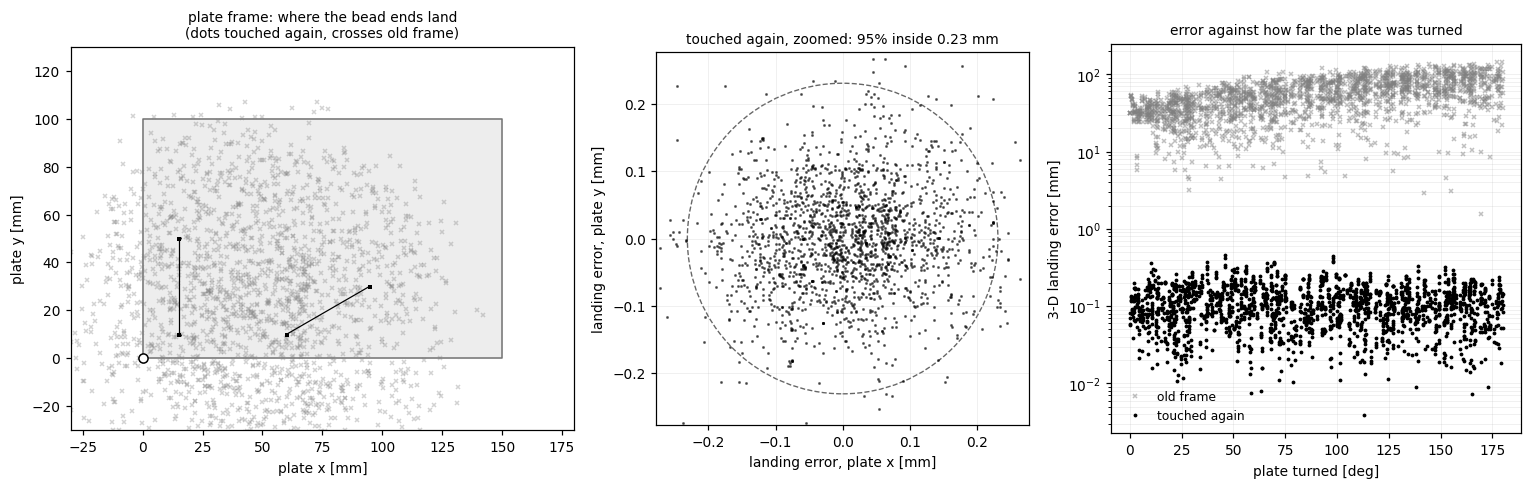

500 placements: turned 0-180 deg, tilted 1 deg sd, shifted up to 40 mm
                  median      95%    worst   [mm, 3-D, over every bead end]
  touched again    0.103    0.232    0.465
      old frame   50.809  105.654  146.235


In [60]:
SIGMA_TOUCH = touch_noise_sd(ROBOT_TOUCH_REPEATS)
TOUCH_POINTS = list(touch_in_plate.values())
print(f'touch spread per axis  x {SIGMA_TOUCH[0]:.3f}  y {SIGMA_TOUCH[1]:.3f}  '
      f'z {SIGMA_TOUCH[2]:.3f} mm (one touch; three are averaged)')

N_TRIALS = 500
rng = np.random.default_rng(11)
trials = []
for _ in range(N_TRIALS):
    angle = rng.uniform(0, 180)
    G = placement(T_robot_plate, PIVOT, angle, tilt_deg=rng.normal(0, 1.0, 2),
                  shift=(*rng.uniform(-40, 40, 2), rng.normal(0, 0.5)))
    T_hat = frame_from_three(*retouch(G, TOUCH_POINTS, SIGMA_TOUCH, rng))
    for name, s, e in preview_beads:
        for tag, p in (('start', s), ('end', e)):
            trials.append(dict(angle=angle, bead=name, point=tag,
                               again=landing(G, T_hat, p) - p,
                               old=landing(G, T_robot_plate, p) - p))

fig, ax = plt.subplots(1, 3, figsize=(14, 4.4), gridspec_kw={'width_ratios': [1.35, 1, 1.1]})
rect_plate = plate_rectangle(PLATE_SIZE_MM)
ax[0].fill(rect_plate[:, 0], rect_plate[:, 1], color='0.93', zorder=0)
ax[0].plot(rect_plate[:, 0], rect_plate[:, 1], color='0.45', lw=1.0)
for _, path in SCAN_BEADS:
    ax[0].plot(path[:, 0], path[:, 1], color='0.65', lw=2.4, solid_capstyle='round')
targets = {name: (s, e) for name, s, e in preview_beads}
for t in trials:
    s, e = targets[t['bead']]
    target = s if t['point'] == 'start' else e
    ax[0].plot(*(target + t['old'])[:2], 'x', color='0.5', ms=2.5, alpha=0.35)
for t in trials:
    s, e = targets[t['bead']]
    target = s if t['point'] == 'start' else e
    ax[0].plot(*(target + t['again'])[:2], '.', color='black', ms=1.5)
for name, s, e in preview_beads:
    ax[0].plot([s[0], e[0]], [s[1], e[1]], 'k-', lw=0.8)
ax[0].plot(0, 0, 'o', mfc='white', mec='black', ms=6)
ax[0].set_xlim(-30, PLATE_SIZE_MM[0] + 30)
ax[0].set_ylim(-30, PLATE_SIZE_MM[1] + 30)
ax[0].set_aspect('equal')
ax[0].set_xlabel('plate x [mm]')
ax[0].set_ylabel('plate y [mm]')
ax[0].set_title('plate frame: where the bead ends land\n(dots touched again, crosses old frame)',
                fontsize=9)

again = np.array([t['again'] for t in trials])
r95 = np.percentile(np.linalg.norm(again[:, :2], axis=1), 95)
ax[1].plot(again[:, 0], again[:, 1], '.', color='black', ms=2, alpha=0.5)
ax[1].add_patch(plt.Circle((0, 0), r95, fill=False, ls='--', color='0.4', lw=0.9))
ax[1].set_xlim(-1.2 * r95, 1.2 * r95)
ax[1].set_ylim(-1.2 * r95, 1.2 * r95)
ax[1].set_aspect('equal')
ax[1].set_xlabel('landing error, plate x [mm]')
ax[1].set_ylabel('landing error, plate y [mm]')
ax[1].set_title(f'touched again, zoomed: 95% inside {r95:.2f} mm', fontsize=9)
ax[1].grid(alpha=0.3, lw=0.4)

angles = np.array([t['angle'] for t in trials])
err_again = np.linalg.norm(again, axis=1)
err_old = np.linalg.norm(np.array([t['old'] for t in trials]), axis=1)
ax[2].semilogy(angles, err_old, 'x', color='0.5', ms=3, alpha=0.5, label='old frame')
ax[2].semilogy(angles, err_again, '.', color='black', ms=3, label='touched again')
ax[2].set_xlabel('plate turned [deg]')
ax[2].set_ylabel('3-D landing error [mm]')
ax[2].set_title('error against how far the plate was turned', fontsize=9)
ax[2].legend(fontsize=8, frameon=False)
ax[2].grid(alpha=0.3, lw=0.4, which='both')
fig.tight_layout()
plt.show()

print(f'{N_TRIALS} placements: turned 0-180 deg, tilted 1 deg sd, shifted up to 40 mm')
print(f'{"":>15} {"median":>8} {"95%":>8} {"worst":>8}   [mm, 3-D, over every bead end]')
for label, err in (('touched again', err_again), ('old frame', err_old)):
    print(f'{label:>15} {np.median(err):>8.3f} {np.percentile(err, 95):>8.3f} {err.max():>8.3f}')

**How to read it.** Left, the plate from its own frame with every simulated landing
of both bead ends: points from the frame touched again sit on the intended ends;
crosses from the old frame scatter across the plate and off it. Middle, the
touched-again landings alone as error vectors: their spread is the touch noise
carried through the frame, and nothing else, since the simulation has no other
error in it. A single touch scatters about twice as much along robot $y$ as along
$x$, but the cloud comes out round, because as the plate turns robot $y$ sweeps
through every direction of the plate. Right, error against the turn: flat when
the points are touched again, growing with the turn when they are not.

What the simulation leaves out is any error in where the touch points are on the
plate, or in the TCP definition. Both give an offset that is the same on every
placement, which touching again cannot see. That is why the nine touches should be
made with one torch orientation.

## 14. Notes and limitations

**Scan-to-scan repeatability.** The same five beads were scanned twice, once
alone (`cloud8`) and again after three more were added beside them (`cloud7`).
Crest height repeated within 0.1 mm. Area did not: `cloud7` read up to 15%
lower, 9% on average, and the fitted slope moved from 0.726 to 0.638, which is a
12% change in $\eta$ from the same metal. About half of it is the datum sitting
0.05 mm higher in the second scan, multiplied across a 9 mm wide bead; the rest
is where the toe and the start and stop ramps were cut. That spread is the
measurement's own noise floor, and it is as large as the difference between the
three beads at $\lambda = 12$. Calibrate $\eta$ from one scan, and keep the scan
settings and the crop fixed across every plate it is compared with.

**What changed for `cloud0.ply`.** Two of the weaknesses above are addressed in
the pipeline itself. The local datum of section 5 removes what the seven-term
model leaves under each bead, which on `cloud0.ply` is 0.3 mm from one side of the
plate to the other. The skirt of section 7 integrates the cross-section past the
mask, so a low bead is no longer cut at the height where the mask happens to stop.
B2 and B3, measured in both scans, are the check: with the two changes their areas
repeat within 2.7% between `nubec.ply` and `cloud0.ply`, and without them within
5.2%. The twelve short beads of `nubec.ply` were measured again with this version.
They move by +0.9% on average and by 4.2% at most, and the slope of the fit on
those twelve goes from 0.651 to 0.656.

**Datum.** Height is reinforcement above the *deformed* plate as it is now, after
welding. Penetration and dilution are below the surface and invisible to the
scanner; a cross-section cut would be needed.

**Scale.** The reference bar checks scale in the plane only. A pin gauge or gauge
block of known height inside the scan would do the same for $z$ — it appears as
one more region, is dropped by the shape gates, and its measured height is read
directly off the height map.

**Length is a weak quantity.** A bead ends on a ramp, not an edge. Where the
gradient criterion places the toe and where a person places a ruler differ by
millimetres, systematically. Use height, width and area for comparisons; use
length only for identification.

**Coverage before parameters.** If the coverage bars in section 4 show a gradient,
beads at the sparse end are truncated and no threshold fixes it. Rescan.

**Thresholds are per setup, not per scan.** `SLOPE_TOE` depends on oxide and
spatter, `CLOSE_MM` on the crest width, `CELL_MM` on point density. They should be
fixed once for a given plate and scanner configuration and then left alone;
tuning them per scan makes the results incomparable between scans, which defeats
the whole purpose of a benchmark.

**This measures, it does not control.** Every number here describes a plate after
the fact. Closing the loop needs the layer-to-layer link back to the run sheet in
section 9, and the baseline block is what any correction must be shown to beat.